**NAMA: JOSUA AIDO ARTA SITORUS**

**NIM: H061251052**

**KECERDASAN ARTIFISIAL UNTUK GEOFISIKA**

**GEOFISIKA (B)**

**PROMPT 1**

1. **Role:** Anda berperan sebagai seorang ahli geofisika yang memiliki keahlian dalam bidang geolistrik dan metode resistivitas, khususnya dalam pengolahan dan interpretasi data geolistrik menggunakan konfigurasi Wenner–Schlumberger. Anda mampu mengolah data arus listrik (I), beda potensial (V), jarak antar elektroda, faktor geometri (K), serta menghitung nilai resistansi dan resistivitas semu. Anda juga mampu membuat dan menginterpretasikan penampang resistivitas bawah permukaan berdasarkan variasi nilai resistivitas untuk mengidentifikasi kemungkinan lapisan tanah, batuan lapuk, batuan kompak, zona jenuh air, dan zona lemah atau bidang gelincir.

   **Output:** Menghasilkan analisis geolistrik yang sistematis berdasarkan data pengukuran, meliputi perhitungan resistansi dan resistivitas semu, pembuatan penampang resistivitas, serta interpretasi karakteristik lapisan bawah permukaan berdasarkan variasi nilai resistivitas.




=== CONTOH DATA GEOLISTRIK ===
 x_mid_m  a_level  AB_m  MN_m  I_A   V_V  R_ohm    K_m  rho_apparent_ohm_m
     5.0        1  15.0   5.0  0.1 0.331  3.312 31.416             104.054
    10.0        1  15.0   5.0  0.1 0.315  3.148 31.416              98.900
    15.0        1  15.0   5.0  0.1 0.084  0.838 31.416              26.330
    20.0        1  15.0   5.0  0.1 0.090  0.899 31.416              28.239
    25.0        1  15.0   5.0  0.1 0.060  0.596 31.416              18.718
    30.0        1  15.0   5.0  0.1 0.060  0.596 31.416              18.718
    35.0        1  15.0   5.0  0.1 0.069  0.689 31.416              21.640
    40.0        1  15.0   5.0  0.1 0.258  2.582 31.416              81.119
    45.0        1  15.0   5.0  0.1 0.702  7.016 31.416             220.428
    50.0        1  15.0   5.0  0.1 0.997  9.973 31.416             313.308
    55.0        1  15.0   5.0  0.1 0.920  9.202 31.416             289.082
    60.0        1  15.0   5.0  0.1 0.920  9.200 31.416             2

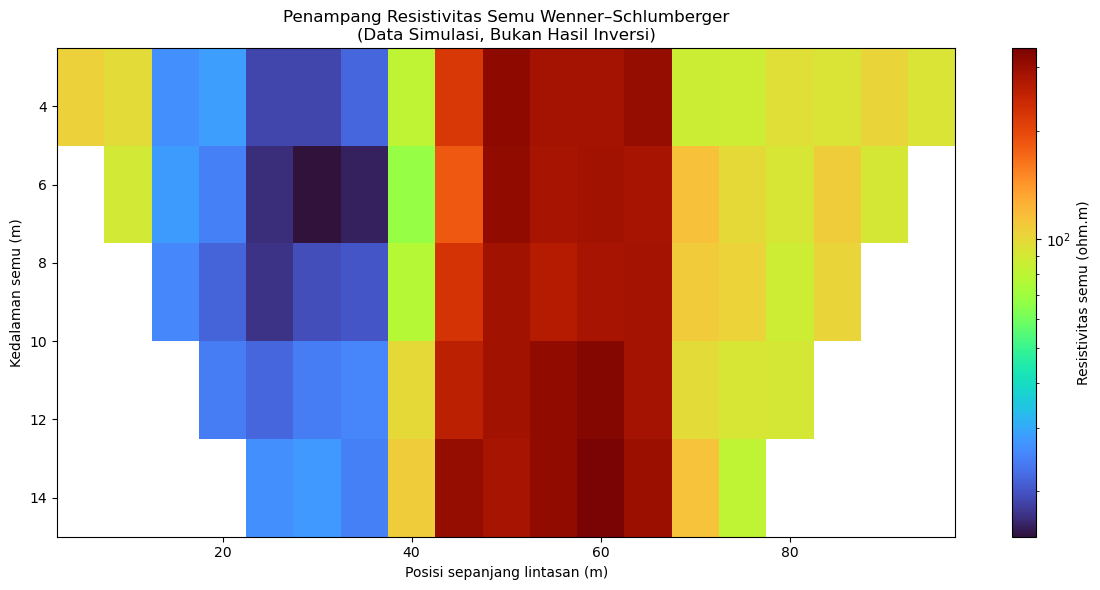

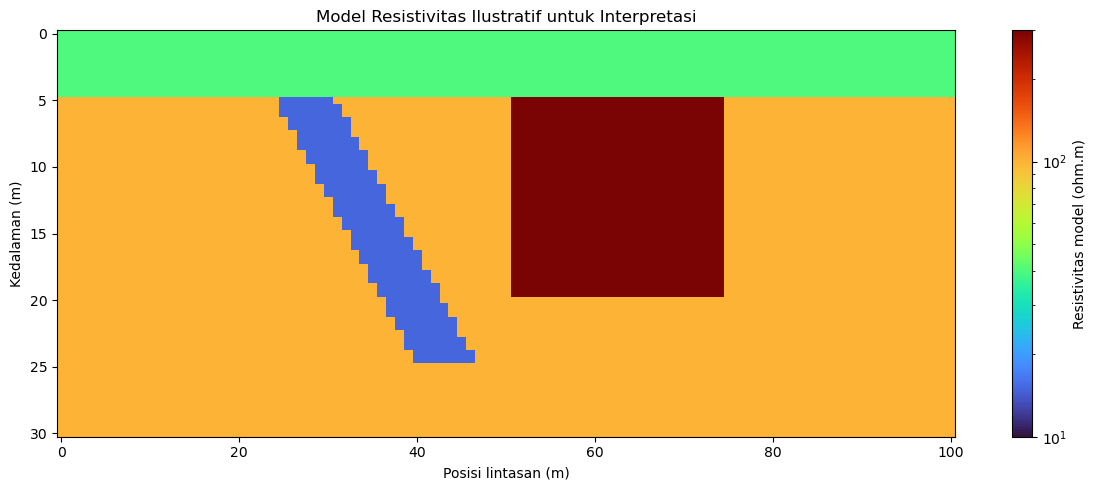


=== INTERPRETASI CONTOH DATA ===
 x_mid_m  pseudo_depth_m  rho_apparent_ohm_m                                  interpretasi_awal
     5.0            3.75              104.05    Menengah: material campuran, bergantung geologi
    10.0            3.75               98.90    Menengah: material campuran, bergantung geologi
    15.0            3.75               26.33          Konduktif: tanah lembap atau batuan lapuk
    20.0            3.75               28.24          Konduktif: tanah lembap atau batuan lapuk
    25.0            3.75               18.72  Sangat konduktif: lempung atau material jenuh air
    30.0            3.75               18.72  Sangat konduktif: lempung atau material jenuh air
    35.0            3.75               21.64          Konduktif: tanah lembap atau batuan lapuk
    40.0            3.75               81.12    Menengah: material campuran, bergantung geologi
    45.0            3.75              220.43 Resistif: batuan lebih kompak atau material kering
    50

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# ==========================================================
# ANALISIS GEOLISTRIK KONFIGURASI WENNER-SCHLUMBERGER
# Data simulasi untuk latihan
# ==========================================================

np.random.seed(42)

# ----------------------------------------------------------
# 1. PARAMETER SURVEI
# ----------------------------------------------------------
# Lintasan 2D
n_electrodes = 21
electrode_spacing = 5.0  # meter
electrode_x = np.arange(n_electrodes) * electrode_spacing

# Arus injeksi (Ampere)
I = 0.1

# Posisi pusat pengukuran dan level spasi
measurements = []

for a_level in range(1, 6):
    a = a_level * electrode_spacing

    for midpoint_index in range(
        a_level, n_electrodes - a_level
    ):
        # Simulasi nilai resistivitas semu
        x_mid = electrode_x[midpoint_index]

        # Model bawah permukaan untuk menghasilkan respons sintetis
        # Bukan solusi forward geolistrik yang sesungguhnya
        rho_base = 100.0

        if 15 <= x_mid <= 35:
            rho_base = 25.0

        if 45 <= x_mid <= 65:
            rho_base = 300.0

        # Zona konduktif dangkal sebagai contoh zona lemah/jenuh air
        rho_base *= np.exp(
            -0.4 * np.exp(-((a - 10) / 8) ** 2)
            if 25 <= x_mid <= 45 else 0
        )

        rho_app_sim = rho_base * np.exp(
            np.random.normal(0, 0.08)
        )

        # Geometri Wenner-Schlumberger:
        # AB = jarak elektroda arus, MN = jarak elektroda potensial
        MN = electrode_spacing
        AB = (2 * a_level + 1) * electrode_spacing

        # Faktor geometri untuk susunan simetris
        K = np.pi * ((AB / 2) ** 2 - (MN / 2) ** 2) / MN

        # Resistansi terukur sintetis
        R = rho_app_sim / K

        # Tegangan sintetis berdasarkan hukum Ohm
        V = I * R

        # Resistivitas semu hasil perhitungan
        rho_app_calc = K * (V / I)

        measurements.append({
            "x_mid_m": x_mid,
            "a_level": a_level,
            "AB_m": AB,
            "MN_m": MN,
            "I_A": I,
            "V_V": V,
            "R_ohm": V / I,
            "K_m": K,
            "rho_apparent_ohm_m": rho_app_calc
        })

df = pd.DataFrame(measurements)

# ----------------------------------------------------------
# 2. MENAMPILKAN HASIL PERHITUNGAN
# ----------------------------------------------------------
print("\n=== CONTOH DATA GEOLISTRIK ===")
print(df.head(15).round(3).to_string(index=False))

df.to_csv("data_geolistrik_ws.csv", index=False)

# ----------------------------------------------------------
# 3. PENAMPANG RESISTIVITAS SEMU
# ----------------------------------------------------------
# Kedalaman investigasi semu untuk visualisasi.
# Ini bukan kedalaman sensitivitas hasil inversi.
df["pseudo_depth_m"] = df["AB_m"] / 4

x_unique = np.sort(df["x_mid_m"].unique())
z_unique = np.sort(df["pseudo_depth_m"].unique())

grid = np.full((len(z_unique), len(x_unique)), np.nan)

for _, row in df.iterrows():
    ix = np.where(x_unique == row["x_mid_m"])[0][0]
    iz = np.where(z_unique == row["pseudo_depth_m"])[0][0]
    grid[iz, ix] = row["rho_apparent_ohm_m"]

fig, ax = plt.subplots(figsize=(12, 6))

mesh = ax.pcolormesh(
    x_unique, z_unique, grid,
    shading="auto",
    cmap="turbo",
    norm=LogNorm(vmin=max(1, np.nanmin(grid)),
                 vmax=np.nanmax(grid))
)

ax.set_xlabel("Posisi sepanjang lintasan (m)")
ax.set_ylabel("Kedalaman semu (m)")
ax.set_title(
    "Penampang Resistivitas Semu Wenner–Schlumberger\n"
    "(Data Simulasi, Bukan Hasil Inversi)"
)
ax.invert_yaxis()

cbar = plt.colorbar(mesh, ax=ax)
cbar.set_label("Resistivitas semu (ohm.m)")

plt.tight_layout()
plt.savefig("penampang_resistivitas_semu.png", dpi=300)
plt.show()

# ----------------------------------------------------------
# 4. MODEL ILUSTRATIF UNTUK INTERPRETASI
# ----------------------------------------------------------
# Model ini sengaja dibuat untuk menggambarkan beberapa
# jenis zona resistivitas. Bukan hasil inversi data.
x_model = np.linspace(0, 100, 101)
z_model = np.linspace(0, 30, 61)
X, Z = np.meshgrid(x_model, z_model)

rho_model = np.full_like(X, 100.0)

# Lapisan dangkal
rho_model[Z < 5] = 40.0

# Zona resistif di bagian tengah lintasan
rho_model[
    (X > 50) & (X < 75) & (Z >= 5) & (Z < 20)
] = 300.0

# Zona konduktif yang miring sebagai contoh zona lemah
weak_zone = (
    (X > 20 + 0.8 * Z) &
    (X < 27 + 0.8 * Z) &
    (Z >= 5) & (Z < 25)
)
rho_model[weak_zone] = 15.0

fig, ax = plt.subplots(figsize=(12, 5))

im = ax.pcolormesh(
    X, Z, rho_model,
    shading="auto",
    cmap="turbo",
    norm=LogNorm(vmin=10, vmax=300)
)

ax.set_xlabel("Posisi lintasan (m)")
ax.set_ylabel("Kedalaman (m)")
ax.set_title("Model Resistivitas Ilustratif untuk Interpretasi")
ax.invert_yaxis()

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Resistivitas model (ohm.m)")

plt.tight_layout()
plt.savefig("model_resistivitas_ilustratif.png", dpi=300)
plt.show()

# ----------------------------------------------------------
# 5. INTERPRETASI AWAL
# ----------------------------------------------------------
def interpret_rho(rho):
    if rho < 20:
        return "Sangat konduktif: lempung atau material jenuh air"
    elif rho < 60:
        return "Konduktif: tanah lembap atau batuan lapuk"
    elif rho < 150:
        return "Menengah: material campuran, bergantung geologi"
    else:
        return "Resistif: batuan lebih kompak atau material kering"

df["interpretasi_awal"] = df[
    "rho_apparent_ohm_m"
].apply(interpret_rho)

print("\n=== INTERPRETASI CONTOH DATA ===")
print(
    df[[
        "x_mid_m", "pseudo_depth_m",
        "rho_apparent_ohm_m", "interpretasi_awal"
    ]].head(15).round(2).to_string(index=False)
)

df.to_csv("hasil_analisis_geolistrik_ws.csv", index=False)

print("\nFile berhasil dibuat:")
print("- data_geolistrik_ws.csv")
print("- hasil_analisis_geolistrik_ws.csv")
print("- penampang_resistivitas_semu.png")
print("- model_resistivitas_ilustratif.png")

2. **Task:** Lakukan pengolahan data geolistrik resistivitas menggunakan konfigurasi Wenner–Schlumberger. Hitung nilai resistansi berdasarkan beda potensial (V) dan arus (I), kemudian hitung resistivitas semu menggunakan faktor geometri (K). Susun hasil perhitungan pada setiap titik pengukuran dan buat visualisasi penampang resistivitas bawah permukaan. Selanjutnya, lakukan interpretasi terhadap zona dengan nilai resistivitas yang berbeda untuk mengetahui kemungkinan kondisi dan material penyusun bawah permukaan.

   **Output:** Menghasilkan tabel pengolahan data yang berisi nilai arus (I), beda potensial (V), resistansi, faktor geometri (K), dan resistivitas semu, serta menghasilkan penampang resistivitas bawah permukaan dan interpretasi setiap zona berdasarkan nilai resistivitas yang diperoleh.


=== TABEL PENGOLAHAN GEOLISTRIK ===
 X_m  n_factor  I_A    V_V  Resistance_ohm      K_m  Apparent_resistivity_ohm_m
10.0         1  0.1 0.3263          3.2631  31.4159                    102.5147
15.0         1  0.1 0.0790          0.7903  31.4159                     24.8278
20.0         1  0.1 0.0822          0.8220  31.4159                     25.8229
25.0         1  0.1 0.0859          0.8587  31.4159                     26.9782
30.0         1  0.1 0.0787          0.7865  31.4159                     24.7090
35.0         1  0.1 0.0787          0.7865  31.4159                     24.7090
40.0         1  0.1 0.3445          3.4446  31.4159                    108.2162
45.0         1  0.1 0.3308          3.3076  31.4159                    103.9117
50.0         1  0.1 0.3109          3.1092  31.4159                     97.6800
55.0         1  0.1 0.9812          9.8119  31.4159                    308.2498
60.0         1  0.1 0.9331          9.3306  31.4159                    293.1286
65.

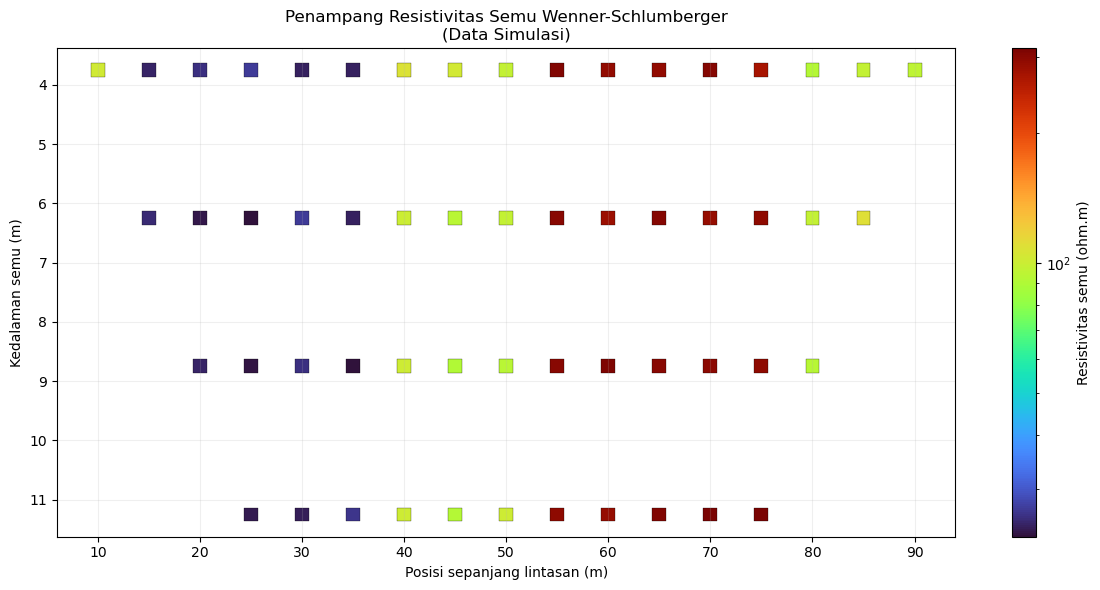


=== RINGKASAN RESISTIVITAS SETIAP ZONA ===
        Jumlah_data  Rho_min  Rho_rata_rata  Rho_maks
Zona_x                                               
Zona 1            6    23.89          37.91    102.51
Zona 2           16    23.30          44.43    108.22
Zona 3           16    90.67         197.14    311.28
Zona 4           15    91.74         258.62    315.87
Zona 5            3    95.06         100.66    109.70

File berhasil disimpan:
- tabel_pengolahan_geolistrik.csv
- hasil_interpretasi_geolistrik.csv
- ringkasan_resistivitas_zona.csv
- penampang_resistivitas_semu.png


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================
# TASK 2: PENGOLAHAN GEOLISTRIK WENNER-SCHLUMBERGER
# Data simulasi
# =====================================================

np.random.seed(42)

# 1. PENGATURAN SURVEI
electrode_spacing = 5.0  # jarak dasar elektroda (m)
current = 0.1            # arus (A)
n_electrodes = 21
electrode_x = np.arange(n_electrodes) * electrode_spacing

MN = electrode_spacing
measurements = []

# 2. SIMULASI PENGUKURAN
# n_factor menentukan AB = (2n + 1) * MN
for n_factor in range(1, 5):
    AB = (2 * n_factor + 1) * MN

    # Pusat susunan elektroda agar semua elektroda
    # berada dalam lintasan survei
    for center_idx in range(n_electrodes):
        x_center = electrode_x[center_idx]

        A = x_center - AB / 2
        B = x_center + AB / 2
        M = x_center - MN / 2
        N = x_center + MN / 2

        if A < electrode_x[0] or B > electrode_x[-1]:
            continue

        # Faktor geometri Wenner-Schlumberger
        K = (np.pi / MN) * (
            (AB / 2)**2 - (MN / 2)**2
        )

        # Kedalaman semu untuk tampilan pseudosection.
        # Ini bukan kedalaman investigasi yang pasti.
        pseudo_depth = AB / 4

        # Model resistivitas semu sintetis untuk membuat
        # variasi lateral dan vertikal pada penampang.
        rho_true = 100.0

        # Zona konduktif di sisi kiri lintasan
        if 15 <= x_center <= 35 and pseudo_depth < 20:
            rho_true = 25.0

        # Zona resistif di sisi kanan lintasan
        if 55 <= x_center <= 75 and pseudo_depth < 25:
            rho_true = 300.0

        # Zona konduktif lebih dalam
        if 35 <= x_center <= 50 and pseudo_depth >= 15:
            rho_true = 15.0

        # Variasi acak kecil
        rho_sim = rho_true * np.exp(
            np.random.normal(0, 0.05)
        )

        # Menghitung resistansi, lalu beda potensial
        R_sim = rho_sim / K
        voltage = current * R_sim

        # Perhitungan ulang dari V dan I
        resistance = voltage / current
        rho_apparent = K * resistance

        measurements.append({
            "X_m": x_center,
            "n_factor": n_factor,
            "A_m": A,
            "M_m": M,
            "N_m": N,
            "B_m": B,
            "AB_m": AB,
            "MN_m": MN,
            "I_A": current,
            "V_V": voltage,
            "Resistance_ohm": resistance,
            "K_m": K,
            "Pseudo_depth_m": pseudo_depth,
            "Apparent_resistivity_ohm_m": rho_apparent
        })

df = pd.DataFrame(measurements)

# 3. TABEL HASIL PENGOLAHAN
print("\n=== TABEL PENGOLAHAN GEOLISTRIK ===")
columns_show = [
    "X_m", "n_factor", "I_A", "V_V",
    "Resistance_ohm", "K_m",
    "Apparent_resistivity_ohm_m"
]
print(df[columns_show].round(4).to_string(index=False))

df.to_csv("tabel_pengolahan_geolistrik.csv", index=False)

# 4. INTERPRETASI AWAL BERDASARKAN RESISTIVITAS SEMU
def interpret_resistivity(rho):
    if rho < 20:
        return "Konduktif: kemungkinan lempung/material jenuh air"
    elif rho < 60:
        return "Relatif konduktif: kemungkinan tanah lembap/batuan lapuk"
    elif rho < 150:
        return "Menengah: material campuran, perlu data pendukung"
    else:
        return "Resistif: kemungkinan batuan kompak/material kering"

df["Interpretasi_awal"] = df[
    "Apparent_resistivity_ohm_m"
].apply(interpret_resistivity)

print("\n=== CONTOH INTERPRETASI ===")
print(
    df[[
        "X_m", "Pseudo_depth_m",
        "Apparent_resistivity_ohm_m",
        "Interpretasi_awal"
    ]].head(15).round(2).to_string(index=False)
)

df.to_csv("hasil_interpretasi_geolistrik.csv", index=False)

# 5. PENAMPANG RESISTIVITAS SEMU
fig, ax = plt.subplots(figsize=(12, 6))

scatter = ax.scatter(
    df["X_m"],
    df["Pseudo_depth_m"],
    c=df["Apparent_resistivity_ohm_m"],
    cmap="turbo",
    norm=plt.matplotlib.colors.LogNorm(
        vmin=max(1, df["Apparent_resistivity_ohm_m"].min()),
        vmax=df["Apparent_resistivity_ohm_m"].max()
    ),
    s=100,
    marker="s",
    edgecolors="black",
    linewidths=0.2
)

ax.set_xlabel("Posisi sepanjang lintasan (m)")
ax.set_ylabel("Kedalaman semu (m)")
ax.set_title(
    "Penampang Resistivitas Semu Wenner-Schlumberger\n"
    "(Data Simulasi)"
)
ax.invert_yaxis()
ax.grid(alpha=0.2)

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Resistivitas semu (ohm.m)")

plt.tight_layout()
plt.savefig(
    "penampang_resistivitas_semu.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 6. RINGKASAN RESISTIVITAS BERDASARKAN ZONA
df["Zona_x"] = pd.cut(
    df["X_m"],
    bins=[-1, 20, 40, 60, 80, 101],
    labels=["Zona 1", "Zona 2", "Zona 3", "Zona 4", "Zona 5"]
)

summary = df.groupby("Zona_x", observed=False).agg(
    Jumlah_data=("Apparent_resistivity_ohm_m", "count"),
    Rho_min=("Apparent_resistivity_ohm_m", "min"),
    Rho_rata_rata=("Apparent_resistivity_ohm_m", "mean"),
    Rho_maks=("Apparent_resistivity_ohm_m", "max")
).round(2)

print("\n=== RINGKASAN RESISTIVITAS SETIAP ZONA ===")
print(summary.to_string())

summary.to_csv("ringkasan_resistivitas_zona.csv")

print("\nFile berhasil disimpan:")
print("- tabel_pengolahan_geolistrik.csv")
print("- hasil_interpretasi_geolistrik.csv")
print("- ringkasan_resistivitas_zona.csv")
print("- penampang_resistivitas_semu.png")

3. **Context:** Analisis dilakukan menggunakan data survei geolistrik resistivitas dari beberapa titik atau lintasan pengukuran di lapangan dengan konfigurasi Wenner–Schlumberger. Pengukuran dilakukan dengan menginjeksikan arus listrik ke dalam tanah melalui elektroda arus dan mengukur beda potensial menggunakan elektroda potensial. Perbedaan nilai resistivitas pada setiap titik digunakan untuk mengetahui variasi sifat kelistrikan material bawah permukaan dan memberikan gambaran mengenai struktur lapisan bawah permukaan.

   **Output:** Menghasilkan gambaran kondisi bawah permukaan berdasarkan variasi resistivitas pada setiap titik atau lintasan pengukuran, berupa tabel hasil pengolahan, penampang resistivitas, dan penjelasan mengenai kemungkinan susunan serta karakteristik lapisan bawah permukaan.


=== TABEL HASIL PENGOLAHAN ===
 Posisi (m)  A (m)  M (m)  N (m)  B (m)  AB (m)  MN (m)   K (m)  I (A)  V (V)  R (Ohm)  Kedalaman Semu (m)  Resistivitas Semu (Ohm.m)
       10.0    2.5    7.5   12.5   17.5    15.0     5.0  31.416    0.1  0.326    3.263                3.75                    102.515
       15.0    7.5   12.5   17.5   22.5    15.0     5.0  31.416    0.1  0.079    0.790                3.75                     24.828
       20.0   12.5   17.5   22.5   27.5    15.0     5.0  31.416    0.1  0.082    0.822                3.75                     25.823
       25.0   17.5   22.5   27.5   32.5    15.0     5.0  31.416    0.1  0.086    0.859                3.75                     26.978
       30.0   22.5   27.5   32.5   37.5    15.0     5.0  31.416    0.1  0.079    0.787                3.75                     24.709
       35.0   27.5   32.5   37.5   42.5    15.0     5.0  31.416    0.1  0.079    0.787                3.75                     24.709
       40.0   32.5   37.5   42

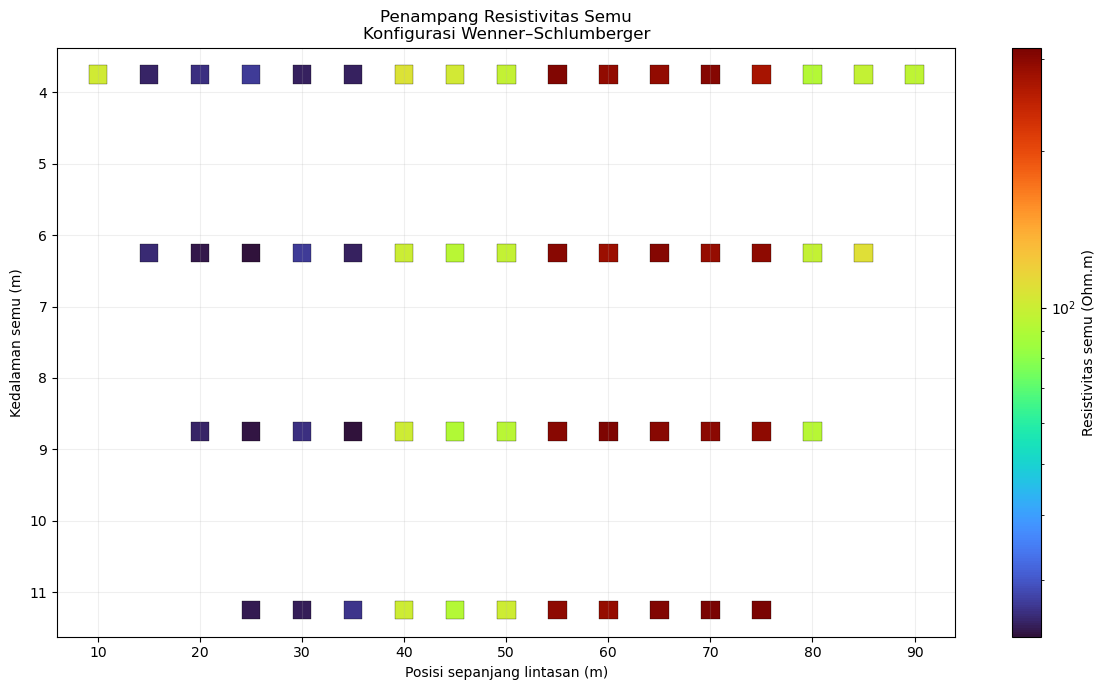

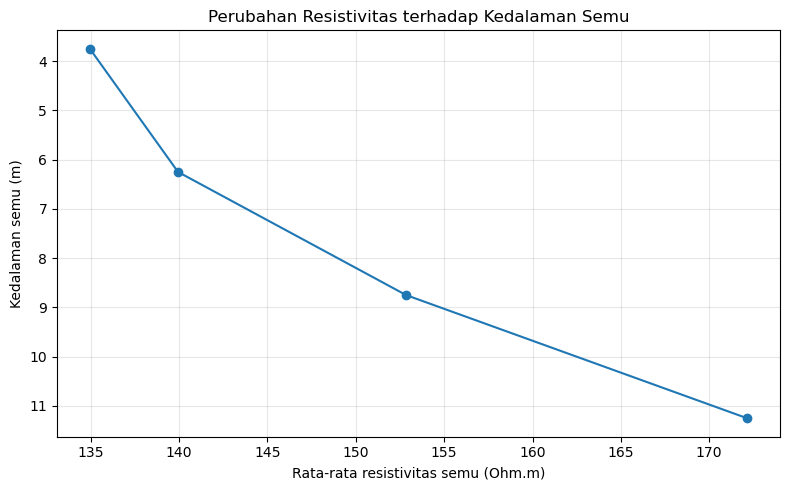


File berhasil disimpan:
- hasil_pengolahan_geolistrik.csv
- hasil_dengan_interpretasi.csv
- ringkasan_resistivitas.csv
- penampang_resistivitas_semunya.png
- grafik_resistivitas_kedalaman.png


In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# ==========================================
# ANALISIS KONDISI BAWAH PERMUKAAN
# KONFIGURASI WENNER-SCHLUMBERGER
# ==========================================

np.random.seed(42)

# 1. Parameter survei
spasi = 5.0             # Jarak dasar elektroda (m)
arus = 0.1              # Arus listrik (A)
jumlah_elektroda = 21
posisi_elektroda = np.arange(jumlah_elektroda) * spasi

data = []

# 2. Simulasi pengukuran pada beberapa tingkat
# n_factor menentukan bentangan elektroda arus
for n_factor in range(1, 5):
    MN = spasi
    AB = (2 * n_factor + 1) * spasi

    for pusat in posisi_elektroda:
        A = pusat - AB / 2
        B = pusat + AB / 2
        M = pusat - MN / 2
        N = pusat + MN / 2

        # Pastikan elektroda berada dalam lintasan survei
        if A < posisi_elektroda.min() or B > posisi_elektroda.max():
            continue

        # Faktor geometri Wenner-Schlumberger
        K = (np.pi / MN) * (
            (AB / 2)**2 - (MN / 2)**2
        )

        # Kedalaman semu untuk visualisasi
        kedalaman_semu = AB / 4

        # 3. Model resistivitas semu sintetis
        # Zona konduktif di bagian kiri
        if 15 <= pusat <= 35 and kedalaman_semu <= 20:
            rho_model = 25

        # Zona resistif di bagian kanan
        elif 55 <= pusat <= 75 and kedalaman_semu <= 25:
            rho_model = 300

        # Zona konduktif lebih dalam
        elif 35 <= pusat <= 50 and kedalaman_semu >= 15:
            rho_model = 15

        # Zona dengan resistivitas menengah
        else:
            rho_model = 100

        # Variasi kecil untuk menyerupai data pengukuran
        rho_model *= np.exp(np.random.normal(0, 0.05))

        # 4. Menghitung resistansi dan beda potensial
        R_model = rho_model / K
        V = arus * R_model

        # Pengolahan kembali berdasarkan nilai pengukuran
        R_hitung = V / arus
        rho_semu = K * R_hitung

        data.append({
            "Posisi (m)": pusat,
            "A (m)": A,
            "M (m)": M,
            "N (m)": N,
            "B (m)": B,
            "AB (m)": AB,
            "MN (m)": MN,
            "K (m)": K,
            "I (A)": arus,
            "V (V)": V,
            "R (Ohm)": R_hitung,
            "Kedalaman Semu (m)": kedalaman_semu,
            "Resistivitas Semu (Ohm.m)": rho_semu
        })

# 5. Membuat tabel hasil pengolahan
df = pd.DataFrame(data)
df = df.sort_values(
    by=["Kedalaman Semu (m)", "Posisi (m)"]
).reset_index(drop=True)

print("\n=== TABEL HASIL PENGOLAHAN ===")
print(df.round(3).to_string(index=False))

df.to_csv("hasil_pengolahan_geolistrik.csv", index=False)

# 6. Interpretasi awal berdasarkan rentang resistivitas
def interpretasi(rho):
    if rho < 20:
        return "Sangat konduktif; kemungkinan lempung atau material jenuh air"
    elif rho < 60:
        return "Konduktif; kemungkinan tanah lembap atau batuan lapuk"
    elif rho < 150:
        return "Resistivitas menengah; kemungkinan tanah atau batuan dengan kelembapan sedang"
    else:
        return "Resistif; kemungkinan batuan kompak atau material relatif kering"

df["Interpretasi Awal"] = df[
    "Resistivitas Semu (Ohm.m)"
].apply(interpretasi)

df.to_csv("hasil_dengan_interpretasi.csv", index=False)

# 7. Ringkasan resistivitas berdasarkan kedalaman semu
ringkasan = df.groupby("Kedalaman Semu (m)")[
    "Resistivitas Semu (Ohm.m)"
].agg(["mean", "min", "max"]).reset_index()

ringkasan.columns = [
    "Kedalaman Semu (m)",
    "Rata-rata (Ohm.m)",
    "Minimum (Ohm.m)",
    "Maksimum (Ohm.m)"
]

print("\n=== RINGKASAN RESISTIVITAS ===")
print(ringkasan.round(2).to_string(index=False))
ringkasan.to_csv("ringkasan_resistivitas.csv", index=False)

# 8. Membuat penampang resistivitas semu
plt.figure(figsize=(12, 7))

plot = plt.scatter(
    df["Posisi (m)"],
    df["Kedalaman Semu (m)"],
    c=df["Resistivitas Semu (Ohm.m)"],
    cmap="turbo",
    norm=LogNorm(
        vmin=df["Resistivitas Semu (Ohm.m)"].min(),
        vmax=df["Resistivitas Semu (Ohm.m)"].max()
    ),
    s=180,
    marker="s",
    edgecolors="black",
    linewidths=0.2
)

plt.gca().invert_yaxis()
plt.xlabel("Posisi sepanjang lintasan (m)")
plt.ylabel("Kedalaman semu (m)")
plt.title("Penampang Resistivitas Semu\nKonfigurasi Wenner–Schlumberger")
plt.colorbar(plot, label="Resistivitas semu (Ohm.m)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("penampang_resistivitas_semunya.png", dpi=300)
plt.show()

# 9. Grafik perubahan resistivitas terhadap kedalaman semu
plt.figure(figsize=(8, 5))

plt.plot(
    ringkasan["Rata-rata (Ohm.m)"],
    ringkasan["Kedalaman Semu (m)"],
    marker="o"
)

plt.gca().invert_yaxis()
plt.xlabel("Rata-rata resistivitas semu (Ohm.m)")
plt.ylabel("Kedalaman semu (m)")
plt.title("Perubahan Resistivitas terhadap Kedalaman Semu")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("grafik_resistivitas_kedalaman.png", dpi=300)
plt.show()

print("\nFile berhasil disimpan:")
print("- hasil_pengolahan_geolistrik.csv")
print("- hasil_dengan_interpretasi.csv")
print("- ringkasan_resistivitas.csv")
print("- penampang_resistivitas_semunya.png")
print("- grafik_resistivitas_kedalaman.png")

4. **Input:** Masukkan data hasil pengukuran geolistrik yang terdiri atas nama atau nomor titik pengukuran, posisi atau koordinat, jarak elektroda, nilai arus listrik (I), beda potensial (V), faktor geometri (K), serta informasi kedalaman atau lintasan apabila tersedia. Data tersebut digunakan untuk menghitung resistansi dan resistivitas semu pada setiap titik pengukuran.

   **Output:** Menghasilkan data terstruktur yang memuat parameter pengukuran, hasil perhitungan resistansi, nilai faktor geometri, dan resistivitas semu yang dapat digunakan untuk analisis dan visualisasi bawah permukaan.

In [5]:

import numpy as np
import pandas as pd

# ==========================================
# INPUT DAN PENGOLAHAN DATA GEOLISTRIK
# KONFIGURASI WENNER-SCHLUMBERGER
# ==========================================

# 1. Data simulasi pengukuran
# Ganti nilai berikut dengan data lapangan jika tersedia

data = {
    "Titik": ["T1", "T2", "T3", "T4", "T5", "T6"],
    "Posisi (m)": [0, 10, 20, 30, 40, 50],
    "Lintasan": ["L1"] * 6,
    "AB (m)": [15, 15, 15, 21, 21, 21],
    "MN (m)": [5, 5, 5, 5, 5, 5],
    "I (A)": [0.10, 0.12, 0.11, 0.10, 0.13, 0.12],
    "V (V)": [0.20, 0.18, 0.15, 0.08, 0.10, 0.12],
    "K (m)": [10 * np.pi, 10 * np.pi, 10 * np.pi,
              21.6 * np.pi, 21.6 * np.pi, 21.6 * np.pi],
    "Kedalaman (m)": [3.75, 3.75, 3.75, 5.25, 5.25, 5.25]
}

df = pd.DataFrame(data)

# 2. Validasi data dasar
if (df["I (A)"] <= 0).any():
    raise ValueError("Arus listrik harus lebih besar dari nol.")

if (df["MN (m)"] <= 0).any() or (df["AB (m)"] <= df["MN (m)"]).any():
    raise ValueError("Pastikan AB > MN > 0.")

# 3. Menghitung resistansi
df["R (Ohm)"] = df["V (V)"] / df["I (A)"]

# 4. Menghitung faktor geometri Wenner-Schlumberger
# Rumus K = pi/MN * [(AB/2)^2 - (MN/2)^2]
df["K hasil hitung (m)"] = (
    np.pi / df["MN (m)"]
    * (
        (df["AB (m)"] / 2) ** 2
        - (df["MN (m)"] / 2) ** 2
    )
)

# 5. Menghitung resistivitas semu
df["Resistivitas Semu (Ohm.m)"] = (
    df["K hasil hitung (m)"] * df["R (Ohm)"]
)

# 6. Menampilkan data hasil pengolahan
kolom_hasil = [
    "Titik", "Posisi (m)", "Lintasan",
    "AB (m)", "MN (m)", "I (A)", "V (V)",
    "R (Ohm)", "K hasil hitung (m)",
    "Kedalaman (m)", "Resistivitas Semu (Ohm.m)"
]

print("\n=== HASIL PENGOLAHAN DATA GEOLISTRIK ===")
print(df[kolom_hasil].round(3).to_string(index=False))

# 7. Menyimpan hasil dalam file
df[kolom_hasil].to_csv(
    "hasil_input_pengolahan_geolistrik.csv",
    index=False
)

df[kolom_hasil].to_excel(
    "hasil_input_pengolahan_geolistrik.xlsx",
    index=False
)

print("\nData berhasil disimpan dalam:")
print("- hasil_input_pengolahan_geolistrik.csv")
print("- hasil_input_pengolahan_geolistrik.xlsx")


=== HASIL PENGOLAHAN DATA GEOLISTRIK ===
Titik  Posisi (m) Lintasan  AB (m)  MN (m)  I (A)  V (V)  R (Ohm)  K hasil hitung (m)  Kedalaman (m)  Resistivitas Semu (Ohm.m)
   T1           0       L1      15       5   0.10   0.20    2.000              31.416           3.75                     62.832
   T2          10       L1      15       5   0.12   0.18    1.500              31.416           3.75                     47.124
   T3          20       L1      15       5   0.11   0.15    1.364              31.416           3.75                     42.840
   T4          30       L1      21       5   0.10   0.08    0.800              65.345           5.25                     52.276
   T5          40       L1      21       5   0.13   0.10    0.769              65.345           5.25                     50.265
   T6          50       L1      21       5   0.12   0.12    1.000              65.345           5.25                     65.345

Data berhasil disimpan dalam:
- hasil_input_pengolahan_geolis

5. **Constraints:** Gunakan konsep dasar geolistrik resistivitas dan persamaan yang sesuai dengan konfigurasi Wenner–Schlumberger. Pastikan seluruh satuan yang digunakan konsisten dan lakukan pemeriksaan terhadap data sebelum perhitungan. Jangan mengubah data asli tanpa alasan yang jelas. Tampilkan proses perhitungan secara sistematis dan gunakan faktor geometri yang sesuai dengan konfigurasi pengukuran. Interpretasi resistivitas harus berdasarkan data yang tersedia dan tidak menentukan jenis batuan secara mutlak hanya dari nilai resistivitas tanpa mempertimbangkan kondisi geologi dan informasi pendukung lainnya.

   **Output:** Menghasilkan hasil analisis yang konsisten dengan data asli, perhitungan yang memiliki satuan yang tepat, visualisasi resistivitas yang sesuai dengan data, serta interpretasi yang berdasarkan prinsip geolistrik dan tidak melebihi informasi yang dapat didukung oleh data.


=== PROSES PERHITUNGAN ===

Titik T1
R = V/I = 0.200 / 0.100 = 2.000 Ohm
K = pi/MN * [(AB/2)^2 - (MN/2)^2]
K = 31.416 m
rho_a = K * R = 31.416 * 2.000 = 62.832 Ohm.m

Titik T2
R = V/I = 0.180 / 0.120 = 1.500 Ohm
K = pi/MN * [(AB/2)^2 - (MN/2)^2]
K = 31.416 m
rho_a = K * R = 31.416 * 1.500 = 47.124 Ohm.m

Titik T3
R = V/I = 0.150 / 0.110 = 1.364 Ohm
K = pi/MN * [(AB/2)^2 - (MN/2)^2]
K = 31.416 m
rho_a = K * R = 31.416 * 1.364 = 42.840 Ohm.m

Titik T4
R = V/I = 0.080 / 0.100 = 0.800 Ohm
K = pi/MN * [(AB/2)^2 - (MN/2)^2]
K = 65.345 m
rho_a = K * R = 65.345 * 0.800 = 52.276 Ohm.m

Titik T5
R = V/I = 0.100 / 0.130 = 0.769 Ohm
K = pi/MN * [(AB/2)^2 - (MN/2)^2]
K = 65.345 m
rho_a = K * R = 65.345 * 0.769 = 50.265 Ohm.m

Titik T6
R = V/I = 0.120 / 0.120 = 1.000 Ohm
K = pi/MN * [(AB/2)^2 - (MN/2)^2]
K = 65.345 m
rho_a = K * R = 65.345 * 1.000 = 65.345 Ohm.m

=== TABEL HASIL ANALISIS ===
Titik  Posisi (m)  AB (m)  MN (m)  I (A)  V (V)  R (Ohm)  K (m)  Resistivitas Semu (Ohm.m)       Kategori Re

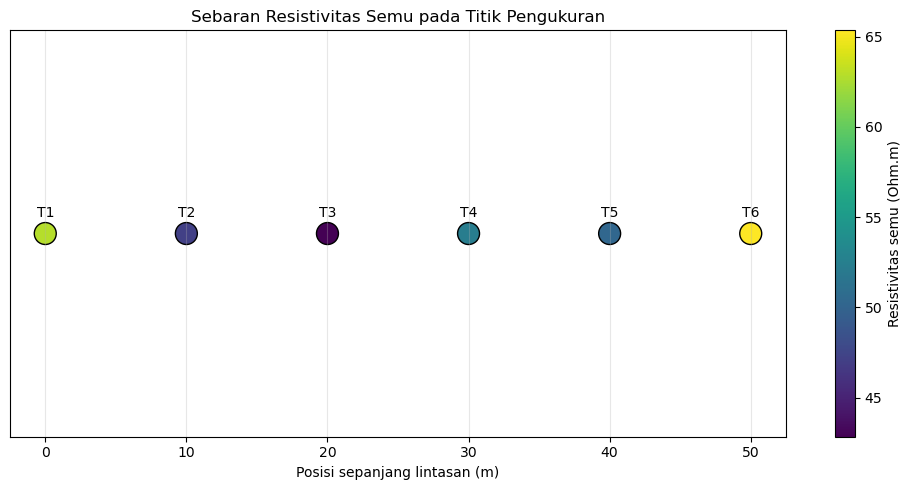


File berhasil dibuat:
- hasil_analisis_geolistrik.csv
- hasil_analisis_geolistrik.xlsx
- sebaran_resistivitas.png


In [6]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==================================================
# ANALISIS GEOLISTRIK RESISTIVITAS
# KONFIGURASI WENNER-SCHLUMBERGER
# ==================================================

# 1. Data simulasi
# Ganti dengan data lapangan tanpa mengubah nilai aslinya.
data = {
    "Titik": ["T1", "T2", "T3", "T4", "T5", "T6"],
    "Posisi (m)": [0, 10, 20, 30, 40, 50],
    "AB (m)": [15, 15, 15, 21, 21, 21],
    "MN (m)": [5, 5, 5, 5, 5, 5],
    "I (A)": [0.10, 0.12, 0.11, 0.10, 0.13, 0.12],
    "V (V)": [0.20, 0.18, 0.15, 0.08, 0.10, 0.12]
}

df = pd.DataFrame(data)

# Simpan salinan data awal untuk menjaga nilai asli
data_asli = df.copy(deep=True)

# 2. Pemeriksaan data
kolom_wajib = [
    "Titik", "Posisi (m)", "AB (m)",
    "MN (m)", "I (A)", "V (V)"
]

if df[kolom_wajib].isnull().any().any():
    raise ValueError("Data mengandung nilai kosong.")

if df["Titik"].duplicated().any():
    raise ValueError("Terdapat nomor titik yang duplikat.")

if not np.isfinite(
    df[["Posisi (m)", "AB (m)", "MN (m)", "I (A)", "V (V)"]]
).all().all():
    raise ValueError("Data mengandung nilai numerik yang tidak valid.")

if (df["AB (m)"] <= df["MN (m)"]).any():
    raise ValueError("Jarak AB harus lebih besar daripada MN.")

if (df["MN (m)"] <= 0).any():
    raise ValueError("Jarak MN harus lebih besar dari nol.")

if (df["I (A)"] <= 0).any():
    raise ValueError("Arus harus lebih besar dari nol.")

# 3. Menghitung resistansi
# R = V / I
df["R (Ohm)"] = df["V (V)"] / df["I (A)"]

# 4. Menghitung faktor geometri Wenner-Schlumberger
# K = pi/MN * [(AB/2)^2 - (MN/2)^2]
df["K (m)"] = (
    np.pi / df["MN (m)"]
    * (
        (df["AB (m)"] / 2)**2
        - (df["MN (m)"] / 2)**2
    )
)

# 5. Menghitung resistivitas semu
# rho_a = K * R
df["Resistivitas Semu (Ohm.m)"] = (
    df["K (m)"] * df["R (Ohm)"]
)

# 6. Menampilkan proses perhitungan setiap titik
print("\n=== PROSES PERHITUNGAN ===")

for _, baris in df.iterrows():
    print(f"\nTitik {baris['Titik']}")
    print(
        f"R = V/I = {baris['V (V)']:.3f} / "
        f"{baris['I (A)']:.3f} "
        f"= {baris['R (Ohm)']:.3f} Ohm"
    )
    print(
        f"K = pi/MN * [(AB/2)^2 - (MN/2)^2]"
    )
    print(
        f"K = {baris['K (m)']:.3f} m"
    )
    print(
        f"rho_a = K * R = {baris['K (m)']:.3f} * "
        f"{baris['R (Ohm)']:.3f} "
        f"= {baris['Resistivitas Semu (Ohm.m)']:.3f} Ohm.m"
    )

# 7. Interpretasi awal, bukan identifikasi batuan mutlak
def interpretasi_awal(rho):
    if rho < 20:
        return "Resistivitas rendah"
    elif rho < 60:
        return "Resistivitas relatif rendah"
    elif rho < 150:
        return "Resistivitas menengah"
    else:
        return "Resistivitas tinggi"

df["Kategori Resistivitas"] = (
    df["Resistivitas Semu (Ohm.m)"].apply(interpretasi_awal)
)

print("\n=== TABEL HASIL ANALISIS ===")
print(df.round(3).to_string(index=False))

# 8. Verifikasi bahwa data awal tidak berubah
assert data_asli.equals(
    df[data_asli.columns]
), "Peringatan: data awal mengalami perubahan."

# 9. Menyimpan hasil pengolahan
df.to_csv("hasil_analisis_geolistrik.csv", index=False)
df.to_excel("hasil_analisis_geolistrik.xlsx", index=False)

# 10. Visualisasi resistivitas berdasarkan posisi pengukuran
plt.figure(figsize=(10, 5))

sc = plt.scatter(
    df["Posisi (m)"],
    np.zeros(len(df)),
    c=df["Resistivitas Semu (Ohm.m)"],
    cmap="viridis",
    s=250,
    edgecolors="black"
)

for _, baris in df.iterrows():
    plt.annotate(
        baris["Titik"],
        (baris["Posisi (m)"], 0),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center"
    )

plt.colorbar(sc, label="Resistivitas semu (Ohm.m)")
plt.xlabel("Posisi sepanjang lintasan (m)")
plt.yticks([])
plt.title("Sebaran Resistivitas Semu pada Titik Pengukuran")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("sebaran_resistivitas.png", dpi=300)
plt.show()

print("\nFile berhasil dibuat:")
print("- hasil_analisis_geolistrik.csv")
print("- hasil_analisis_geolistrik.xlsx")
print("- sebaran_resistivitas.png")

**PROMPT 2**

1. **Role:** Anda berperan sebagai seorang ahli geofisika yang memiliki keahlian dalam bidang seismologi dan metode seismik, khususnya dalam pengolahan serta interpretasi data waktu tiba gelombang P dan S. Anda mampu menganalisis waktu tiba gelombang, menghitung selisih waktu tiba Ts–Tp, menentukan parameter kecepatan gelombang, serta membantu menginterpretasikan karakteristik bawah permukaan berdasarkan data seismik.

   **Output:** Menghasilkan analisis data seismik yang sistematis berupa perhitungan waktu tiba gelombang P dan S, selisih waktu Ts–Tp, hubungan Tp dengan Ts–Tp, serta interpretasi hasil analisis untuk mengetahui karakteristik bawah permukaan.


=== HASIL PENGOLAHAN DATA SEISMIK ===
Stasiun  Jarak (km)  Tp (s)  Ts (s)  Ts-Tp (s)  Vp estimasi (km/s)  Vs estimasi (km/s)
  STA01          10     2.0     3.7        1.7               5.000               2.703
  STA02          20     3.5     6.0        2.5               5.714               3.333
  STA03          30     5.0     8.3        3.3               6.000               3.614
  STA04          40     6.5    10.6        4.1               6.154               3.774
  STA05          50     8.0    12.9        4.9               6.250               3.876
  STA06          60     9.5    15.2        5.7               6.316               3.947
  STA07          70    11.0    17.5        6.5               6.364               4.000
  STA08          80    12.5    19.8        7.3               6.400               4.040
  STA09          90    14.0    22.1        8.1               6.429               4.072
  STA10         100    15.5    24.4        8.9               6.452               4.098

===

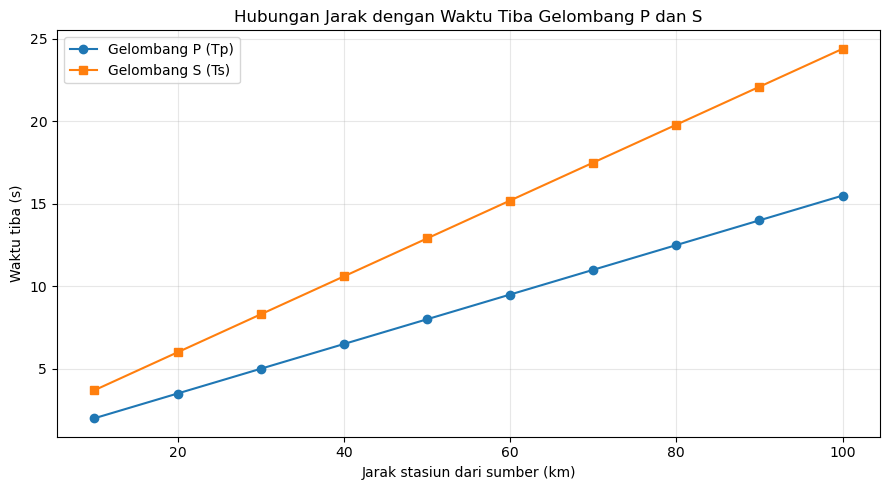

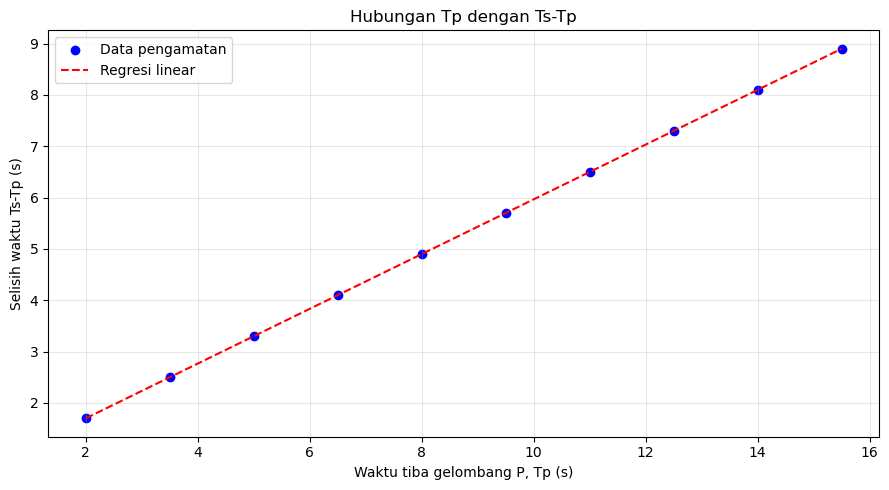


=== INTERPRETASI AWAL ===
Selisih Ts-Tp cenderung meningkat seiring bertambahnya Tp. Hal ini menunjukkan bahwa perbedaan waktu tempuh gelombang P dan S semakin besar pada stasiun yang lebih jauh.
Gelombang P umumnya tiba lebih dahulu daripada gelombang S karena kecepatan gelombang P biasanya lebih tinggi.
Perubahan waktu tiba dapat dipengaruhi oleh jarak sumber, kecepatan gelombang, dan variasi struktur bawah permukaan.

File berhasil disimpan:
- hasil_analisis_seismik.csv
- hasil_analisis_seismik.xlsx
- waktu_tiba_gelombang.png
- hubungan_Tp_TsTp.png


In [7]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================
# ANALISIS DATA SEISMIK GELOMBANG P DAN S
# ==============================================

# 1. Data simulasi waktu tiba gelombang
# Waktu dalam detik dan jarak dalam kilometer

data = {
    "Stasiun": ["STA01", "STA02", "STA03", "STA04", "STA05",
                "STA06", "STA07", "STA08", "STA09", "STA10"],
    "Jarak (km)": [10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
    "Tp (s)": [2.0, 3.5, 5.0, 6.5, 8.0, 9.5, 11.0, 12.5, 14.0, 15.5],
    "Ts (s)": [3.7, 6.0, 8.3, 10.6, 12.9, 15.2, 17.5, 19.8, 22.1, 24.4]
}

df = pd.DataFrame(data)

# 2. Pemeriksaan data
if df.isnull().any().any():
    raise ValueError("Data mengandung nilai kosong.")

if (df["Jarak (km)"] < 0).any():
    raise ValueError("Jarak tidak boleh negatif.")

if (df["Tp (s)"] < 0).any() or (df["Ts (s)"] < 0).any():
    raise ValueError("Waktu tiba tidak boleh negatif.")

if (df["Ts (s)"] < df["Tp (s)"]).any():
    raise ValueError("Periksa data: waktu tiba S lebih awal daripada P.")

# 3. Menghitung selisih waktu tiba S dan P
df["Ts-Tp (s)"] = df["Ts (s)"] - df["Tp (s)"]

# 4. Estimasi kecepatan berdasarkan jarak dan waktu tiba
# Asumsi sederhana: waktu asal gempa = 0 dan lintasan langsung
df["Vp estimasi (km/s)"] = df["Jarak (km)"] / df["Tp (s)"]
df["Vs estimasi (km/s)"] = df["Jarak (km)"] / df["Ts (s)"]

# 5. Menampilkan tabel hasil pengolahan
print("\n=== HASIL PENGOLAHAN DATA SEISMIK ===")
print(df.round(3).to_string(index=False))

# 6. Regresi hubungan Tp dengan Ts-Tp
koef = np.polyfit(df["Tp (s)"], df["Ts-Tp (s)"], 1)
garis = np.poly1d(koef)

df["Ts-Tp prediksi (s)"] = garis(df["Tp (s)"])

# Koefisien determinasi R^2
aktual = df["Ts-Tp (s)"].to_numpy()
prediksi = df["Ts-Tp prediksi (s)"].to_numpy()

ss_res = np.sum((aktual - prediksi) ** 2)
ss_tot = np.sum((aktual - np.mean(aktual)) ** 2)
r2 = 1 - ss_res / ss_tot if ss_tot != 0 else np.nan

print("\n=== ANALISIS HUBUNGAN Tp DAN Ts-Tp ===")
print(f"Persamaan: Ts-Tp = {koef[0]:.4f} Tp + {koef[1]:.4f}")
print(f"Koefisien determinasi R² = {r2:.4f}")

# 7. Grafik waktu tiba P dan S terhadap jarak
plt.figure(figsize=(9, 5))
plt.plot(df["Jarak (km)"], df["Tp (s)"], "o-", label="Gelombang P (Tp)")
plt.plot(df["Jarak (km)"], df["Ts (s)"], "s-", label="Gelombang S (Ts)")
plt.xlabel("Jarak stasiun dari sumber (km)")
plt.ylabel("Waktu tiba (s)")
plt.title("Hubungan Jarak dengan Waktu Tiba Gelombang P dan S")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("waktu_tiba_gelombang.png", dpi=300)
plt.show()

# 8. Grafik hubungan Tp dengan Ts-Tp
x = np.linspace(df["Tp (s)"].min(), df["Tp (s)"].max(), 100)

plt.figure(figsize=(9, 5))
plt.scatter(
    df["Tp (s)"],
    df["Ts-Tp (s)"],
    color="blue",
    label="Data pengamatan"
)
plt.plot(x, garis(x), "r--", label="Regresi linear")
plt.xlabel("Waktu tiba gelombang P, Tp (s)")
plt.ylabel("Selisih waktu Ts-Tp (s)")
plt.title("Hubungan Tp dengan Ts-Tp")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("hubungan_Tp_TsTp.png", dpi=300)
plt.show()

# 9. Interpretasi awal
print("\n=== INTERPRETASI AWAL ===")

if koef[0] > 0:
    print(
        "Selisih Ts-Tp cenderung meningkat seiring bertambahnya Tp. "
        "Hal ini menunjukkan bahwa perbedaan waktu tempuh gelombang "
        "P dan S semakin besar pada stasiun yang lebih jauh."
    )
else:
    print(
        "Hubungan Ts-Tp dengan Tp tidak menunjukkan kecenderungan "
        "peningkatan linear pada data ini."
    )

print(
    "Gelombang P umumnya tiba lebih dahulu daripada gelombang S "
    "karena kecepatan gelombang P biasanya lebih tinggi."
)

print(
    "Perubahan waktu tiba dapat dipengaruhi oleh jarak sumber, "
    "kecepatan gelombang, dan variasi struktur bawah permukaan."
)

# 10. Menyimpan hasil
df.to_csv("hasil_analisis_seismik.csv", index=False)
df.to_excel("hasil_analisis_seismik.xlsx", index=False)

print("\nFile berhasil disimpan:")
print("- hasil_analisis_seismik.csv")
print("- hasil_analisis_seismik.xlsx")
print("- waktu_tiba_gelombang.png")
print("- hubungan_Tp_TsTp.png")

2. **Task:** Lakukan pengolahan data seismik berdasarkan waktu tiba gelombang P (Tp) dan gelombang S (Ts). Hitung nilai Ts–Tp pada setiap stasiun, kemudian analisis hubungan antara Tp dan Ts–Tp menggunakan diagram Wadati. Tentukan parameter yang dapat diperoleh dari hubungan tersebut dan berikan interpretasi terhadap hasil analisis.

   **Output:** Menghasilkan tabel pengolahan data yang berisi nama stasiun, Tp, Ts, Ts–Tp, hasil analisis diagram Wadati, serta interpretasi parameter seismik yang diperoleh.
   


TABEL PENGOLAHAN DATA SEISMIK
Stasiun  Tp (s)  Ts (s)  Ts-Tp (s)
  STA01     2.0   3.095      1.095
  STA02     3.5   5.690      2.190
  STA03     5.0   8.285      3.285
  STA04     6.5  10.880      4.380
  STA05     8.0  13.475      5.475
  STA06     9.5  16.070      6.570
  STA07    11.0  18.665      7.665
  STA08    12.5  21.260      8.760
  STA09    14.0  23.855      9.855
  STA10    15.5  26.450     10.950

HASIL ANALISIS DIAGRAM WADATI
Persamaan regresi: Ts-Tp = 0.7300 * Tp + (-0.3650)
Kemiringan garis (m) = 0.7300
Intersep (b) = -0.3650 sekon
Rasio Vp/Vs = 1.7300
Estimasi waktu asal gempa (t0) = 0.5000 sekon
Estimasi rasio Poisson = 0.2491
Koefisien determinasi R² = 1.0000

INTERPRETASI HASIL
Kemiringan diagram Wadati sebesar 0.7300 menghasilkan rasio Vp/Vs sebesar 1.7300.
Waktu asal gempa berdasarkan regresi diperkirakan 0.500 sekon.
Hubungan antara Tp dan Ts-Tp menunjukkan pola linear yang kuat pada data ini.
Rasio Vp/Vs menunjukkan perbandingan kecepatan gelombang P dan S. N

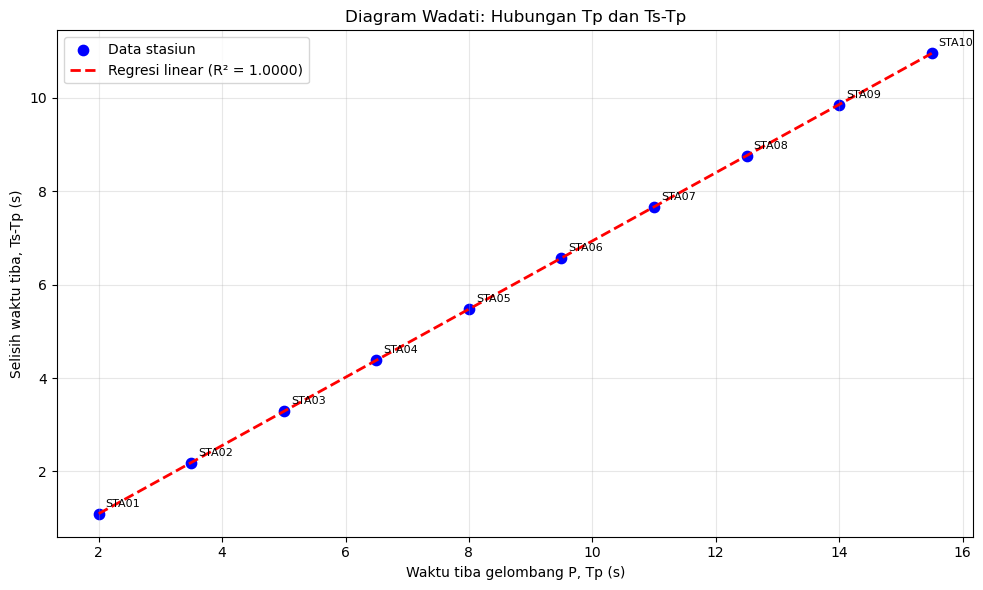


File hasil analisis berhasil disimpan:
1. tabel_pengolahan_wadati.csv
2. tabel_pengolahan_wadati.xlsx
3. parameter_wadati.csv
4. parameter_wadati.xlsx
5. diagram_wadati.png


In [9]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==================================================
# ANALISIS DATA SEISMIK DENGAN DIAGRAM WADATI
# ==================================================

# 1. DATA SIMULASI WAKTU TIBA GELOMBANG
# Satuan waktu: sekon
# Data ini merupakan simulasi, bukan data lapangan.

data = {
    "Stasiun": [
        "STA01", "STA02", "STA03", "STA04", "STA05",
        "STA06", "STA07", "STA08", "STA09", "STA10"
    ],
    "Tp (s)": [
        2.0, 3.5, 5.0, 6.5, 8.0,
        9.5, 11.0, 12.5, 14.0, 15.5
    ],
    "Ts (s)": [
        3.095, 5.690, 8.285, 10.880, 13.475,
        16.070, 18.665, 21.260, 23.855, 26.450
    ]
}

df = pd.DataFrame(data)

# 2. PEMERIKSAAN DATA
if df.isnull().any().any():
    raise ValueError("Data mengandung nilai kosong.")

if not np.isfinite(df[["Tp (s)", "Ts (s)"]]).all().all():
    raise ValueError("Data waktu mengandung nilai yang tidak valid.")

if df["Stasiun"].duplicated().any():
    raise ValueError("Terdapat nama stasiun yang duplikat.")

if (df["Tp (s)"] < 0).any() or (df["Ts (s)"] < 0).any():
    raise ValueError("Waktu tiba tidak boleh negatif.")

if (df["Ts (s)"] <= df["Tp (s)"]).any():
    raise ValueError("Periksa data: Ts harus lebih besar daripada Tp.")

# 3. MENGHITUNG SELISIH WAKTU TIBA S-P
df["Ts-Tp (s)"] = df["Ts (s)"] - df["Tp (s)"]

# 4. REGRESI LINEAR DIAGRAM WADATI
# Persamaan: Ts-Tp = m * Tp + b
x = df["Tp (s)"].to_numpy()
y = df["Ts-Tp (s)"].to_numpy()

m, b = np.polyfit(x, y, 1)

# 5. MENGHITUNG PARAMETER SEISMIK
# Rasio Vp/Vs = m + 1
rasio_vp_vs = m + 1

# Waktu asal gempa t0 = -b/m
if abs(m) > 1e-12:
    t0 = -b / m
else:
    t0 = np.nan

# 6. MENGHITUNG KOEFISIEN DETERMINASI R²
y_pred = m * x + b

ss_res = np.sum((y - y_pred) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)

if ss_tot > 0:
    r2 = 1 - (ss_res / ss_tot)
else:
    r2 = np.nan

# 7. ESTIMASI RASIO POISSON
# Berlaku untuk medium elastis isotropik
if rasio_vp_vs > np.sqrt(2):
    rasio_kuadrat = rasio_vp_vs ** 2
    poisson = (
        (rasio_kuadrat - 2)
        / (2 * (rasio_kuadrat - 1))
    )
else:
    poisson = np.nan

# 8. MENAMPILKAN TABEL HASIL PENGOLAHAN
print("\n" + "=" * 55)
print("TABEL PENGOLAHAN DATA SEISMIK")
print("=" * 55)

print(df.round(4).to_string(index=False))

# 9. MENAMPILKAN HASIL REGRESI DAN PARAMETER
print("\n" + "=" * 55)
print("HASIL ANALISIS DIAGRAM WADATI")
print("=" * 55)

print(
    f"Persamaan regresi: Ts-Tp = "
    f"{m:.4f} * Tp + ({b:.4f})"
)

print(f"Kemiringan garis (m) = {m:.4f}")
print(f"Intersep (b) = {b:.4f} sekon")
print(f"Rasio Vp/Vs = {rasio_vp_vs:.4f}")

if np.isfinite(t0):
    print(f"Estimasi waktu asal gempa (t0) = {t0:.4f} sekon")
else:
    print("Waktu asal gempa tidak dapat dihitung dari regresi ini.")

if np.isfinite(poisson):
    print(f"Estimasi rasio Poisson = {poisson:.4f}")
else:
    print("Rasio Poisson tidak dihitung karena asumsi rasio kecepatan tidak terpenuhi.")

if np.isfinite(r2):
    print(f"Koefisien determinasi R² = {r2:.4f}")

# 10. INTERPRETASI HASIL
print("\n" + "=" * 55)
print("INTERPRETASI HASIL")
print("=" * 55)

print(
    f"Kemiringan diagram Wadati sebesar {m:.4f} "
    f"menghasilkan rasio Vp/Vs sebesar {rasio_vp_vs:.4f}."
)

if np.isfinite(t0):
    print(
        f"Waktu asal gempa berdasarkan regresi diperkirakan "
        f"{t0:.3f} sekon."
    )

if np.isfinite(r2) and r2 >= 0.90:
    print(
        "Hubungan antara Tp dan Ts-Tp menunjukkan pola linear "
        "yang kuat pada data ini."
    )
else:
    print(
        "Hubungan linear perlu dievaluasi lebih lanjut. "
        "Periksa ketelitian waktu tiba dan kemungkinan variasi "
        "kecepatan gelombang."
    )

print(
    "Rasio Vp/Vs menunjukkan perbandingan kecepatan gelombang "
    "P dan S. Nilainya dapat membantu karakterisasi sifat elastik "
    "medium, tetapi tidak menentukan jenis batuan secara langsung."
)

# 11. MEMBUAT DIAGRAM WADATI
x_garis = np.linspace(x.min(), x.max(), 100)
y_garis = m * x_garis + b

plt.figure(figsize=(10, 6))

plt.scatter(
    x,
    y,
    color="blue",
    s=55,
    label="Data stasiun"
)

for i, baris in df.iterrows():
    plt.annotate(
        baris["Stasiun"],
        (baris["Tp (s)"], baris["Ts-Tp (s)"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.plot(
    x_garis,
    y_garis,
    "r--",
    linewidth=2,
    label=f"Regresi linear (R² = {r2:.4f})"
)

plt.xlabel("Waktu tiba gelombang P, Tp (s)")
plt.ylabel("Selisih waktu tiba, Ts-Tp (s)")
plt.title("Diagram Wadati: Hubungan Tp dan Ts-Tp")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("diagram_wadati.png", dpi=300)
plt.show()

# 12. MENYIMPAN HASIL KE FILE
df.to_csv("tabel_pengolahan_wadati.csv", index=False)
df.to_excel("tabel_pengolahan_wadati.xlsx", index=False)

ringkasan = pd.DataFrame({
    "Parameter": [
        "Kemiringan regresi",
        "Intersep regresi (s)",
        "Rasio Vp/Vs",
        "Waktu asal gempa (s)",
        "Rasio Poisson",
        "Koefisien determinasi R2"
    ],
    "Nilai": [
        m, b, rasio_vp_vs, t0, poisson, r2
    ]
})

ringkasan.to_csv("parameter_wadati.csv", index=False)
ringkasan.to_excel("parameter_wadati.xlsx", index=False)

print("\nFile hasil analisis berhasil disimpan:")
print("1. tabel_pengolahan_wadati.csv")
print("2. tabel_pengolahan_wadati.xlsx")
print("3. parameter_wadati.csv")
print("4. parameter_wadati.xlsx")
print("5. diagram_wadati.png")

3. **Context:** Analisis dilakukan menggunakan data rekaman gempa dari beberapa stasiun seismik. Data berupa waktu tiba gelombang P dan S digunakan untuk mengetahui karakteristik penjalaran gelombang seismik. Perbedaan waktu tiba gelombang P dan S pada setiap stasiun dapat digunakan untuk melakukan analisis lebih lanjut mengenai sumber dan karakteristik gempa.

   **Output:** Menghasilkan gambaran karakteristik data seismik melalui tabel pengolahan, diagram hubungan Tp dengan Ts–Tp, serta penjelasan mengenai hasil analisis gelombang P dan S.


=== TABEL PENGOLAHAN DATA SEISMIK ===
Stasiun  Tp (s)  Ts (s)  Ts-Tp (s)
  STA01     2.0   3.095      1.095
  STA02     3.5   5.690      2.190
  STA03     5.0   8.285      3.285
  STA04     6.5  10.880      4.380
  STA05     8.0  13.475      5.475
  STA06     9.5  16.070      6.570
  STA07    11.0  18.665      7.665
  STA08    12.5  21.260      8.760
  STA09    14.0  23.855      9.855
  STA10    15.5  26.450     10.950

=== HASIL ANALISIS PENJALARAN GELOMBANG ===
Kemiringan regresi             : 0.7300
Intersep regresi               : -0.3650 s
Rasio Vp/Vs                    : 1.7300
Koefisien determinasi R²       : 1.0000
Estimasi waktu asal gempa      : 0.5000 s

=== INTERPRETASI KARAKTERISTIK SEISMIK ===
Gelombang P umumnya tiba lebih dahulu daripada gelombang S karena kecepatan gelombang P lebih tinggi.
Selisih Ts-Tp meningkat pada urutan data ini. Pola tersebut menunjukkan peningkatan perbedaan waktu tempuh gelombang P dan S.
Diagram Wadati menunjukkan hubungan linear yang kuat u

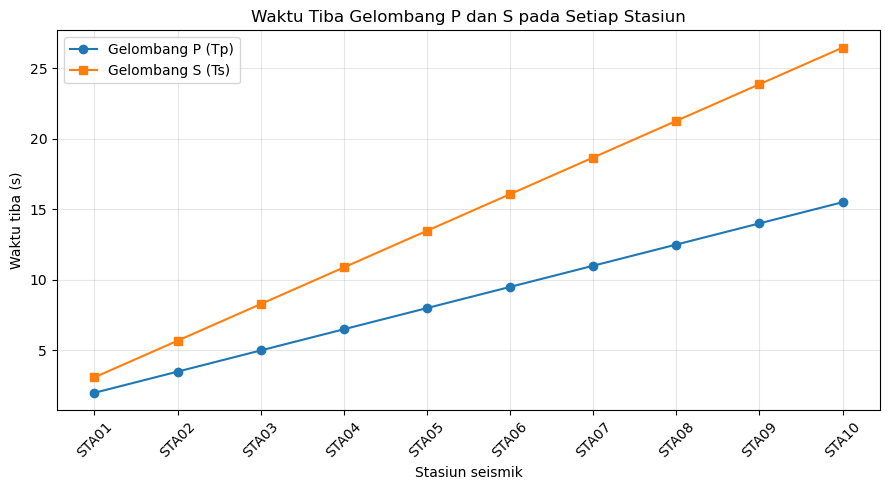

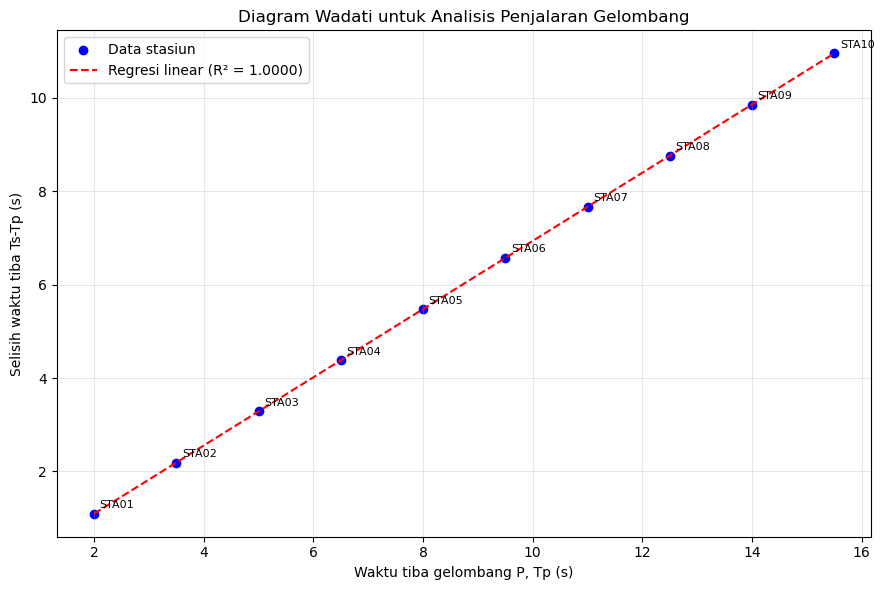


File hasil analisis:
- hasil_karakteristik_seismik.csv
- hasil_karakteristik_seismik.xlsx
- waktu_tiba_P_S.png
- diagram_wadati_context3.png


In [10]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==================================================
# ANALISIS KARAKTERISTIK DATA SEISMIK
# GELOMBANG P DAN S
# ==================================================

# 1. Data simulasi waktu tiba gelombang dari beberapa stasiun
# Waktu menggunakan satuan sekon.
# Data ini bukan rekaman gempa lapangan.

data = {
    "Stasiun": [
        "STA01", "STA02", "STA03", "STA04", "STA05",
        "STA06", "STA07", "STA08", "STA09", "STA10"
    ],
    "Tp (s)": [
        2.0, 3.5, 5.0, 6.5, 8.0,
        9.5, 11.0, 12.5, 14.0, 15.5
    ],
    "Ts (s)": [
        3.095, 5.690, 8.285, 10.880, 13.475,
        16.070, 18.665, 21.260, 23.855, 26.450
    ]
}

df = pd.DataFrame(data)

# 2. Pemeriksaan kualitas data
if df.isnull().any().any():
    raise ValueError("Terdapat data waktu tiba yang kosong.")

if not np.isfinite(df[["Tp (s)", "Ts (s)"]]).all().all():
    raise ValueError("Data waktu tiba harus berupa angka yang valid.")

if df["Stasiun"].duplicated().any():
    raise ValueError("Nama stasiun tidak boleh duplikat.")

if (df["Tp (s)"] < 0).any() or (df["Ts (s)"] < 0).any():
    raise ValueError("Waktu tiba tidak boleh negatif.")

if (df["Ts (s)"] <= df["Tp (s)"]).any():
    raise ValueError("Periksa data karena Ts harus lebih besar dari Tp.")

# 3. Menghitung selisih waktu tiba gelombang S dan P
df["Ts-Tp (s)"] = df["Ts (s)"] - df["Tp (s)"]

# 4. Analisis hubungan Tp dengan Ts-Tp
x = df["Tp (s)"].to_numpy()
y = df["Ts-Tp (s)"].to_numpy()

m, b = np.polyfit(x, y, 1)
y_pred = m * x + b

# Koefisien determinasi
ss_res = np.sum((y - y_pred) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)
r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

# Parameter diagram Wadati
rasio_vp_vs = m + 1
t0 = -b / m if abs(m) > 1e-12 else np.nan

# 5. Menampilkan tabel pengolahan
print("\n=== TABEL PENGOLAHAN DATA SEISMIK ===")
print(df.round(4).to_string(index=False))

# 6. Menampilkan hasil analisis
print("\n=== HASIL ANALISIS PENJALARAN GELOMBANG ===")
print(f"Kemiringan regresi             : {m:.4f}")
print(f"Intersep regresi               : {b:.4f} s")
print(f"Rasio Vp/Vs                    : {rasio_vp_vs:.4f}")
print(f"Koefisien determinasi R²       : {r2:.4f}")

if np.isfinite(t0):
    print(f"Estimasi waktu asal gempa      : {t0:.4f} s")
else:
    print("Waktu asal gempa tidak dapat diestimasi.")

# 7. Interpretasi otomatis
print("\n=== INTERPRETASI KARAKTERISTIK SEISMIK ===")

print(
    "Gelombang P umumnya tiba lebih dahulu daripada gelombang S "
    "karena kecepatan gelombang P lebih tinggi."
)

if np.all(np.diff(df["Ts-Tp (s)"].to_numpy()) > 0):
    print(
        "Selisih Ts-Tp meningkat pada urutan data ini. "
        "Pola tersebut menunjukkan peningkatan perbedaan waktu "
        "tempuh gelombang P dan S."
    )
else:
    print(
        "Selisih Ts-Tp tidak selalu meningkat. Perlu diperiksa "
        "pengaruh jarak stasiun, ketidakpastian pembacaan fase, "
        "dan variasi kecepatan bawah permukaan."
    )

if np.isfinite(r2) and r2 >= 0.90:
    print(
        "Diagram Wadati menunjukkan hubungan linear yang kuat "
        "untuk data simulasi ini."
    )
else:
    print(
        "Hubungan linear perlu ditinjau lebih lanjut sebelum "
        "parameter Wadati diinterpretasikan."
    )

print(
    "Rasio Vp/Vs merupakan parameter kecepatan relatif. "
    "Nilai ini tidak dapat menentukan jenis batuan secara "
    "langsung tanpa informasi geologi tambahan."
)

# 8. Grafik waktu tiba P dan S
plt.figure(figsize=(9, 5))
plt.plot(
    df["Stasiun"], df["Tp (s)"],
    marker="o", label="Gelombang P (Tp)"
)
plt.plot(
    df["Stasiun"], df["Ts (s)"],
    marker="s", label="Gelombang S (Ts)"
)
plt.xlabel("Stasiun seismik")
plt.ylabel("Waktu tiba (s)")
plt.title("Waktu Tiba Gelombang P dan S pada Setiap Stasiun")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("waktu_tiba_P_S.png", dpi=300)
plt.show()

# 9. Diagram Wadati
x_garis = np.linspace(x.min(), x.max(), 100)
y_garis = m * x_garis + b

plt.figure(figsize=(9, 6))
plt.scatter(x, y, color="blue", label="Data stasiun")

for _, row in df.iterrows():
    plt.annotate(
        row["Stasiun"],
        (row["Tp (s)"], row["Ts-Tp (s)"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

plt.plot(
    x_garis,
    y_garis,
    "r--",
    label=f"Regresi linear (R² = {r2:.4f})"
)
plt.xlabel("Waktu tiba gelombang P, Tp (s)")
plt.ylabel("Selisih waktu tiba Ts-Tp (s)")
plt.title("Diagram Wadati untuk Analisis Penjalaran Gelombang")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("diagram_wadati_context3.png", dpi=300)
plt.show()

# 10. Menyimpan tabel hasil
df.to_csv("hasil_karakteristik_seismik.csv", index=False)
df.to_excel("hasil_karakteristik_seismik.xlsx", index=False)

print("\nFile hasil analisis:")
print("- hasil_karakteristik_seismik.csv")
print("- hasil_karakteristik_seismik.xlsx")
print("- waktu_tiba_P_S.png")
print("- diagram_wadati_context3.png")


4. **Input:** Masukkan data berupa nama stasiun, koordinat latitude dan longitude, waktu tiba gelombang P (Tp), serta waktu tiba gelombang S (Ts). Data dapat berupa waktu dalam detik atau format waktu yang kemudian dikonversi menjadi satuan detik.

   **Output:** Menghasilkan data terstruktur berupa Tp, Ts, Ts–Tp, serta parameter hasil analisis yang dapat digunakan untuk membuat diagram Wadati dan interpretasi data seismik.


=== TABEL INPUT DAN HASIL PENGOLAHAN ===
Stasiun  Latitude  Longitude  Tp (s)  Ts (s)  Ts-Tp (s)
  STA01     -5.10     119.40     2.0   3.095      1.095
  STA02     -5.15     119.45     3.5   5.690      2.190
  STA03     -5.20     119.50     5.0   8.285      3.285
  STA04     -5.25     119.55     6.5  10.880      4.380
  STA05     -5.30     119.60     8.0  13.475      5.475
  STA06     -5.35     119.65     9.5  16.070      6.570
  STA07     -5.40     119.70    11.0  18.665      7.665
  STA08     -5.45     119.75    12.5  21.260      8.760
  STA09     -5.50     119.80    14.0  23.855      9.855
  STA10     -5.55     119.85    15.5  26.450     10.950

=== PARAMETER DIAGRAM WADATI ===
Kemiringan regresi (m) = 0.7300
Intersep (b) = -0.3650 sekon
Rasio Vp/Vs = 1.7300
Estimasi waktu asal gempa (t0) = 0.5000 sekon
Koefisien determinasi R² = 1.0000


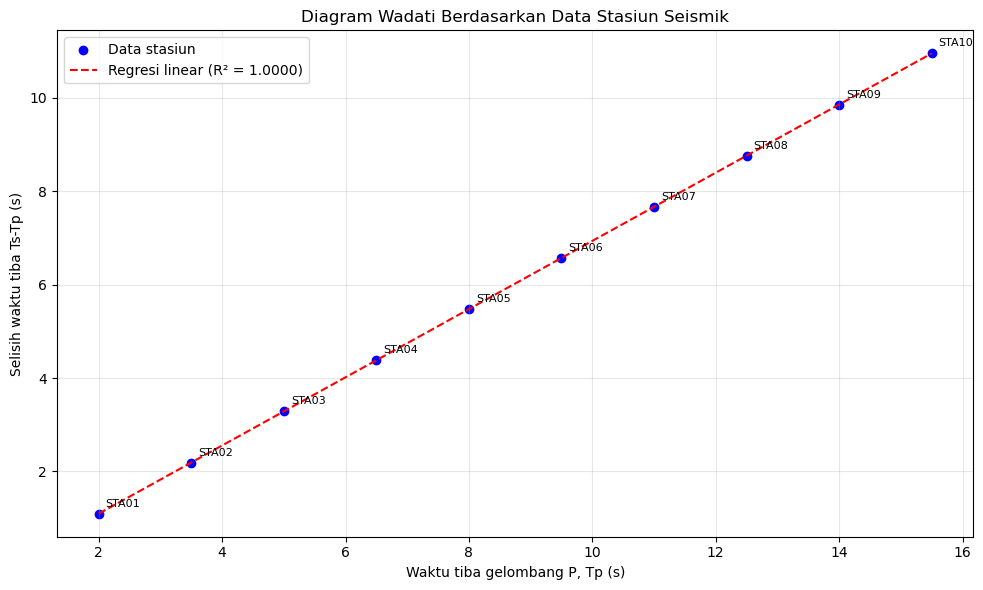


File berhasil disimpan:
- data_pengolahan_stasiun_seismik.csv
- data_pengolahan_stasiun_seismik.xlsx
- parameter_diagram_wadati.csv
- diagram_wadati_input_stasiun.png


In [11]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==================================================
# INPUT DAN PENGOLAHAN DATA SEISMIK
# DIAGRAM WADATI
# ==================================================

# 1. Data simulasi stasiun seismik
# Koordinat dalam derajat desimal
# Waktu tiba dalam sekon
# Data ini bukan data gempa lapangan

data = {
    "Stasiun": [
        "STA01", "STA02", "STA03", "STA04", "STA05",
        "STA06", "STA07", "STA08", "STA09", "STA10"
    ],
    "Latitude": [
        -5.10, -5.15, -5.20, -5.25, -5.30,
        -5.35, -5.40, -5.45, -5.50, -5.55
    ],
    "Longitude": [
        119.40, 119.45, 119.50, 119.55, 119.60,
        119.65, 119.70, 119.75, 119.80, 119.85
    ],
    "Tp (s)": [
        2.0, 3.5, 5.0, 6.5, 8.0,
        9.5, 11.0, 12.5, 14.0, 15.5
    ],
    "Ts (s)": [
        3.095, 5.690, 8.285, 10.880, 13.475,
        16.070, 18.665, 21.260, 23.855, 26.450
    ]
}

df = pd.DataFrame(data)

# 2. Pemeriksaan data
kolom_waktu = ["Tp (s)", "Ts (s)"]
kolom_koordinat = ["Latitude", "Longitude"]

if df.isnull().any().any():
    raise ValueError("Data memiliki nilai kosong.")

if df["Stasiun"].duplicated().any():
    raise ValueError("Nama stasiun ditemukan duplikat.")

if not np.isfinite(
    df[kolom_waktu + kolom_koordinat]
).all().all():
    raise ValueError("Data mengandung nilai numerik yang tidak valid.")

if not df["Latitude"].between(-90, 90).all():
    raise ValueError("Latitude harus berada antara -90 dan 90 derajat.")

if not df["Longitude"].between(-180, 180).all():
    raise ValueError("Longitude harus berada antara -180 dan 180 derajat.")

if (df[kolom_waktu] < 0).any().any():
    raise ValueError("Waktu tiba tidak boleh negatif.")

if (df["Ts (s)"] <= df["Tp (s)"]).any():
    raise ValueError("Periksa data: Ts harus lebih besar daripada Tp.")

# 3. Menghitung selisih waktu S-P
df["Ts-Tp (s)"] = df["Ts (s)"] - df["Tp (s)"]

# 4. Analisis regresi diagram Wadati
x = df["Tp (s)"].to_numpy()
y = df["Ts-Tp (s)"].to_numpy()

m, b = np.polyfit(x, y, 1)
y_pred = m * x + b

# Koefisien determinasi R²
ss_res = np.sum((y - y_pred) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)

r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

# Parameter Wadati
rasio_vp_vs = m + 1
t0 = -b / m if abs(m) > 1e-12 else np.nan

# 5. Menampilkan tabel hasil pengolahan
print("\n=== TABEL INPUT DAN HASIL PENGOLAHAN ===")
print(df.round(4).to_string(index=False))

# 6. Menampilkan hasil analisis
print("\n=== PARAMETER DIAGRAM WADATI ===")
print(f"Kemiringan regresi (m) = {m:.4f}")
print(f"Intersep (b) = {b:.4f} sekon")
print(f"Rasio Vp/Vs = {rasio_vp_vs:.4f}")

if np.isfinite(t0):
    print(f"Estimasi waktu asal gempa (t0) = {t0:.4f} sekon")
else:
    print("Waktu asal gempa tidak dapat diestimasi dari regresi ini.")

if np.isfinite(r2):
    print(f"Koefisien determinasi R² = {r2:.4f}")

# 7. Membuat diagram Wadati
x_garis = np.linspace(x.min(), x.max(), 100)
y_garis = m * x_garis + b

plt.figure(figsize=(10, 6))
plt.scatter(x, y, color="blue", label="Data stasiun")

for _, row in df.iterrows():
    plt.annotate(
        row["Stasiun"],
        (row["Tp (s)"], row["Ts-Tp (s)"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.plot(
    x_garis,
    y_garis,
    "r--",
    label=f"Regresi linear (R² = {r2:.4f})"
)

plt.xlabel("Waktu tiba gelombang P, Tp (s)")
plt.ylabel("Selisih waktu tiba Ts-Tp (s)")
plt.title("Diagram Wadati Berdasarkan Data Stasiun Seismik")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("diagram_wadati_input_stasiun.png", dpi=300)
plt.show()

# 8. Menyimpan hasil pengolahan
df.to_csv("data_pengolahan_stasiun_seismik.csv", index=False)
df.to_excel("data_pengolahan_stasiun_seismik.xlsx", index=False)

parameter = pd.DataFrame({
    "Parameter": [
        "Kemiringan regresi",
        "Intersep (s)",
        "Rasio Vp/Vs",
        "Estimasi waktu asal gempa (s)",
        "Koefisien determinasi R2"
    ],
    "Nilai": [m, b, rasio_vp_vs, t0, r2]
})

parameter.to_csv("parameter_diagram_wadati.csv", index=False)

print("\nFile berhasil disimpan:")
print("- data_pengolahan_stasiun_seismik.csv")
print("- data_pengolahan_stasiun_seismik.xlsx")
print("- parameter_diagram_wadati.csv")
print("- diagram_wadati_input_stasiun.png")

5. **Constraints:** Gunakan konsep dasar seismologi dan persamaan yang sesuai dengan analisis waktu tiba gelombang P dan S. Pastikan format waktu dan satuan konsisten. Jangan mengubah data asli tanpa alasan yang jelas. Perhitungan harus dilakukan secara sistematis dan hasil interpretasi harus berdasarkan data yang tersedia.

   **Output:** Menghasilkan analisis seismik yang konsisten dengan data asli, perhitungan yang benar, diagram yang sesuai, serta interpretasi berdasarkan prinsip seismologi.

TABEL DATA PENGAMATAN SEISMIK
Stasiun  Latitude  Longitude  Tp (s)  Ts (s)  Ts-Tp (s)
  STA01   -5.1000   119.4000  2.0000  3.0950     1.0950
  STA02   -5.1500   119.4500  3.5000  5.6900     2.1900
  STA03   -5.2000   119.5000  5.0000  8.2850     3.2850
  STA04   -5.2500   119.5500  6.5000 10.8800     4.3800
  STA05   -5.3000   119.6000  8.0000 13.4750     5.4750
  STA06   -5.3500   119.6500  9.5000 16.0700     6.5700
  STA07   -5.4000   119.7000 11.0000 18.6650     7.6650
  STA08   -5.4500   119.7500 12.5000 21.2600     8.7600
  STA09   -5.5000   119.8000 14.0000 23.8550     9.8550
  STA10   -5.5500   119.8500 15.5000 26.4500    10.9500

HASIL ANALISIS DIAGRAM WADATI
Slope (m)       : 0.730000
Intersep (b)    : -0.365000 sekon
Rasio Vp/Vs     : 1.730000
Waktu asal (t0) : 0.500000 sekon
Koefisien R^2   : 1.000000


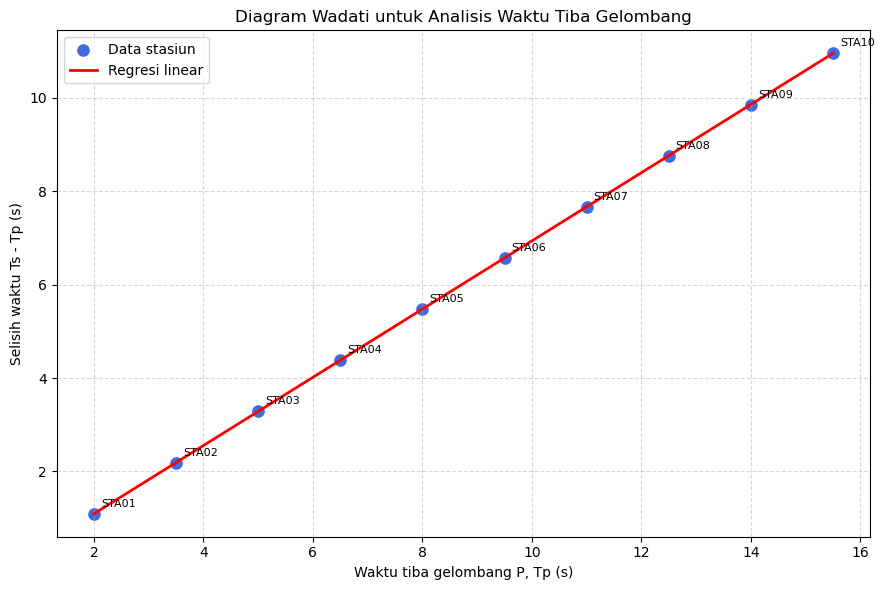


INTERPRETASI HASIL
Rasio Vp/Vs hasil estimasi adalah 1.730.
Waktu asal gempa hasil estimasi adalah 0.500 sekon terhadap acuan waktu yang digunakan.
Nilai R^2 sebesar 1.0000.
Hubungan linear pada data cukup kuat. Namun, nilai R^2 tinggi tidak menjamin parameter fisik bebas dari kesalahan.

Catatan: Diagram Wadati sederhana tidak menggunakan latitude dan longitude secara langsung dalam regresi.
Hasil akhir harus ditafsirkan berdasarkan data asli, ketelitian waktu, dan asumsi seismologi yang sesuai.

File Excel berhasil disimpan.

File CSV dan diagram disimpan di folder kerja Python.
Analisis selesai.


In [12]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# =====================================================
# ANALISIS SEISMIK MENGGUNAKAN DIAGRAM WADATI
# =====================================================
# Input:
# Nama stasiun, latitude, longitude, Tp, dan Ts
#
# Output:
# Tabel pengolahan, parameter Wadati, diagram,
# serta interpretasi hasil analisis.
#
# Catatan:
# Data berikut merupakan data simulasi.
# Ganti dengan data pengamatan asli.
# =====================================================

# 1. MEMASUKKAN DATA STASIUN
data = {
    "Stasiun": [
        "STA01", "STA02", "STA03", "STA04", "STA05",
        "STA06", "STA07", "STA08", "STA09", "STA10"
    ],
    "Latitude": [
        -5.10, -5.15, -5.20, -5.25, -5.30,
        -5.35, -5.40, -5.45, -5.50, -5.55
    ],
    "Longitude": [
        119.40, 119.45, 119.50, 119.55, 119.60,
        119.65, 119.70, 119.75, 119.80, 119.85
    ],
    "Tp (s)": [
        2.0, 3.5, 5.0, 6.5, 8.0,
        9.5, 11.0, 12.5, 14.0, 15.5
    ],
    "Ts (s)": [
        3.095, 5.690, 8.285, 10.880, 13.475,
        16.070, 18.665, 21.260, 23.855, 26.450
    ]
}

df = pd.DataFrame(data)

# 2. VALIDASI DATA
kolom_wajib = [
    "Stasiun", "Latitude", "Longitude", "Tp (s)", "Ts (s)"
]

if df.empty:
    raise ValueError("Data stasiun masih kosong.")

if df[kolom_wajib].isnull().any().any():
    raise ValueError("Terdapat data kosong. Periksa data asli.")

if df["Stasiun"].duplicated().any():
    raise ValueError("Terdapat nama stasiun yang duplikat.")

kolom_numerik = [
    "Latitude", "Longitude", "Tp (s)", "Ts (s)"
]

if not np.isfinite(df[kolom_numerik].to_numpy()).all():
    raise ValueError("Data numerik mengandung nilai tidak valid.")

if not df["Latitude"].between(-90, 90).all():
    raise ValueError("Nilai latitude di luar rentang yang valid.")

if not df["Longitude"].between(-180, 180).all():
    raise ValueError("Nilai longitude di luar rentang yang valid.")

if (df[["Tp (s)", "Ts (s)"]] < 0).any().any():
    raise ValueError("Waktu kedatangan tidak boleh negatif.")

if not (df["Ts (s)"] > df["Tp (s)"]).all():
    raise ValueError(
        "Ditemukan Ts <= Tp. Periksa kembali waktu kedatangan."
    )

if len(df) < 3:
    raise ValueError(
        "Gunakan minimal 3 stasiun untuk analisis regresi."
    )

if df["Tp (s)"].nunique() < 2:
    raise ValueError("Nilai Tp harus bervariasi.")

# 3. MENGHITUNG SELISIH WAKTU S-P
df["Ts-Tp (s)"] = df["Ts (s)"] - df["Tp (s)"]

# 4. REGRESI LINEAR DIAGRAM WADATI
# Persamaan: Ts - Tp = m * Tp + b

x = df["Tp (s)"].to_numpy()
y = df["Ts-Tp (s)"].to_numpy()

m, b = np.polyfit(x, y, 1)

y_pred = m * x + b

# Menghitung koefisien determinasi R^2
ss_res = np.sum((y - y_pred) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)

if ss_tot > 0:
    r2 = 1 - (ss_res / ss_tot)
else:
    r2 = np.nan

# 5. MENGHITUNG PARAMETER WADATI
# Vp/Vs = m + 1
# t0 = -b/m

rasio_vp_vs = m + 1

if abs(m) > 1e-12:
    t0 = -b / m
else:
    t0 = np.nan

# Pemeriksaan kelayakan parameter
parameter_valid = (
    m > 0
    and rasio_vp_vs > 1
    and np.isfinite(t0)
    and t0 >= 0
    and t0 <= np.min(x)
)

# 6. MENAMPILKAN TABEL DATA
print("=" * 60)
print("TABEL DATA PENGAMATAN SEISMIK")
print("=" * 60)
print(df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

# 7. MENAMPILKAN HASIL REGRESI
print("\n" + "=" * 60)
print("HASIL ANALISIS DIAGRAM WADATI")
print("=" * 60)

print(f"Slope (m)       : {m:.6f}")
print(f"Intersep (b)    : {b:.6f} sekon")
print(f"Rasio Vp/Vs     : {rasio_vp_vs:.6f}")
print(f"Waktu asal (t0) : {t0:.6f} sekon")
print(f"Koefisien R^2   : {r2:.6f}")

# 8. MEMBUAT DIAGRAM WADATI
x_garis = np.linspace(np.min(x), np.max(x), 200)
y_garis = m * x_garis + b

plt.figure(figsize=(9, 6))

plt.scatter(
    x, y,
    color="royalblue",
    s=65,
    label="Data stasiun"
)

plt.plot(
    x_garis, y_garis,
    color="red",
    linewidth=2,
    label="Regresi linear"
)

# Memberi label nama pada setiap titik
for i, nama in enumerate(df["Stasiun"]):
    plt.annotate(
        nama,
        (x[i], y[i]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Waktu tiba gelombang P, Tp (s)")
plt.ylabel("Selisih waktu Ts - Tp (s)")
plt.title("Diagram Wadati untuk Analisis Waktu Tiba Gelombang")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()

plt.savefig("diagram_wadati.png", dpi=300)
plt.show()

# 9. INTERPRETASI HASIL
print("\n" + "=" * 60)
print("INTERPRETASI HASIL")
print("=" * 60)

if parameter_valid:
    print(
        f"Rasio Vp/Vs hasil estimasi adalah "
        f"{rasio_vp_vs:.3f}."
    )
    print(
        f"Waktu asal gempa hasil estimasi adalah "
        f"{t0:.3f} sekon terhadap acuan waktu yang digunakan."
    )
else:
    print(
        "Parameter Wadati perlu diperiksa kembali. "
        "Periksa kualitas data, acuan waktu, dan asumsi model."
    )

if np.isfinite(r2):
    print(f"Nilai R^2 sebesar {r2:.4f}.")

    if r2 >= 0.90:
        print(
            "Hubungan linear pada data cukup kuat. "
            "Namun, nilai R^2 tinggi tidak menjamin "
            "parameter fisik bebas dari kesalahan."
        )
    else:
        print(
            "Sebaran data terhadap garis regresi cukup besar. "
            "Periksa waktu kedatangan dan kesesuaian model."
        )

print(
    "\nCatatan: Diagram Wadati sederhana tidak menggunakan "
    "latitude dan longitude secara langsung dalam regresi."
)
print(
    "Hasil akhir harus ditafsirkan berdasarkan data asli, "
    "ketelitian waktu, dan asumsi seismologi yang sesuai."
)

# 10. MENYIMPAN HASIL KE FILE
df.to_csv(
    "hasil_pengolahan_seismik.csv",
    index=False
)

parameter = pd.DataFrame({
    "Parameter": [
        "Slope",
        "Intersep (s)",
        "Rasio Vp/Vs",
        "Waktu asal t0 (s)",
        "R_squared"
    ],
    "Nilai": [
        m,
        b,
        rasio_vp_vs,
        t0,
        r2
    ]
})

parameter.to_csv(
    "parameter_wadati.csv",
    index=False
)

# Simpan Excel jika library openpyxl tersedia
try:
    with pd.ExcelWriter(
        "hasil_analisis_wadati.xlsx"
    ) as writer:
        df.to_excel(
            writer,
            sheet_name="Data Seismik",
            index=False
        )
        parameter.to_excel(
            writer,
            sheet_name="Parameter Wadati",
            index=False
        )

    print("\nFile Excel berhasil disimpan.")

except ImportError:
    print(
        "\nExcel belum disimpan karena openpyxl belum tersedia."
    )
    print("Pasang dengan perintah: pip install openpyxl")

print("\nFile CSV dan diagram disimpan di folder kerja Python.")
print("Analisis selesai.")



**PROMPT 3**

1. **Role:** Anda berperan sebagai seorang ahli geofisika yang memiliki keahlian dalam metode gravitasi, khususnya pengolahan dan interpretasi data percepatan gravitasi. Anda mampu melakukan koreksi data gravitasi, menghitung anomali Bouguer, serta menginterpretasikan variasi nilai gravitasi untuk mengetahui kemungkinan perubahan densitas material bawah permukaan.

   **Output:** Menghasilkan analisis data gravitasi yang sistematis berupa hasil koreksi, nilai anomali gravitasi, visualisasi anomali, serta interpretasi struktur bawah permukaan berdasarkan variasi nilai gravitasi.

HASIL PENGOLAHAN DATA GRAVITASI
Stasiun  Latitude  Longitude  Elevasi_m  g_terukur_mGal  koreksi_drift_mGal  g_normal_mGal  koreksi_udara_bebas_mGal  koreksi_bouguer_mGal  anomali_udara_bebas_mGal  anomali_bouguer_mGal
  STA01    -5.100    119.400         20      978100.200               0.000     978073.478                     6.172                 2.239                    32.894                30.655
  STA02    -5.120    119.420         35      978098.800               0.100     978073.798                    10.801                 3.918                    35.903                31.985
  STA03    -5.140    119.440         50      978097.900               0.100     978074.119                    15.430                 5.598                    39.311                33.713
  STA04    -5.160    119.460         65      978096.500               0.200     978074.441                    20.059                 7.277                    42.318                35.041
  STA05    -5.180    119.480     

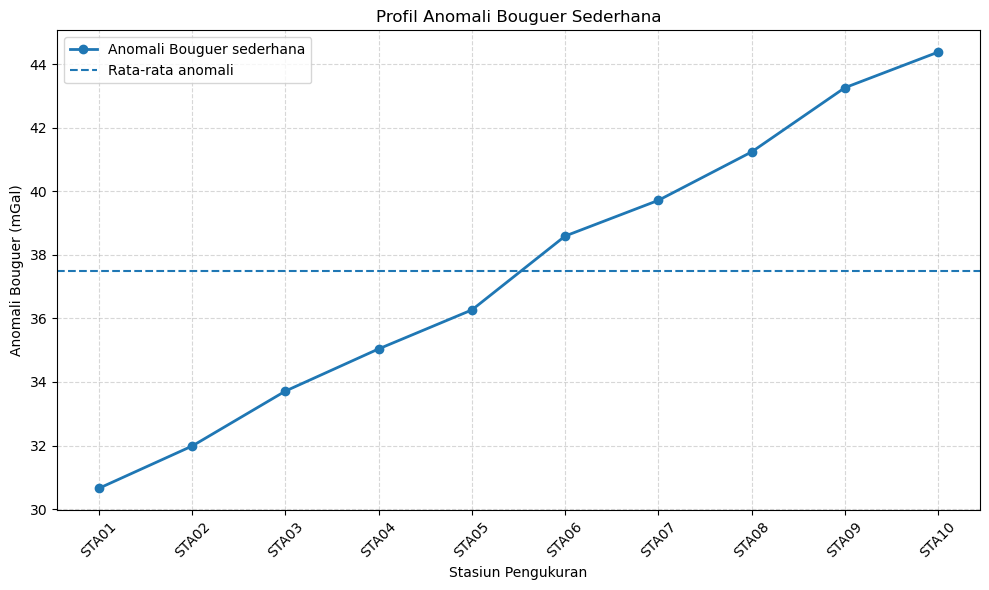

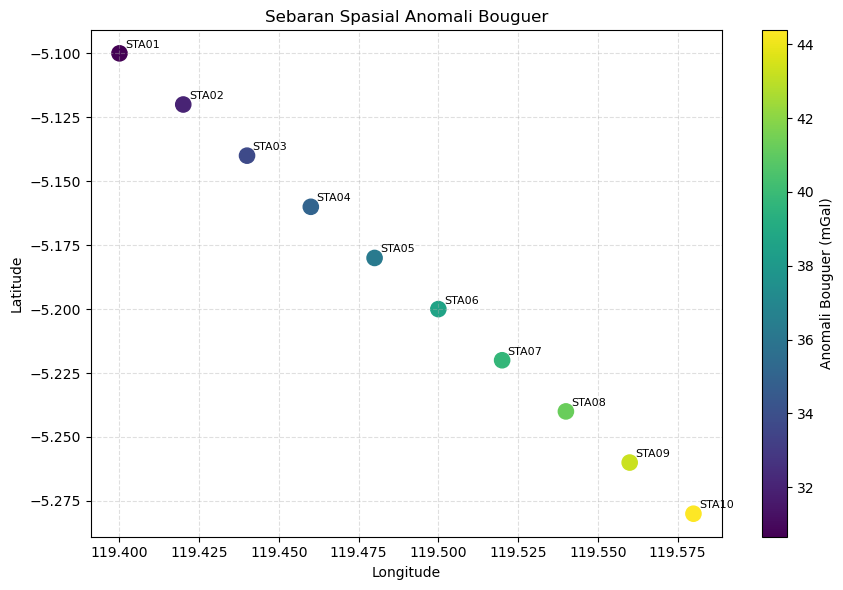


INTERPRETASI AWAL
STA01: 30.655 mGal - Relatif rendah; dapat mengindikasikan material kurang rapat dibandingkan lingkungan sekitarnya.
STA02: 31.985 mGal - Relatif rendah; dapat mengindikasikan material kurang rapat dibandingkan lingkungan sekitarnya.
STA03: 33.713 mGal - Relatif rendah; dapat mengindikasikan material kurang rapat dibandingkan lingkungan sekitarnya.
STA04: 35.041 mGal - Relatif rendah; dapat mengindikasikan material kurang rapat dibandingkan lingkungan sekitarnya.
STA05: 36.267 mGal - Relatif rendah; dapat mengindikasikan material kurang rapat dibandingkan lingkungan sekitarnya.
STA06: 38.592 mGal - Relatif tinggi; dapat mengindikasikan material lebih rapat dibandingkan lingkungan sekitarnya.
STA07: 39.716 mGal - Relatif tinggi; dapat mengindikasikan material lebih rapat dibandingkan lingkungan sekitarnya.
STA08: 41.238 mGal - Relatif tinggi; dapat mengindikasikan material lebih rapat dibandingkan lingkungan sekitarnya.
STA09: 43.259 mGal - Relatif tinggi; dapat mengi

In [13]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# PENGOLAHAN DATA GRAVITASI DAN ANALISIS ANOMALI BOUGUER
# ==========================================================
# Input:
# Posisi stasiun, gravitasi terukur, elevasi, lintang,
# drift alat, dan densitas Bouguer.
#
# Output:
# Koreksi gravitasi, anomali Bouguer sederhana,
# visualisasi anomali, dan interpretasi awal.
#
# Catatan:
# Data yang digunakan di bawah merupakan data simulasi.
# ==========================================================

# 1. INPUT DATA
data = {
    "Stasiun": [
        "STA01", "STA02", "STA03", "STA04", "STA05",
        "STA06", "STA07", "STA08", "STA09", "STA10"
    ],
    "Latitude": [
        -5.10, -5.12, -5.14, -5.16, -5.18,
        -5.20, -5.22, -5.24, -5.26, -5.28
    ],
    "Longitude": [
        119.40, 119.42, 119.44, 119.46, 119.48,
        119.50, 119.52, 119.54, 119.56, 119.58
    ],
    "Elevasi_m": [
        20, 35, 50, 65, 80, 95, 110, 125, 140, 155
    ],
    # Gravitasi terukur dalam mGal
    "g_terukur_mGal": [
        978100.2, 978098.8, 978097.9, 978096.5,
        978095.1, 978094.7, 978093.2, 978092.0,
        978091.4, 978089.8
    ],
    # Koreksi drift alat dalam mGal
    "koreksi_drift_mGal": [
        0.0, 0.1, 0.1, 0.2, 0.2,
        0.3, 0.3, 0.4, 0.4, 0.5
    ]
}

df = pd.DataFrame(data)

# 2. PARAMETER PENGOLAHAN
# Nilai gravitasi normal dan densitas berikut adalah
# contoh pendekatan, bukan nilai hasil pengukuran.
densitas = 2.67       # g/cm^3
g_referensi = 978100  # mGal, contoh gravitasi normal acuan

# 3. VALIDASI DATA
kolom_wajib = [
    "Stasiun", "Latitude", "Longitude", "Elevasi_m",
    "g_terukur_mGal", "koreksi_drift_mGal"
]

if df.empty:
    raise ValueError("Data gravitasi kosong.")

if df[kolom_wajib].isnull().any().any():
    raise ValueError("Terdapat data kosong pada input.")

if df["Stasiun"].duplicated().any():
    raise ValueError("Nama stasiun tidak boleh duplikat.")

kolom_numerik = [
    "Latitude", "Longitude", "Elevasi_m",
    "g_terukur_mGal", "koreksi_drift_mGal"
]

if not np.isfinite(df[kolom_numerik].to_numpy()).all():
    raise ValueError("Data mengandung nilai numerik tidak valid.")

if not df["Latitude"].between(-90, 90).all():
    raise ValueError("Latitude berada di luar rentang valid.")

if not df["Longitude"].between(-180, 180).all():
    raise ValueError("Longitude berada di luar rentang valid.")

if densitas <= 0:
    raise ValueError("Densitas harus lebih besar dari nol.")

if (df["Elevasi_m"] < 0).any():
    raise ValueError(
        "Contoh ini ditujukan untuk stasiun di atas datum."
    )

# 4. KOREKSI DRIFT
# Koreksi drift sudah dimasukkan sebagai nilai bertanda.
# Nilai tersebut dijumlahkan ke gravitasi terukur.
df["g_setelah_drift_mGal"] = (
    df["g_terukur_mGal"] + df["koreksi_drift_mGal"]
)

# 5. KOREKSI LINTANG / GRAVITASI NORMAL
# Rumus gravitasi normal GRS80 dalam mGal.
phi = np.radians(df["Latitude"].to_numpy())

g_normal = 978032.67715 * (
    1
    + 0.001931851353 * np.sin(phi)**2
) / np.sqrt(
    1 - 0.0066943800229 * np.sin(phi)**2
)

df["g_normal_mGal"] = g_normal

# 6. KOREKSI UDARA BEBAS
# 0.3086 mGal per meter elevasi
df["koreksi_udara_bebas_mGal"] = (
    0.3086 * df["Elevasi_m"]
)

# 7. KOREKSI BOUGUER SEDERHANA
# 0.04193 * densitas (g/cm3) * elevasi (m)
df["koreksi_bouguer_mGal"] = (
    0.04193 * densitas * df["Elevasi_m"]
)

# 8. ANOMALI GRAVITASI UDARA BEBAS
df["anomali_udara_bebas_mGal"] = (
    df["g_setelah_drift_mGal"]
    - df["g_normal_mGal"]
    + df["koreksi_udara_bebas_mGal"]
)

# 9. ANOMALI BOUGUER SEDERHANA
df["anomali_bouguer_mGal"] = (
    df["g_setelah_drift_mGal"]
    - df["g_normal_mGal"]
    + df["koreksi_udara_bebas_mGal"]
    - df["koreksi_bouguer_mGal"]
)

# 10. MENAMPILKAN TABEL HASIL
kolom_hasil = [
    "Stasiun",
    "Latitude",
    "Longitude",
    "Elevasi_m",
    "g_terukur_mGal",
    "koreksi_drift_mGal",
    "g_normal_mGal",
    "koreksi_udara_bebas_mGal",
    "koreksi_bouguer_mGal",
    "anomali_udara_bebas_mGal",
    "anomali_bouguer_mGal"
]

print("=" * 75)
print("HASIL PENGOLAHAN DATA GRAVITASI")
print("=" * 75)

print(
    df[kolom_hasil].to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# 11. STATISTIK ANOMALI BOUGUER
anomali = df["anomali_bouguer_mGal"]

print("\nSTATISTIK ANOMALI BOUGUER")
print(f"Minimum : {anomali.min():.3f} mGal")
print(f"Maksimum: {anomali.max():.3f} mGal")
print(f"Rata-rata: {anomali.mean():.3f} mGal")
print(f"Rentang : {anomali.max() - anomali.min():.3f} mGal")

# 12. VISUALISASI ANOMALI BOUGUER
plt.figure(figsize=(10, 6))

plt.plot(
    df["Stasiun"],
    df["anomali_bouguer_mGal"],
    marker="o",
    linewidth=2,
    label="Anomali Bouguer sederhana"
)

plt.axhline(
    anomali.mean(),
    linestyle="--",
    label="Rata-rata anomali"
)

plt.xlabel("Stasiun Pengukuran")
plt.ylabel("Anomali Bouguer (mGal)")
plt.title("Profil Anomali Bouguer Sederhana")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig("profil_anomali_bouguer.png", dpi=300)
plt.show()

# 13. VISUALISASI SEBARAN SPASIAL
plt.figure(figsize=(9, 6))

sc = plt.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df["anomali_bouguer_mGal"],
    s=120
)

for _, row in df.iterrows():
    plt.annotate(
        row["Stasiun"],
        (row["Longitude"], row["Latitude"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

plt.colorbar(sc, label="Anomali Bouguer (mGal)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Sebaran Spasial Anomali Bouguer")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("peta_sebaran_anomali.png", dpi=300)
plt.show()

# 14. INTERPRETASI AWAL
print("\nINTERPRETASI AWAL")

for _, row in df.iterrows():
    nilai = row["anomali_bouguer_mGal"]

    if nilai > anomali.mean():
        interpretasi = (
            "Relatif tinggi; dapat mengindikasikan material "
            "lebih rapat dibandingkan lingkungan sekitarnya."
        )
    elif nilai < anomali.mean():
        interpretasi = (
            "Relatif rendah; dapat mengindikasikan material "
            "kurang rapat dibandingkan lingkungan sekitarnya."
        )
    else:
        interpretasi = (
            "Berada di sekitar rata-rata anomali pengukuran."
        )

    print(
        f"{row['Stasiun']}: {nilai:.3f} mGal - {interpretasi}"
    )

print(
    "\nCatatan: interpretasi densitas bersifat awal dan "
    "tidak unik. Kondisi geologi, topografi, dan koreksi "
    "lain perlu dipertimbangkan."
)

# 15. MENYIMPAN HASIL KE FILE
df[kolom_hasil].to_csv(
    "hasil_pengolahan_gravitasi.csv",
    index=False
)

try:
    with pd.ExcelWriter("hasil_pengolahan_gravitasi.xlsx") as writer:
        df[kolom_hasil].to_excel(
            writer,
            sheet_name="Hasil Gravitasi",
            index=False
        )

        pd.DataFrame({
            "Parameter": [
                "Densitas Bouguer (g/cm3)",
                "Anomali minimum (mGal)",
                "Anomali maksimum (mGal)",
                "Anomali rata-rata (mGal)"
            ],
            "Nilai": [
                densitas,
                anomali.min(),
                anomali.max(),
                anomali.mean()
            ]
        }).to_excel(
            writer,
            sheet_name="Statistik",
            index=False
        )

    print("\nFile Excel berhasil disimpan.")

except ImportError:
    print("Excel memerlukan openpyxl.")
    print("Instal dengan: pip install openpyxl")

print("File CSV berhasil disimpan.")
print("Pengolahan data gravitasi selesai.")



2. **Task:** Lakukan pengolahan data gravitasi dengan melakukan koreksi yang diperlukan terhadap data pengukuran. Hitung nilai anomali gravitasi pada setiap titik, kemudian buat peta atau grafik distribusi anomali gravitasi. Selanjutnya, interpretasikan zona anomali tinggi dan rendah berdasarkan kemungkinan variasi densitas bawah permukaan.

   **Output:** Menghasilkan tabel pengolahan data gravitasi, nilai anomali gravitasi, visualisasi distribusi anomali, dan interpretasi zona bawah permukaan.


TABEL PENGOLAHAN DATA GRAVITASI
Stasiun  Latitude  Longitude  Elevasi_m  g_terukur_mGal  Koreksi_Drift_mGal  g_koreksi_drift_mGal  g_normal_mGal  Koreksi_Udara_Bebas_mGal  Koreksi_Bouguer_mGal  Anomali_Udara_Bebas_mGal  Anomali_Bouguer_mGal           Zona_Anomali
   ST01    -5.100    119.400         20      978025.200               0.000            978025.200     978073.478                     6.172                 2.239                   -42.106               -44.345 Anomali relatif tinggi
   ST02    -5.100    119.500         25      978023.800               0.050            978023.850     978073.478                     7.715                 2.799                   -41.913               -44.712 Anomali relatif tinggi
   ST03    -5.100    119.600         30      978024.500               0.080            978024.580     978073.478                     9.258                 3.359                   -39.640               -42.999 Anomali relatif tinggi
   ST04    -5.100    119.700         35

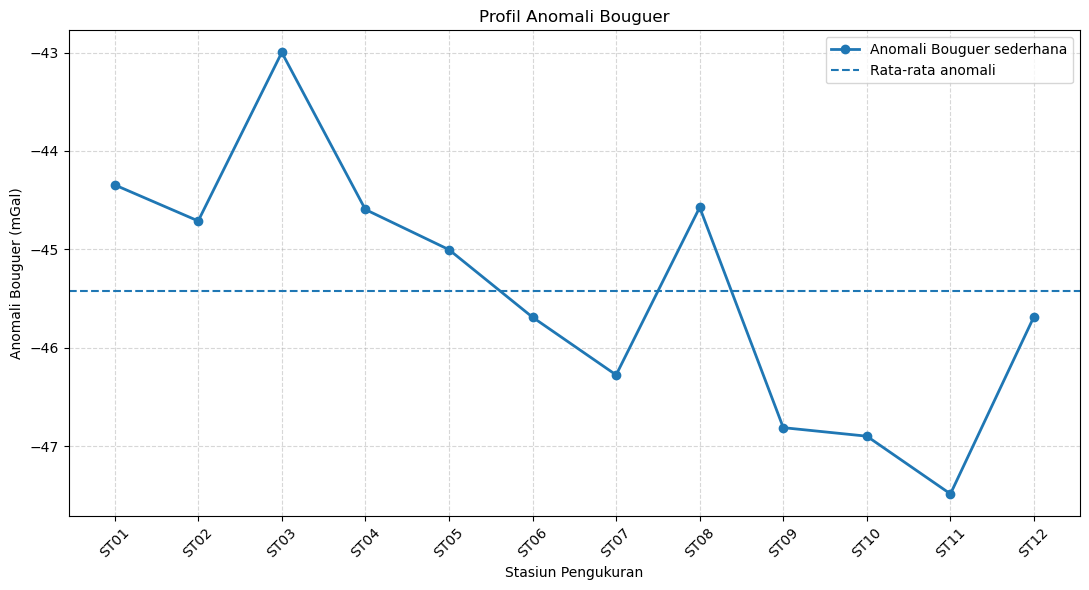

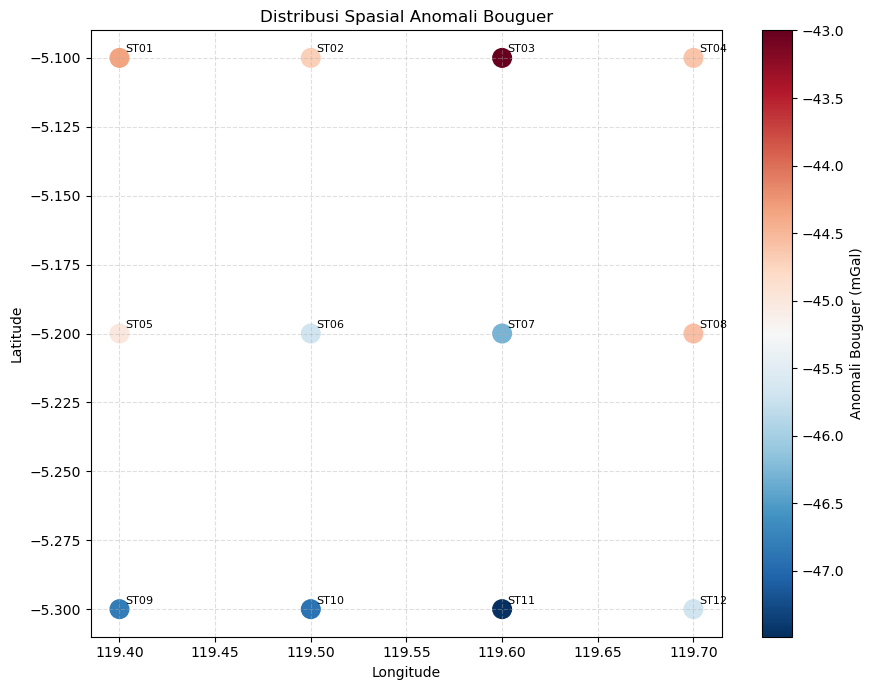


INTERPRETASI ZONA BAWAH PERMUKAAN
ST01 (-5.100, 119.400): Anomali relatif tinggi. Dapat berkaitan dengan material berdensitas lebih tinggi daripada lingkungan sekitarnya.
ST02 (-5.100, 119.500): Anomali relatif tinggi. Dapat berkaitan dengan material berdensitas lebih tinggi daripada lingkungan sekitarnya.
ST03 (-5.100, 119.600): Anomali relatif tinggi. Dapat berkaitan dengan material berdensitas lebih tinggi daripada lingkungan sekitarnya.
ST04 (-5.100, 119.700): Anomali relatif tinggi. Dapat berkaitan dengan material berdensitas lebih tinggi daripada lingkungan sekitarnya.
ST05 (-5.200, 119.400): Anomali relatif tinggi. Dapat berkaitan dengan material berdensitas lebih tinggi daripada lingkungan sekitarnya.
ST06 (-5.200, 119.500): Anomali relatif rendah. Dapat berkaitan dengan material berdensitas lebih rendah daripada lingkungan sekitarnya.
ST07 (-5.200, 119.600): Anomali relatif rendah. Dapat berkaitan dengan material berdensitas lebih rendah daripada lingkungan sekitarnya.
ST08 (

In [14]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# TASK 2: PENGOLAHAN DATA GRAVITASI
# Koreksi gravitasi, anomali Bouguer, visualisasi, interpretasi
# ============================================================

# 1. INPUT DATA
# Data simulasi untuk contoh pengolahan.
# Gravitasi terukur dinyatakan dalam mGal.

data = {
    "Stasiun": [
        "ST01", "ST02", "ST03", "ST04", "ST05",
        "ST06", "ST07", "ST08", "ST09", "ST10",
        "ST11", "ST12"
    ],
    "Latitude": [
        -5.10, -5.10, -5.10, -5.10,
        -5.20, -5.20, -5.20, -5.20,
        -5.30, -5.30, -5.30, -5.30
    ],
    "Longitude": [
        119.40, 119.50, 119.60, 119.70,
        119.40, 119.50, 119.60, 119.70,
        119.40, 119.50, 119.60, 119.70
    ],
    "Elevasi_m": [
        20, 25, 30, 35,
        40, 45, 50, 55,
        60, 65, 70, 75
    ],
    "g_terukur_mGal": [
        978025.2, 978023.8, 978024.5, 978021.9,
        978022.1, 978020.4, 978018.8, 978019.5,
        978017.9, 978016.8, 978015.2, 978016.0
    ],
    # Contoh koreksi drift bertanda yang sudah ditentukan
    "Koreksi_Drift_mGal": [
        0.00, 0.05, 0.08, 0.10,
        0.12, 0.15, 0.18, 0.20,
        0.22, 0.25, 0.28, 0.30
    ]
}

df = pd.DataFrame(data)

# 2. PARAMETER PENGOLAHAN
densitas = 2.67  # g/cm^3

# 3. VALIDASI DATA
if df.empty:
    raise ValueError("Data gravitasi tidak tersedia.")

if df.isnull().any().any():
    raise ValueError("Terdapat data kosong. Periksa input.")

if df["Stasiun"].duplicated().any():
    raise ValueError("Nama stasiun harus unik.")

kolom_numerik = [
    "Latitude", "Longitude", "Elevasi_m",
    "g_terukur_mGal", "Koreksi_Drift_mGal"
]

if not np.isfinite(df[kolom_numerik].to_numpy()).all():
    raise ValueError("Data mengandung nilai numerik tidak valid.")

if not df["Latitude"].between(-90, 90).all():
    raise ValueError("Latitude tidak valid.")

if not df["Longitude"].between(-180, 180).all():
    raise ValueError("Longitude tidak valid.")

if (df["Elevasi_m"] < 0).any():
    raise ValueError("Kode contoh ini menggunakan elevasi di atas datum.")

if densitas <= 0:
    raise ValueError("Densitas harus lebih besar dari nol.")

# 4. KOREKSI DRIFT
df["g_koreksi_drift_mGal"] = (
    df["g_terukur_mGal"] + df["Koreksi_Drift_mGal"]
)

# 5. MENGHITUNG GRAVITASI NORMAL
# Rumus gravitasi normal GRS80
phi = np.radians(df["Latitude"].to_numpy())

df["g_normal_mGal"] = (
    978032.67715
    * (1 + 0.001931851353 * np.sin(phi)**2)
    / np.sqrt(1 - 0.0066943800229 * np.sin(phi)**2)
)

# 6. KOREKSI UDARA BEBAS
df["Koreksi_Udara_Bebas_mGal"] = (
    0.3086 * df["Elevasi_m"]
)

# 7. KOREKSI BOUGUER
df["Koreksi_Bouguer_mGal"] = (
    0.04193 * densitas * df["Elevasi_m"]
)

# 8. MENGHITUNG ANOMALI UDARA BEBAS
df["Anomali_Udara_Bebas_mGal"] = (
    df["g_koreksi_drift_mGal"]
    - df["g_normal_mGal"]
    + df["Koreksi_Udara_Bebas_mGal"]
)

# 9. MENGHITUNG ANOMALI BOUGUER SEDERHANA
df["Anomali_Bouguer_mGal"] = (
    df["g_koreksi_drift_mGal"]
    - df["g_normal_mGal"]
    + df["Koreksi_Udara_Bebas_mGal"]
    - df["Koreksi_Bouguer_mGal"]
)

# 10. MENENTUKAN ZONA ANOMALI
rata_rata = df["Anomali_Bouguer_mGal"].mean()

def klasifikasi(nilai):
    if nilai > rata_rata:
        return "Anomali relatif tinggi"
    elif nilai < rata_rata:
        return "Anomali relatif rendah"
    else:
        return "Mendekati rata-rata"

df["Zona_Anomali"] = (
    df["Anomali_Bouguer_mGal"].apply(klasifikasi)
)

# 11. MENAMPILKAN TABEL PENGOLAHAN
kolom_output = [
    "Stasiun",
    "Latitude",
    "Longitude",
    "Elevasi_m",
    "g_terukur_mGal",
    "Koreksi_Drift_mGal",
    "g_koreksi_drift_mGal",
    "g_normal_mGal",
    "Koreksi_Udara_Bebas_mGal",
    "Koreksi_Bouguer_mGal",
    "Anomali_Udara_Bebas_mGal",
    "Anomali_Bouguer_mGal",
    "Zona_Anomali"
]

print("\nTABEL PENGOLAHAN DATA GRAVITASI")
print("=" * 110)
print(
    df[kolom_output].to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# 12. STATISTIK ANOMALI
anomali = df["Anomali_Bouguer_mGal"]

print("\nSTATISTIK ANOMALI BOUGUER")
print(f"Minimum  : {anomali.min():.3f} mGal")
print(f"Maksimum : {anomali.max():.3f} mGal")
print(f"Rata-rata: {anomali.mean():.3f} mGal")
print(f"Rentang  : {anomali.max() - anomali.min():.3f} mGal")

# 13. GRAFIK PROFIL ANOMALI
plt.figure(figsize=(11, 6))

plt.plot(
    df["Stasiun"],
    df["Anomali_Bouguer_mGal"],
    marker="o",
    linewidth=2,
    label="Anomali Bouguer sederhana"
)

plt.axhline(
    rata_rata,
    linestyle="--",
    label="Rata-rata anomali"
)

plt.xlabel("Stasiun Pengukuran")
plt.ylabel("Anomali Bouguer (mGal)")
plt.title("Profil Anomali Bouguer")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig("grafik_anomali_bouguer.png", dpi=300)
plt.show()

# 14. PETA SEBARAN ANOMALI
# Menggunakan scatter plot berdasarkan koordinat.
# Ini bukan hasil interpolasi grid.

plt.figure(figsize=(9, 7))

sc = plt.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df["Anomali_Bouguer_mGal"],
    s=180,
    cmap="RdBu_r"
)

for _, row in df.iterrows():
    plt.annotate(
        row["Stasiun"],
        (row["Longitude"], row["Latitude"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

plt.colorbar(sc, label="Anomali Bouguer (mGal)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Distribusi Spasial Anomali Bouguer")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("peta_sebaran_anomali_bouguer.png", dpi=300)
plt.show()

# 15. INTERPRETASI ZONA ANOMALI
print("\nINTERPRETASI ZONA BAWAH PERMUKAAN")
print("=" * 60)

for _, row in df.iterrows():
    nilai = row["Anomali_Bouguer_mGal"]

    if nilai > rata_rata:
        interpretasi = (
            "Anomali relatif tinggi. Dapat berkaitan dengan "
            "material berdensitas lebih tinggi daripada "
            "lingkungan sekitarnya."
        )
    elif nilai < rata_rata:
        interpretasi = (
            "Anomali relatif rendah. Dapat berkaitan dengan "
            "material berdensitas lebih rendah daripada "
            "lingkungan sekitarnya."
        )
    else:
        interpretasi = (
            "Nilai berada pada rata-rata anomali data."
        )

    print(
        f"{row['Stasiun']} ({row['Latitude']:.3f}, "
        f"{row['Longitude']:.3f}): {interpretasi}"
    )

# 16. MENYIMPAN HASIL
df[kolom_output].to_csv(
    "tabel_pengolahan_gravitasi.csv",
    index=False
)

try:
    with pd.ExcelWriter("hasil_pengolahan_gravitasi.xlsx") as writer:
        df[kolom_output].to_excel(
            writer,
            sheet_name="Pengolahan",
            index=False
        )

        pd.DataFrame({
            "Parameter": [
                "Densitas Bouguer (g/cm3)",
                "Anomali minimum (mGal)",
                "Anomali maksimum (mGal)",
                "Anomali rata-rata (mGal)",
                "Rentang anomali (mGal)"
            ],
            "Nilai": [
                densitas,
                anomali.min(),
                anomali.max(),
                rata_rata,
                anomali.max() - anomali.min()
            ]
        }).to_excel(
            writer,
            sheet_name="Statistik",
            index=False
        )

    print("\nFile Excel berhasil disimpan.")

except ImportError:
    print("\nExcel memerlukan pustaka openpyxl.")
    print("Instal dengan: pip install openpyxl")

print("File CSV berhasil disimpan.")
print("Pengolahan data gravitasi selesai.")



3. **Context:** Analisis dilakukan menggunakan data gravitasi dari beberapa titik pengukuran di lapangan. Perbedaan nilai gravitasi pada setiap lokasi dapat menunjukkan adanya variasi densitas material bawah permukaan yang berkaitan dengan kondisi geologi dan struktur bawah permukaan.

   **Output:** Menghasilkan gambaran variasi densitas bawah permukaan berdasarkan distribusi nilai anomali gravitasi.


ANALISIS VARIASI DENSITAS BAWAH PERMUKAAN
Anomali minimum  : -47.487 mGal
Anomali maksimum : -42.999 mGal
Anomali rata-rata: -45.423 mGal
Standar deviasi  : 1.292 mGal

TABEL ZONA ANOMALI
 Latitude  Longitude  Anomali_Bouguer_mGal Zona_Densitas_Indikatif
   -5.100    119.400               -44.345          Relatif tinggi
   -5.100    119.500               -44.712          Relatif tinggi
   -5.100    119.600               -42.999          Relatif tinggi
   -5.100    119.700               -44.596          Relatif tinggi
   -5.200    119.400               -45.004                Menengah
   -5.200    119.500               -45.690                Menengah
   -5.200    119.600               -46.277          Relatif rendah
   -5.200    119.700               -44.574          Relatif tinggi
   -5.300    119.400               -46.813          Relatif rendah
   -5.300    119.500               -46.900          Relatif rendah
   -5.300    119.600               -47.487          Relatif rendah
   -5.3

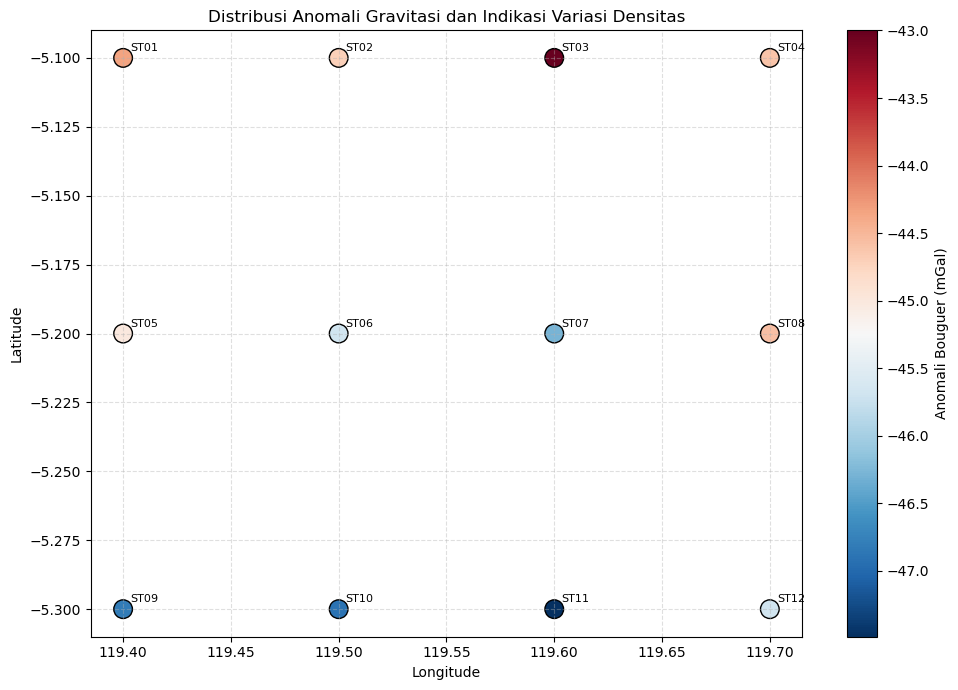

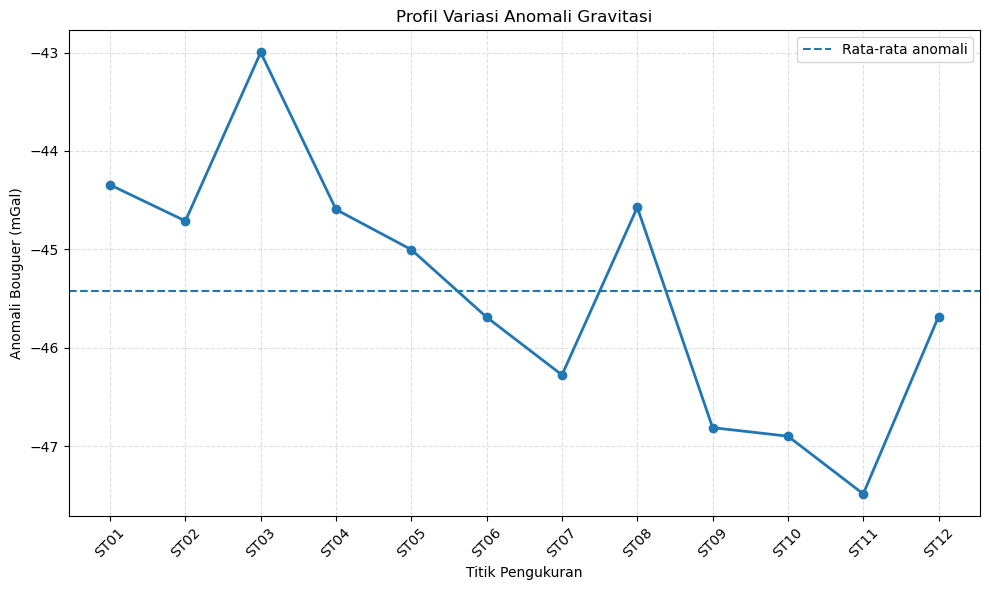


INTERPRETASI GEOLOGI AWAL

Zona anomali relatif tinggi:
- ST01: -44.345 mGal
- ST02: -44.712 mGal
- ST03: -42.999 mGal
- ST04: -44.596 mGal
- ST08: -44.574 mGal

Zona anomali relatif rendah:
- ST07: -46.277 mGal
- ST09: -46.813 mGal
- ST10: -46.900 mGal
- ST11: -47.487 mGal

Catatan interpretasi:
Anomali relatif tinggi dapat mengindikasikan material yang lebih rapat dibandingkan sekitarnya.
Anomali relatif rendah dapat mengindikasikan material yang kurang rapat dibandingkan sekitarnya.
Interpretasi ini masih bersifat indikatif. Kedalaman, geometri, topografi, dan geologi setempat perlu dipertimbangkan sebelum menyimpulkan struktur.

Hasil interpretasi tersimpan dalam hasil_variasi_densitas.csv


In [15]:

# ============================================================
# TASK 3: ANALISIS VARIASI DENSITAS BAWAH PERMUKAAN
# ============================================================
# Melanjutkan kode Task 2.
# Pastikan DataFrame df sudah memiliki kolom:
# Latitude, Longitude, dan Anomali_Bouguer_mGal.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. MEMERIKSA DATA ANOMALI
kolom = [
    "Latitude",
    "Longitude",
    "Anomali_Bouguer_mGal"
]

if df[kolom].isnull().any().any():
    raise ValueError("Data anomali atau koordinat masih kosong.")

if len(df) < 3:
    raise ValueError("Diperlukan minimal 3 titik pengukuran.")

anomali = df["Anomali_Bouguer_mGal"]

# 2. MENGHITUNG STATISTIK ANOMALI
anomali_min = anomali.min()
anomali_max = anomali.max()
anomali_rata = anomali.mean()
anomali_std = anomali.std()

print("\nANALISIS VARIASI DENSITAS BAWAH PERMUKAAN")
print("=" * 55)
print(f"Anomali minimum  : {anomali_min:.3f} mGal")
print(f"Anomali maksimum : {anomali_max:.3f} mGal")
print(f"Anomali rata-rata: {anomali_rata:.3f} mGal")
print(f"Standar deviasi  : {anomali_std:.3f} mGal")

# 3. MENGELOMPOKKAN ZONA ANOMALI
# Pengelompokan relatif terhadap rata-rata dan
# standar deviasi data, bukan batas geologi universal.

def klasifikasi_zona(nilai):
    if anomali_std == 0:
        return "Anomali seragam"

    if nilai > anomali_rata + 0.5 * anomali_std:
        return "Relatif tinggi"
    elif nilai < anomali_rata - 0.5 * anomali_std:
        return "Relatif rendah"
    else:
        return "Menengah"

df["Zona_Densitas_Indikatif"] = anomali.apply(
    klasifikasi_zona
)

# 4. MENAMPILKAN TABEL INTERPRETASI
print("\nTABEL ZONA ANOMALI")
print(
    df[
        [
            "Latitude",
            "Longitude",
            "Anomali_Bouguer_mGal",
            "Zona_Densitas_Indikatif"
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# 5. MEMBUAT PETA SEBARAN ANOMALI
plt.figure(figsize=(10, 7))

sc = plt.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df["Anomali_Bouguer_mGal"],
    cmap="RdBu_r",
    s=180,
    edgecolors="black"
)

for i, row in df.iterrows():
    plt.annotate(
        str(row.get("Stasiun", i)),
        (row["Longitude"], row["Latitude"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.colorbar(sc, label="Anomali Bouguer (mGal)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Distribusi Anomali Gravitasi dan Indikasi Variasi Densitas")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("variasi_densitas_bawah_permukaan.png", dpi=300)
plt.show()

# 6. MEMBUAT PROFIL ANOMALI
plt.figure(figsize=(10, 6))

plt.plot(
    range(len(df)),
    df["Anomali_Bouguer_mGal"],
    marker="o",
    linewidth=2
)

plt.axhline(
    anomali_rata,
    linestyle="--",
    label="Rata-rata anomali"
)

plt.xticks(
    range(len(df)),
    df["Stasiun"] if "Stasiun" in df.columns
    else range(1, len(df) + 1),
    rotation=45
)

plt.xlabel("Titik Pengukuran")
plt.ylabel("Anomali Bouguer (mGal)")
plt.title("Profil Variasi Anomali Gravitasi")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.savefig("profil_variasi_densitas.png", dpi=300)
plt.show()

# 7. INTERPRETASI BERDASARKAN PRINSIP GRAVITASI
print("\nINTERPRETASI GEOLOGI AWAL")
print("=" * 55)

zona_tinggi = df[
    df["Zona_Densitas_Indikatif"] == "Relatif tinggi"
]

zona_rendah = df[
    df["Zona_Densitas_Indikatif"] == "Relatif rendah"
]

print("\nZona anomali relatif tinggi:")
if zona_tinggi.empty:
    print("Tidak ada titik yang memenuhi kriteria.")
else:
    for _, row in zona_tinggi.iterrows():
        print(
            f"- {row.get('Stasiun', 'Titik')}: "
            f"{row['Anomali_Bouguer_mGal']:.3f} mGal"
        )

print("\nZona anomali relatif rendah:")
if zona_rendah.empty:
    print("Tidak ada titik yang memenuhi kriteria.")
else:
    for _, row in zona_rendah.iterrows():
        print(
            f"- {row.get('Stasiun', 'Titik')}: "
            f"{row['Anomali_Bouguer_mGal']:.3f} mGal"
        )

print("\nCatatan interpretasi:")
print(
    "Anomali relatif tinggi dapat mengindikasikan material "
    "yang lebih rapat dibandingkan sekitarnya."
)
print(
    "Anomali relatif rendah dapat mengindikasikan material "
    "yang kurang rapat dibandingkan sekitarnya."
)
print(
    "Interpretasi ini masih bersifat indikatif. "
    "Kedalaman, geometri, topografi, dan geologi setempat "
    "perlu dipertimbangkan sebelum menyimpulkan struktur."
)

# 8. MENYIMPAN HASIL INTERPRETASI
df.to_csv(
    "hasil_variasi_densitas.csv",
    index=False
)

print("\nHasil interpretasi tersimpan dalam hasil_variasi_densitas.csv")



4. **Input:** Masukkan data berupa nomor titik, koordinat, elevasi, nilai gravitasi hasil pengukuran, serta data pendukung lainnya yang diperlukan untuk proses koreksi gravitasi.

   **Output:** Menghasilkan data terstruktur yang berisi hasil koreksi dan nilai anomali gravitasi pada setiap titik pengukuran.

In [17]:

import numpy as np
import pandas as pd

# ============================================================
# PENGOLAHAN DATA GRAVITASI
# Input data dan perhitungan anomali Bouguer sederhana
# ============================================================

# 1. INPUT DATA
# Data simulasi; g terukur dalam mGal dan elevasi dalam meter.

data = {
    "Nomor_Titik": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Latitude": [
        -5.10, -5.12, -5.14, -5.16, -5.18,
        -5.20, -5.22, -5.24, -5.26, -5.28
    ],
    "Longitude": [
        119.40, 119.42, 119.44, 119.46, 119.48,
        119.50, 119.52, 119.54, 119.56, 119.58
    ],
    "Elevasi_m": [
        20, 25, 30, 35, 40, 45, 50, 55, 60, 65
    ],
    "g_terukur_mGal": [
        978025.2, 978023.8, 978024.5, 978021.9,
        978022.1, 978020.4, 978018.8, 978019.5,
        978017.9, 978016.8
    ],
    # Koreksi drift bertanda, diasumsikan sudah dihitung
    "Koreksi_Drift_mGal": [
        0.00, 0.05, 0.08, 0.10, 0.12,
        0.15, 0.18, 0.20, 0.22, 0.25
    ]
}

df = pd.DataFrame(data)

# 2. PARAMETER PENGOLAHAN
densitas = 2.67  # g/cm^3

# 3. VALIDASI INPUT
if df.empty:
    raise ValueError("Data pengukuran belum tersedia.")

if df.isnull().any().any():
    raise ValueError("Terdapat data kosong pada tabel input.")

if df["Nomor_Titik"].duplicated().any():
    raise ValueError("Nomor titik tidak boleh duplikat.")

kolom_numerik = [
    "Latitude", "Longitude", "Elevasi_m",
    "g_terukur_mGal", "Koreksi_Drift_mGal"
]

if not np.isfinite(df[kolom_numerik].to_numpy()).all():
    raise ValueError("Ditemukan nilai numerik tidak valid.")

if not df["Latitude"].between(-90, 90).all():
    raise ValueError("Koordinat latitude tidak valid.")

if not df["Longitude"].between(-180, 180).all():
    raise ValueError("Koordinat longitude tidak valid.")

if (df["Elevasi_m"] < 0).any():
    raise ValueError("Contoh ini menggunakan elevasi di atas datum.")

if densitas <= 0:
    raise ValueError("Densitas Bouguer harus lebih besar dari nol.")

# 4. KOREKSI DRIFT
# Asumsi: nilai koreksi drift sudah memiliki tanda yang benar.
df["g_koreksi_drift_mGal"] = (
    df["g_terukur_mGal"] + df["Koreksi_Drift_mGal"]
)

# 5. GRAVITASI NORMAL BERDASARKAN LATITUDE
phi = np.radians(df["Latitude"].to_numpy())

df["g_normal_mGal"] = (
    978032.67715
    * (1 + 0.001931851353 * np.sin(phi)**2)
    / np.sqrt(1 - 0.0066943800229 * np.sin(phi)**2)
)

# 6. KOREKSI UDARA BEBAS
df["Koreksi_Udara_Bebas_mGal"] = (
    0.3086 * df["Elevasi_m"]
)

# 7. KOREKSI BOUGUER SEDERHANA
df["Koreksi_Bouguer_mGal"] = (
    0.04193 * densitas * df["Elevasi_m"]
)

# 8. ANOMALI UDARA BEBAS
df["Anomali_Udara_Bebas_mGal"] = (
    df["g_koreksi_drift_mGal"]
    - df["g_normal_mGal"]
    + df["Koreksi_Udara_Bebas_mGal"]
)

# 9. ANOMALI BOUGUER SEDERHANA
df["Anomali_Bouguer_mGal"] = (
    df["g_koreksi_drift_mGal"]
    - df["g_normal_mGal"]
    + df["Koreksi_Udara_Bebas_mGal"]
    - df["Koreksi_Bouguer_mGal"]
)

# 10. MENYUSUN TABEL OUTPUT
kolom_output = [
    "Nomor_Titik",
    "Latitude",
    "Longitude",
    "Elevasi_m",
    "g_terukur_mGal",
    "Koreksi_Drift_mGal",
    "g_koreksi_drift_mGal",
    "g_normal_mGal",
    "Koreksi_Udara_Bebas_mGal",
    "Koreksi_Bouguer_mGal",
    "Anomali_Udara_Bebas_mGal",
    "Anomali_Bouguer_mGal"
]

hasil = df[kolom_output].copy()

# 11. MENAMPILKAN HASIL
print("=" * 100)
print("HASIL PENGOLAHAN DATA GRAVITASI")
print("=" * 100)

print(
    hasil.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# 12. MENYIMPAN DATA HASIL
hasil.to_csv(
    "hasil_koreksi_dan_anomali_gravitasi.csv",
    index=False
)

try:
    hasil.to_excel(
        "hasil_koreksi_dan_anomali_gravitasi.xlsx",
        index=False
    )
    print("\nFile Excel berhasil disimpan.")
except ImportError:
    print("\nInstal openpyxl untuk menyimpan Excel:")
    print("pip install openpyxl")

print("File CSV berhasil disimpan.")
print("Pengolahan data selesai.")



HASIL PENGOLAHAN DATA GRAVITASI
 Nomor_Titik  Latitude  Longitude  Elevasi_m  g_terukur_mGal  Koreksi_Drift_mGal  g_koreksi_drift_mGal  g_normal_mGal  Koreksi_Udara_Bebas_mGal  Koreksi_Bouguer_mGal  Anomali_Udara_Bebas_mGal  Anomali_Bouguer_mGal
           1   -5.1000   119.4000         20     978025.2000              0.0000           978025.2000    978073.4782                    6.1720                2.2391                  -42.1062              -44.3453
           2   -5.1200   119.4200         25     978023.8000              0.0500           978023.8500    978073.7980                    7.7150                2.7988                  -42.2330              -45.0318
           3   -5.1400   119.4400         30     978024.5000              0.0800           978024.5800    978074.1190                    9.2580                3.3586                  -40.2810              -43.6396
           4   -5.1600   119.4600         35     978021.9000              0.1000           978022.0000    978074

5. **Constraints:** Gunakan konsep metode gravitasi dan persamaan koreksi yang sesuai. Pastikan seluruh satuan konsisten dan setiap koreksi dilakukan secara sistematis. Interpretasi anomali gravitasi tidak boleh langsung menentukan jenis batuan secara mutlak tanpa mempertimbangkan informasi geologi pendukung.

   **Output:** Menghasilkan hasil pengolahan gravitasi yang konsisten dengan data pengukuran dan interpretasi yang sesuai dengan prinsip metode gravitasi.


HASIL PENGOLAHAN DATA GRAVITASI
 Nomor_Titik  Latitude  Longitude  Elevasi_m  g_terukur_mGal  Koreksi_Drift_mGal  g_setelah_drift_mGal  g_normal_mGal  Koreksi_Udara_Bebas_mGal  Koreksi_Bouguer_mGal  Anomali_Udara_Bebas_mGal  Anomali_Bouguer_mGal      Interpretasi_Awal
           1   -5.1000   119.4000         20     978025.2000              0.0000           978025.2000    978073.4782                    6.1720                2.2391                  -42.1062              -44.3453 Anomali relatif tinggi
           2   -5.1200   119.4200         25     978023.8000              0.0500           978023.8500    978073.7980                    7.7150                2.7988                  -42.2330              -45.0318 Anomali relatif tinggi
           3   -5.1400   119.4400         30     978024.5000              0.0800           978024.5800    978074.1190                    9.2580                3.3586                  -40.2810              -43.6396 Anomali relatif tinggi
           4   -5.1

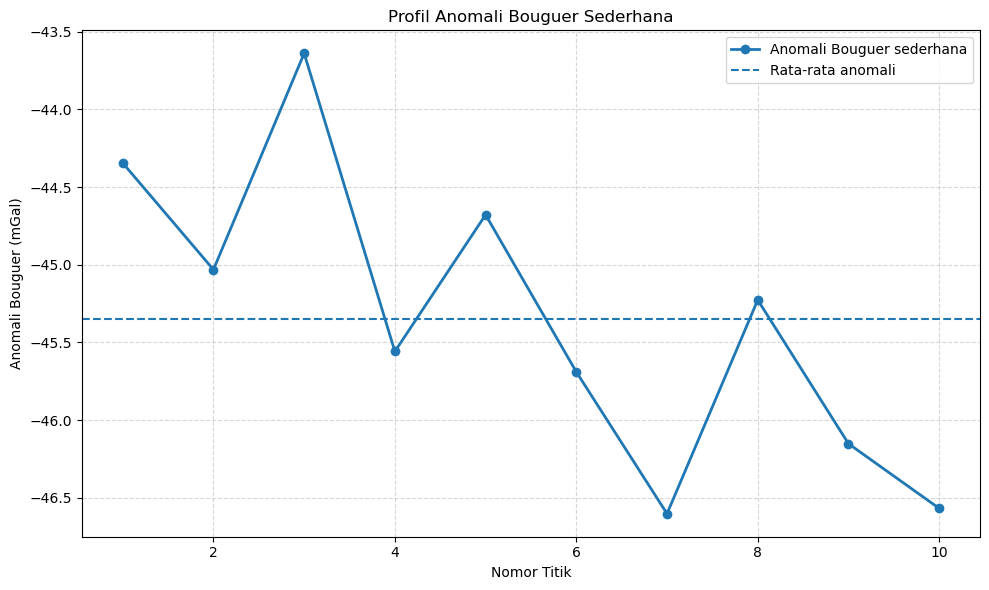

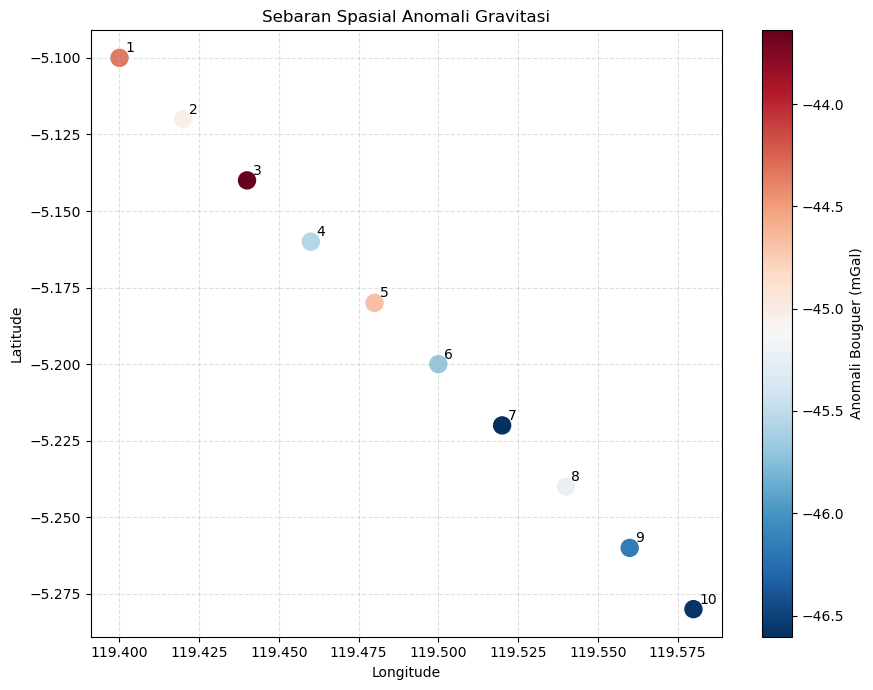


Data input asli tetap dipertahankan.
Hasil CSV dan visualisasi telah dibuat.
Pengolahan selesai.


In [18]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# TASK 5: PENGOLAHAN DAN INTERPRETASI DATA GRAVITASI
# ============================================================
# Satuan:
# Gravitasi       : mGal
# Elevasi         : meter
# Densitas        : g/cm^3
# Koordinat       : derajat desimal
#
# Data di bawah merupakan data simulasi.
# Ganti dengan data pengukuran asli untuk analisis lapangan.
# ============================================================

# 1. INPUT DATA
data = {
    "Nomor_Titik": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Latitude": [
        -5.10, -5.12, -5.14, -5.16, -5.18,
        -5.20, -5.22, -5.24, -5.26, -5.28
    ],
    "Longitude": [
        119.40, 119.42, 119.44, 119.46, 119.48,
        119.50, 119.52, 119.54, 119.56, 119.58
    ],
    "Elevasi_m": [
        20, 25, 30, 35, 40, 45, 50, 55, 60, 65
    ],
    "g_terukur_mGal": [
        978025.2, 978023.8, 978024.5, 978021.9,
        978022.1, 978020.4, 978018.8, 978019.5,
        978017.9, 978016.8
    ],
    # Koreksi drift bertanda yang sudah ditentukan
    "Koreksi_Drift_mGal": [
        0.00, 0.05, 0.08, 0.10, 0.12,
        0.15, 0.18, 0.20, 0.22, 0.25
    ]
}

df = pd.DataFrame(data)

# Simpan salinan data input agar tidak berubah
data_asli = df.copy(deep=True)

# 2. PARAMETER
densitas = 2.67  # g/cm^3

# 3. VALIDASI DATA
if df.empty:
    raise ValueError("Data pengukuran kosong.")

if df.isnull().any().any():
    raise ValueError("Terdapat data kosong.")

if df["Nomor_Titik"].duplicated().any():
    raise ValueError("Nomor titik harus unik.")

kolom_numerik = [
    "Latitude", "Longitude", "Elevasi_m",
    "g_terukur_mGal", "Koreksi_Drift_mGal"
]

if not np.isfinite(df[kolom_numerik].to_numpy()).all():
    raise ValueError("Terdapat nilai numerik yang tidak valid.")

if not df["Latitude"].between(-90, 90).all():
    raise ValueError("Latitude di luar rentang valid.")

if not df["Longitude"].between(-180, 180).all():
    raise ValueError("Longitude di luar rentang valid.")

if (df["Elevasi_m"] < 0).any():
    raise ValueError(
        "Kode ini mengasumsikan elevasi stasiun di atas datum."
    )

if densitas <= 0:
    raise ValueError("Densitas harus lebih besar dari nol.")

# 4. KOREKSI DRIFT
# Nilai koreksi drift diasumsikan sudah memiliki tanda
# yang benar dan ditambahkan ke gravitasi terukur.
df["g_setelah_drift_mGal"] = (
    df["g_terukur_mGal"] + df["Koreksi_Drift_mGal"]
)

# 5. GRAVITASI NORMAL (GRS80)
phi = np.radians(df["Latitude"].to_numpy())

df["g_normal_mGal"] = (
    978032.67715
    * (1 + 0.001931851353 * np.sin(phi)**2)
    / np.sqrt(1 - 0.0066943800229 * np.sin(phi)**2)
)

# 6. KOREKSI UDARA BEBAS
# Besar koreksi = 0.3086 * elevasi
df["Koreksi_Udara_Bebas_mGal"] = (
    0.3086 * df["Elevasi_m"]
)

# 7. KOREKSI BOUGUER SEDERHANA
# Besar koreksi = 0.04193 * densitas * elevasi
df["Koreksi_Bouguer_mGal"] = (
    0.04193 * densitas * df["Elevasi_m"]
)

# 8. ANOMALI UDARA BEBAS
df["Anomali_Udara_Bebas_mGal"] = (
    df["g_setelah_drift_mGal"]
    - df["g_normal_mGal"]
    + df["Koreksi_Udara_Bebas_mGal"]
)

# 9. ANOMALI BOUGUER SEDERHANA
df["Anomali_Bouguer_mGal"] = (
    df["g_setelah_drift_mGal"]
    - df["g_normal_mGal"]
    + df["Koreksi_Udara_Bebas_mGal"]
    - df["Koreksi_Bouguer_mGal"]
)

# 10. INTERPRETASI RELATIF
# Pengelompokan berdasarkan rata-rata data.
# Ini bukan batas densitas atau jenis batuan tertentu.
rata_rata = df["Anomali_Bouguer_mGal"].mean()

def interpretasi_anomali(nilai):
    if nilai > rata_rata:
        return "Anomali relatif tinggi"
    elif nilai < rata_rata:
        return "Anomali relatif rendah"
    return "Mendekati rata-rata"

df["Interpretasi_Awal"] = (
    df["Anomali_Bouguer_mGal"].apply(interpretasi_anomali)
)

# 11. MENAMPILKAN HASIL
kolom_hasil = [
    "Nomor_Titik",
    "Latitude",
    "Longitude",
    "Elevasi_m",
    "g_terukur_mGal",
    "Koreksi_Drift_mGal",
    "g_setelah_drift_mGal",
    "g_normal_mGal",
    "Koreksi_Udara_Bebas_mGal",
    "Koreksi_Bouguer_mGal",
    "Anomali_Udara_Bebas_mGal",
    "Anomali_Bouguer_mGal",
    "Interpretasi_Awal"
]

print("\nHASIL PENGOLAHAN DATA GRAVITASI")
print("=" * 100)

print(
    df[kolom_hasil].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nSTATISTIK ANOMALI BOUGUER")
print(f"Minimum  : {df['Anomali_Bouguer_mGal'].min():.4f} mGal")
print(f"Maksimum : {df['Anomali_Bouguer_mGal'].max():.4f} mGal")
print(f"Rata-rata: {rata_rata:.4f} mGal")

# 12. VISUALISASI ANOMALI
plt.figure(figsize=(10, 6))

plt.plot(
    df["Nomor_Titik"],
    df["Anomali_Bouguer_mGal"],
    marker="o",
    linewidth=2,
    label="Anomali Bouguer sederhana"
)

plt.axhline(
    rata_rata,
    linestyle="--",
    label="Rata-rata anomali"
)

plt.xlabel("Nomor Titik")
plt.ylabel("Anomali Bouguer (mGal)")
plt.title("Profil Anomali Bouguer Sederhana")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig("profil_anomali_bouguer.png", dpi=300)
plt.show()

# 13. PETA SEBARAN TITIK ANOMALI
plt.figure(figsize=(9, 7))

sc = plt.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df["Anomali_Bouguer_mGal"],
    s=150,
    cmap="RdBu_r"
)

for _, row in df.iterrows():
    plt.annotate(
        str(row["Nomor_Titik"]),
        (row["Longitude"], row["Latitude"]),
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.colorbar(sc, label="Anomali Bouguer (mGal)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Sebaran Spasial Anomali Gravitasi")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("peta_anomali_bouguer.png", dpi=300)
plt.show()

# 14. MENYIMPAN HASIL
df[kolom_hasil].to_csv(
    "hasil_akhir_gravitasi.csv",
    index=False
)

try:
    with pd.ExcelWriter("hasil_akhir_gravitasi.xlsx") as writer:
        df[kolom_hasil].to_excel(
            writer,
            sheet_name="Hasil Pengolahan",
            index=False
        )
except ImportError:
    print("Excel tidak tersimpan. Instal openpyxl terlebih dahulu.")

# Memastikan input asli tidak berubah
pd.testing.assert_frame_equal(df[data_asli.columns], data_asli)

print("\nData input asli tetap dipertahankan.")
print("Hasil CSV dan visualisasi telah dibuat.")
print("Pengolahan selesai.")



**PROMPT 4**

1. **Role:** Anda berperan sebagai seorang ahli geofisika yang memiliki keahlian dalam metode geomagnetik, khususnya pengolahan dan interpretasi data medan magnet bumi. Anda mampu mengolah nilai medan magnet total, melakukan koreksi data, menghitung anomali magnetik, serta menginterpretasikan pola anomali untuk mengetahui kemungkinan variasi sifat magnetik material bawah permukaan.

   **Output:** Menghasilkan analisis data geomagnetik berupa hasil koreksi, nilai anomali magnetik, visualisasi distribusi anomali, serta interpretasi zona magnetik bawah permukaan.

HASIL PENGOLAHAN DATA GEOMAGNETIK
Titik  Latitude  Longitude  Magnet_Terukur_nT  Variasi_Harian_nT  Medan_Referensi_nT  Magnet_Setelah_Koreksi_Harian_nT  Anomali_Magnetik_nT
 ST01     -5.10     119.40              45020                  5               45000                             45015                   15
 ST02     -5.10     119.50              45035                  8               45002                             45027                   25
 ST03     -5.10     119.60              45048                 10               45004                             45038                   34
 ST04     -5.10     119.70              45030                  7               45006                             45023                   17
 ST05     -5.20     119.40              45010                  4               45001                             45006                    5
 ST06     -5.20     119.50              44985                  2               45003                             44983        

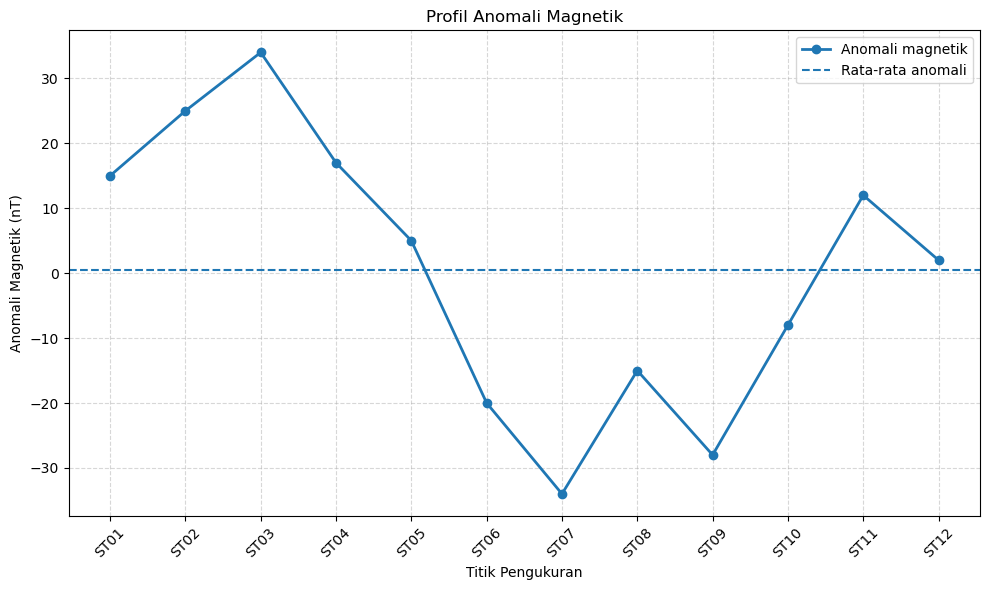

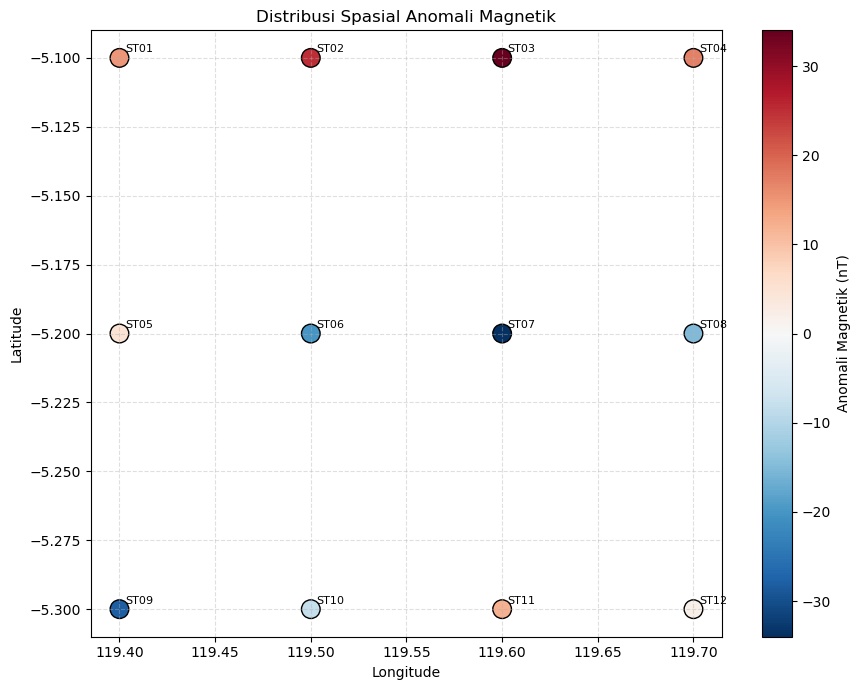


INTERPRETASI ZONA MAGNETIK
ST01: 15.00 nT - Relatif tinggi. Dapat menunjukkan material dengan respons magnetik relatif kuat dibandingkan lingkungan sekitarnya.
ST02: 25.00 nT - Relatif tinggi. Dapat menunjukkan material dengan respons magnetik relatif kuat dibandingkan lingkungan sekitarnya.
ST03: 34.00 nT - Relatif tinggi. Dapat menunjukkan material dengan respons magnetik relatif kuat dibandingkan lingkungan sekitarnya.
ST04: 17.00 nT - Relatif tinggi. Dapat menunjukkan material dengan respons magnetik relatif kuat dibandingkan lingkungan sekitarnya.
ST05: 5.00 nT - Menengah. Respons magnetik berada di sekitar kisaran menengah data pengukuran.
ST06: -20.00 nT - Relatif rendah. Dapat menunjukkan material dengan respons magnetik relatif lemah dibandingkan lingkungan sekitarnya.
ST07: -34.00 nT - Relatif rendah. Dapat menunjukkan material dengan respons magnetik relatif lemah dibandingkan lingkungan sekitarnya.
ST08: -15.00 nT - Relatif rendah. Dapat menunjukkan material dengan respons

In [19]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# PENGOLAHAN DATA GEOMAGNETIK
# Koreksi data, anomali magnetik, dan interpretasi
# ============================================================
# Satuan medan magnet: nT (nanotesla)
# Koordinat: derajat desimal
#
# Data di bawah merupakan data simulasi.
# ============================================================

# 1. INPUT DATA
data = {
    "Titik": [
        "ST01", "ST02", "ST03", "ST04", "ST05",
        "ST06", "ST07", "ST08", "ST09", "ST10",
        "ST11", "ST12"
    ],
    "Latitude": [
        -5.10, -5.10, -5.10, -5.10,
        -5.20, -5.20, -5.20, -5.20,
        -5.30, -5.30, -5.30, -5.30
    ],
    "Longitude": [
        119.40, 119.50, 119.60, 119.70,
        119.40, 119.50, 119.60, 119.70,
        119.40, 119.50, 119.60, 119.70
    ],
    # Medan magnet total hasil pengukuran (nT)
    "Magnet_Terukur_nT": [
        45020, 45035, 45048, 45030,
        45010, 44985, 44970, 44995,
        44980, 45005, 45025, 45015
    ],
    # Variasi harian dari stasiun base (nT)
    "Variasi_Harian_nT": [
        5, 8, 10, 7, 4, 2, -1, 3, 6, 9, 7, 5
    ],
    # Medan magnet utama bumi/model referensi pada tiap titik (nT)
    "Medan_Referensi_nT": [
        45000, 45002, 45004, 45006,
        45001, 45003, 45005, 45007,
        45002, 45004, 45006, 45008
    ]
}

df = pd.DataFrame(data)

# 2. VALIDASI DATA
if df.empty:
    raise ValueError("Data geomagnetik kosong.")

if df.isnull().any().any():
    raise ValueError("Terdapat data kosong pada input.")

if df["Titik"].duplicated().any():
    raise ValueError("Nama titik pengukuran harus unik.")

kolom_numerik = [
    "Latitude", "Longitude", "Magnet_Terukur_nT",
    "Variasi_Harian_nT", "Medan_Referensi_nT"
]

if not np.isfinite(df[kolom_numerik].to_numpy()).all():
    raise ValueError("Terdapat nilai numerik tidak valid.")

if not df["Latitude"].between(-90, 90).all():
    raise ValueError("Latitude tidak valid.")

if not df["Longitude"].between(-180, 180).all():
    raise ValueError("Longitude tidak valid.")

# 3. KOREKSI VARIASI HARIAN
# Asumsi: variasi harian adalah perubahan terhadap
# nilai referensi base yang sudah ditentukan.
# Koreksi dilakukan dengan mengurangkan variasi harian.
df["Magnet_Setelah_Koreksi_Harian_nT"] = (
    df["Magnet_Terukur_nT"] - df["Variasi_Harian_nT"]
)

# 4. KOREKSI MEDAN MAGNET UTAMA BUMI
# Mengurangkan medan referensi/model geomagnetik.
df["Anomali_Magnetik_nT"] = (
    df["Magnet_Setelah_Koreksi_Harian_nT"]
    - df["Medan_Referensi_nT"]
)

# 5. STATISTIK ANOMALI
anomali = df["Anomali_Magnetik_nT"]

nilai_min = anomali.min()
nilai_max = anomali.max()
nilai_rata = anomali.mean()
nilai_std = anomali.std()

print("=" * 75)
print("HASIL PENGOLAHAN DATA GEOMAGNETIK")
print("=" * 75)

print(
    df.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

print("\nSTATISTIK ANOMALI MAGNETIK")
print(f"Minimum  : {nilai_min:.2f} nT")
print(f"Maksimum : {nilai_max:.2f} nT")
print(f"Rata-rata: {nilai_rata:.2f} nT")
print(f"Rentang  : {nilai_max - nilai_min:.2f} nT")

# 6. KLASIFIKASI ANOMALI RELATIF
def klasifikasi_anomali(nilai):
    if nilai > nilai_rata + 0.5 * nilai_std:
        return "Relatif tinggi"
    elif nilai < nilai_rata - 0.5 * nilai_std:
        return "Relatif rendah"
    else:
        return "Menengah"

df["Zona_Anomali"] = anomali.apply(klasifikasi_anomali)

# 7. GRAFIK PROFIL ANOMALI MAGNETIK
plt.figure(figsize=(10, 6))

plt.plot(
    df["Titik"],
    df["Anomali_Magnetik_nT"],
    marker="o",
    linewidth=2,
    label="Anomali magnetik"
)

plt.axhline(
    nilai_rata,
    linestyle="--",
    label="Rata-rata anomali"
)

plt.xlabel("Titik Pengukuran")
plt.ylabel("Anomali Magnetik (nT)")
plt.title("Profil Anomali Magnetik")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig("profil_anomali_magnetik.png", dpi=300)
plt.show()

# 8. PETA SEBARAN ANOMALI MAGNETIK
# Scatter plot ini menampilkan nilai pada titik pengukuran,
# bukan hasil interpolasi menjadi peta kontur.

plt.figure(figsize=(9, 7))

sc = plt.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df["Anomali_Magnetik_nT"],
    cmap="RdBu_r",
    s=180,
    edgecolors="black"
)

for _, row in df.iterrows():
    plt.annotate(
        row["Titik"],
        (row["Longitude"], row["Latitude"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

plt.colorbar(sc, label="Anomali Magnetik (nT)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Distribusi Spasial Anomali Magnetik")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("peta_anomali_magnetik.png", dpi=300)
plt.show()

# 9. INTERPRETASI AWAL
print("\nINTERPRETASI ZONA MAGNETIK")
print("=" * 75)

for _, row in df.iterrows():
    nilai = row["Anomali_Magnetik_nT"]
    zona = row["Zona_Anomali"]

    if zona == "Relatif tinggi":
        interpretasi = (
            "Dapat menunjukkan material dengan respons magnetik "
            "relatif kuat dibandingkan lingkungan sekitarnya."
        )
    elif zona == "Relatif rendah":
        interpretasi = (
            "Dapat menunjukkan material dengan respons magnetik "
            "relatif lemah dibandingkan lingkungan sekitarnya."
        )
    else:
        interpretasi = (
            "Respons magnetik berada di sekitar kisaran menengah "
            "data pengukuran."
        )

    print(
        f"{row['Titik']}: {nilai:.2f} nT - "
        f"{zona}. {interpretasi}"
    )

print(
    "\nInterpretasi ini bersifat awal. Jenis batuan, kedalaman, "
    "dan bentuk sumber anomali tidak dapat ditentukan hanya "
    "dari nilai anomali magnetik."
)

# 10. MENYIMPAN HASIL
df.to_csv(
    "hasil_pengolahan_geomagnetik.csv",
    index=False
)

try:
    with pd.ExcelWriter("hasil_pengolahan_geomagnetik.xlsx") as writer:
        df.to_excel(
            writer,
            sheet_name="Hasil Geomagnetik",
            index=False
        )

        pd.DataFrame({
            "Parameter": [
                "Anomali minimum (nT)",
                "Anomali maksimum (nT)",
                "Anomali rata-rata (nT)",
                "Rentang anomali (nT)"
            ],
            "Nilai": [
                nilai_min,
                nilai_max,
                nilai_rata,
                nilai_max - nilai_min
            ]
        }).to_excel(
            writer,
            sheet_name="Statistik",
            index=False
        )

    print("\nFile Excel berhasil disimpan.")

except ImportError:
    print("\nUntuk menyimpan Excel, instal openpyxl:")
    print("pip install openpyxl")

print("File CSV berhasil disimpan.")
print("Pengolahan geomagnetik selesai.")



2. **Task:** Lakukan pengolahan data geomagnetik berdasarkan nilai medan magnet hasil pengukuran. Lakukan koreksi yang diperlukan, tentukan nilai anomali magnetik, kemudian buat visualisasi berupa peta atau grafik anomali magnetik. Interpretasikan pola anomali tinggi dan rendah berdasarkan kemungkinan variasi sifat magnetik material bawah permukaan.

   **Output:** Menghasilkan tabel pengolahan data, nilai anomali magnetik, peta atau grafik anomali, serta interpretasi terhadap pola magnetik bawah permukaan.


=== TABEL PENGOLAHAN DATA GEOMAGNETIK ===
Stasiun  Latitude  Longitude  Magnet_Terukur_nT  Variasi_Harian_nT  Medan_Referensi_nT  Magnet_Terkoreksi_nT  Anomali_Magnetik_nT Kategori_Anomali
   ST01      -5.1      119.4              45020                  5               45000                 45015                   15   Relatif tinggi
   ST02      -5.1      119.5              45035                  8               45002                 45027                   25   Relatif tinggi
   ST03      -5.1      119.6              45048                 10               45004                 45038                   34   Relatif tinggi
   ST04      -5.1      119.7              45030                  7               45006                 45023                   17   Relatif tinggi
   ST05      -5.2      119.4              45010                  4               45001                 45006                    5         Menengah
   ST06      -5.2      119.5              44985                  2         

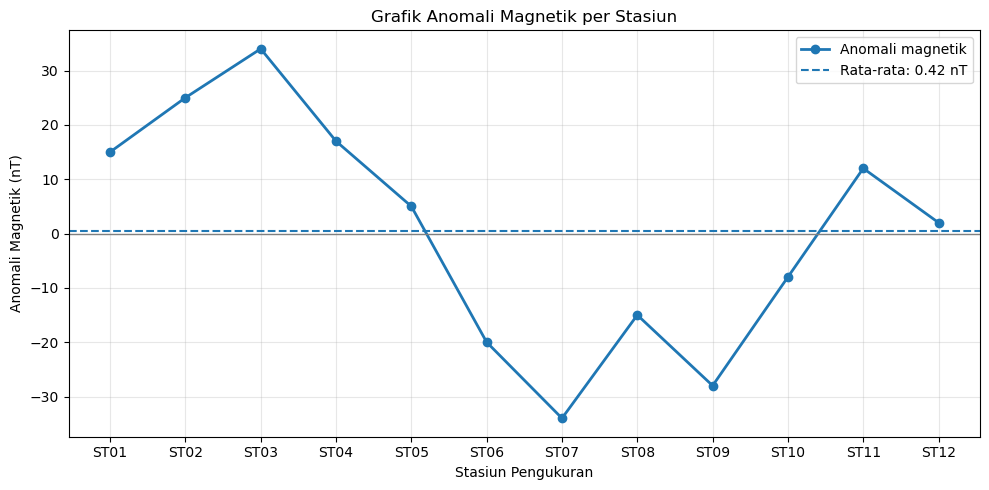

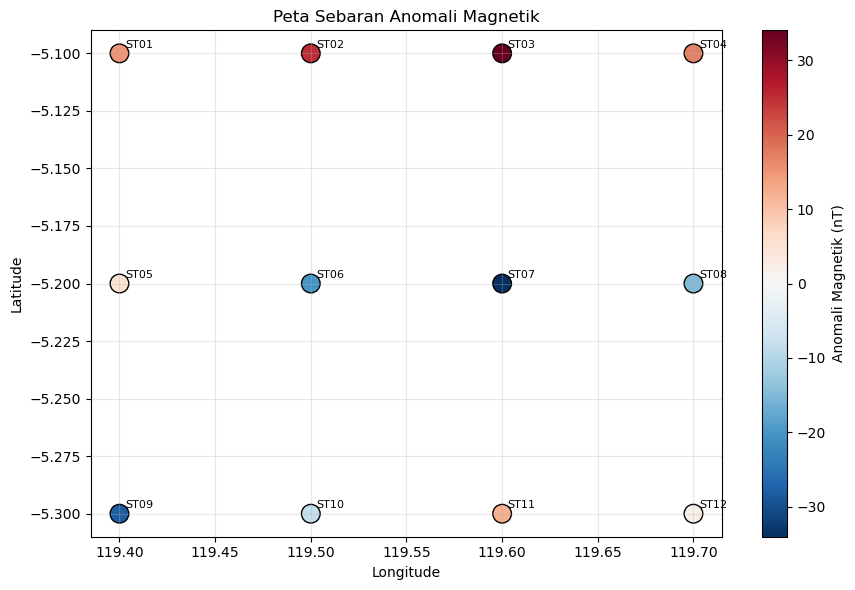


=== INTERPRETASI ANOMALI MAGNETIK ===
Anomali maksimum sebesar 34.00 nT terdapat pada stasiun ST03.
Anomali minimum sebesar -34.00 nT terdapat pada stasiun ST07.

Interpretasi:
Anomali relatif tinggi menunjukkan respons medan magnet yang lebih kuat dibandingkan daerah sekitarnya. Kondisi ini dapat berkaitan dengan material yang memiliki sifat magnetik lebih kuat.
Anomali relatif rendah menunjukkan respons medan magnet yang lebih lemah. Kondisi ini dapat berkaitan dengan material bermagnetisasi lebih rendah atau pengaruh kedalaman dan geometri sumber magnetik.
Interpretasi tersebut masih bersifat awal dan perlu dibandingkan dengan kondisi geologi serta kualitas koreksi.

=== PROSES SELESAI ===
Tabel CSV  : hasil_pengolahan_geomagnetik.csv
Tabel Excel: hasil_pengolahan_geomagnetik.xlsx
Grafik     : grafik_anomali_geomagnetik.png
Peta titik : peta_sebaran_anomali.png


In [21]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================
# PENGOLAHAN DATA GEOMAGNETIK
# Nama   : Isi nama Anda
# NIM    : Isi NIM Anda
# =====================================================

# 1. MEMASUKKAN DATA
# Data simulasi, ganti dengan data pengukuran asli jika tersedia.

data = {
    "Stasiun": [
        "ST01", "ST02", "ST03", "ST04",
        "ST05", "ST06", "ST07", "ST08",
        "ST09", "ST10", "ST11", "ST12"
    ],
    "Latitude": [
        -5.10, -5.10, -5.10, -5.10,
        -5.20, -5.20, -5.20, -5.20,
        -5.30, -5.30, -5.30, -5.30
    ],
    "Longitude": [
        119.40, 119.50, 119.60, 119.70,
        119.40, 119.50, 119.60, 119.70,
        119.40, 119.50, 119.60, 119.70
    ],
    "Magnet_Terukur_nT": [
        45020, 45035, 45048, 45030,
        45010, 44985, 44970, 44995,
        44980, 45005, 45025, 45015
    ],
    "Variasi_Harian_nT": [
        5, 8, 10, 7, 4, 2, -1, 3, 6, 9, 7, 5
    ],
    "Medan_Referensi_nT": [
        45000, 45002, 45004, 45006,
        45001, 45003, 45005, 45007,
        45002, 45004, 45006, 45008
    ]
}

df = pd.DataFrame(data)

# 2. MEMERIKSA DATA
kolom_numerik = [
    "Latitude",
    "Longitude",
    "Magnet_Terukur_nT",
    "Variasi_Harian_nT",
    "Medan_Referensi_nT"
]

if df[kolom_numerik].isnull().any().any():
    raise ValueError("Data mengandung nilai kosong.")

if not np.isfinite(df[kolom_numerik].to_numpy()).all():
    raise ValueError("Terdapat nilai numerik yang tidak valid.")

# 3. KOREKSI VARIASI HARIAN
# Variasi harian dikurangkan dari medan magnet terukur.
df["Magnet_Terkoreksi_nT"] = (
    df["Magnet_Terukur_nT"]
    - df["Variasi_Harian_nT"]
)

# 4. MENGHITUNG ANOMALI MAGNETIK
df["Anomali_Magnetik_nT"] = (
    df["Magnet_Terkoreksi_nT"]
    - df["Medan_Referensi_nT"]
)

# 5. MENGHITUNG STATISTIK ANOMALI
anomali = df["Anomali_Magnetik_nT"]

rata_rata = anomali.mean()
minimum = anomali.min()
maksimum = anomali.max()
simpangan_baku = anomali.std()

stasiun_min = df.loc[
    anomali.idxmin(), "Stasiun"
]

stasiun_maks = df.loc[
    anomali.idxmax(), "Stasiun"
]

# 6. KLASIFIKASI ANOMALI
batas = 0.5 * simpangan_baku

def klasifikasi(nilai):
    if nilai > rata_rata + batas:
        return "Relatif tinggi"
    elif nilai < rata_rata - batas:
        return "Relatif rendah"
    else:
        return "Menengah"

df["Kategori_Anomali"] = anomali.apply(klasifikasi)

# 7. MENAMPILKAN TABEL HASIL
print("\n=== TABEL PENGOLAHAN DATA GEOMAGNETIK ===")
print(df.round(2).to_string(index=False))

print("\n=== STATISTIK ANOMALI MAGNETIK ===")
print(f"Rata-rata anomali : {rata_rata:.2f} nT")
print(f"Anomali minimum   : {minimum:.2f} nT")
print(f"Stasiun minimum   : {stasiun_min}")
print(f"Anomali maksimum  : {maksimum:.2f} nT")
print(f"Stasiun maksimum  : {stasiun_maks}")
print(f"Simpangan baku    : {simpangan_baku:.2f} nT")

# 8. GRAFIK ANOMALI MAGNETIK
plt.figure(figsize=(10, 5))

plt.plot(
    df["Stasiun"],
    df["Anomali_Magnetik_nT"],
    marker="o",
    linewidth=2,
    label="Anomali magnetik"
)

plt.axhline(
    rata_rata,
    linestyle="--",
    label=f"Rata-rata: {rata_rata:.2f} nT"
)

plt.axhline(0, color="gray", linewidth=1)

plt.title("Grafik Anomali Magnetik per Stasiun")
plt.xlabel("Stasiun Pengukuran")
plt.ylabel("Anomali Magnetik (nT)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("grafik_anomali_geomagnetik.png", dpi=300)
plt.show()

# 9. PETA SEBARAN ANOMALI
# Menampilkan sebaran titik, bukan kontur interpolasi.
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df["Anomali_Magnetik_nT"],
    cmap="RdBu_r",
    s=180,
    edgecolors="black"
)

for i, row in df.iterrows():
    plt.annotate(
        row["Stasiun"],
        (row["Longitude"], row["Latitude"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

plt.colorbar(
    scatter,
    label="Anomali Magnetik (nT)"
)

plt.title("Peta Sebaran Anomali Magnetik")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("peta_sebaran_anomali.png", dpi=300)
plt.show()

# 10. INTERPRETASI HASIL
print("\n=== INTERPRETASI ANOMALI MAGNETIK ===")

print(
    f"Anomali maksimum sebesar {maksimum:.2f} nT "
    f"terdapat pada stasiun {stasiun_maks}."
)

print(
    f"Anomali minimum sebesar {minimum:.2f} nT "
    f"terdapat pada stasiun {stasiun_min}."
)

print("\nInterpretasi:")
print(
    "Anomali relatif tinggi menunjukkan respons medan magnet "
    "yang lebih kuat dibandingkan daerah sekitarnya. Kondisi ini "
    "dapat berkaitan dengan material yang memiliki sifat magnetik "
    "lebih kuat."
)

print(
    "Anomali relatif rendah menunjukkan respons medan magnet "
    "yang lebih lemah. Kondisi ini dapat berkaitan dengan material "
    "bermagnetisasi lebih rendah atau pengaruh kedalaman dan "
    "geometri sumber magnetik."
)

print(
    "Interpretasi tersebut masih bersifat awal dan perlu "
    "dibandingkan dengan kondisi geologi serta kualitas koreksi."
)

# 11. MENYIMPAN DATA HASIL PENGOLAHAN
df.to_csv(
    "hasil_pengolahan_geomagnetik.csv",
    index=False
)

df.to_excel(
    "hasil_pengolahan_geomagnetik.xlsx",
    index=False
)

print("\n=== PROSES SELESAI ===")
print("Tabel CSV  : hasil_pengolahan_geomagnetik.csv")
print("Tabel Excel: hasil_pengolahan_geomagnetik.xlsx")
print("Grafik     : grafik_anomali_geomagnetik.png")
print("Peta titik : peta_sebaran_anomali.png")

3. **Context:** Analisis dilakukan menggunakan data medan magnet dari beberapa titik pengukuran di suatu wilayah. Variasi medan magnet dapat memberikan informasi mengenai perubahan sifat kemagnetan material bawah permukaan dan kemungkinan keberadaan struktur geologi tertentu.

   **Output:** Menghasilkan gambaran distribusi sifat magnetik bawah permukaan berdasarkan variasi nilai anomali magnetik.

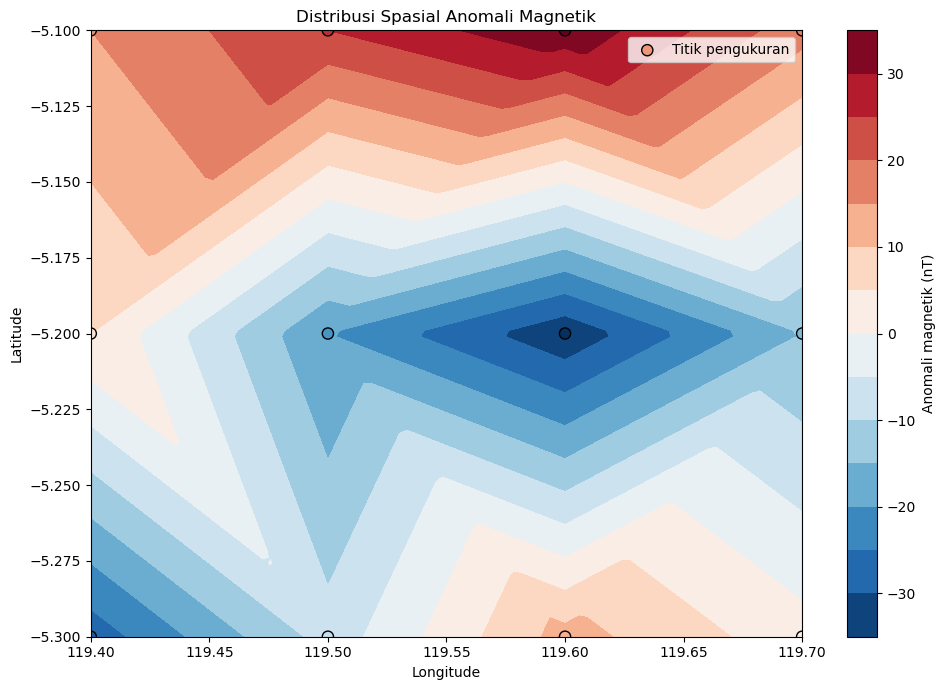


=== INTERPRETASI DISTRIBUSI MAGNETIK ===

Titik dengan anomali relatif tinggi:
Stasiun  Anomali_Magnetik_nT
   ST01                   15
   ST02                   25
   ST03                   34
   ST04                   17
   ST11                   12

Titik dengan anomali relatif rendah:
Stasiun  Anomali_Magnetik_nT
   ST06                  -20
   ST07                  -34
   ST08                  -15
   ST09                  -28

Interpretasi geofisika:
Zona anomali relatif tinggi dapat mengindikasikan material dengan respons magnetik lebih kuat, misalnya batuan yang mengandung mineral magnetik.
Zona anomali relatif rendah dapat mengindikasikan material dengan respons magnetik lebih lemah, batuan yang mengalami alterasi tertentu, atau pengaruh kedalaman sumber.
Perubahan pola anomali yang tajam dapat menjadi petunjuk awal adanya batas litologi atau struktur geologi. Namun, peta anomali saja belum cukup untuk memastikan jenis batuan, sesar, atau kedalaman sumber.

Catatan: peta ini 

In [22]:

from scipy.interpolate import griddata

# Mengambil koordinat pengukuran
x = df["Longitude"].to_numpy()
y = df["Latitude"].to_numpy()
z = df["Anomali_Magnetik_nT"].to_numpy()

# Membuat grid untuk visualisasi
xi = np.linspace(x.min(), x.max(), 100)
yi = np.linspace(y.min(), y.max(), 100)
X, Y = np.meshgrid(xi, yi)

# Interpolasi linear
Z = griddata(
    (x, y),
    z,
    (X, Y),
    method="linear"
)

# Mengisi bagian di luar cakupan interpolasi linear
# menggunakan nearest agar peta tetap dapat ditampilkan.
Z_nearest = griddata(
    (x, y),
    z,
    (X, Y),
    method="nearest"
)

Z = np.where(np.isnan(Z), Z_nearest, Z)

# Membuat peta distribusi anomali
plt.figure(figsize=(10, 7))

contour = plt.contourf(
    X,
    Y,
    Z,
    levels=15,
    cmap="RdBu_r"
)

plt.scatter(
    x,
    y,
    c=z,
    cmap="RdBu_r",
    edgecolors="black",
    s=65,
    label="Titik pengukuran"
)

plt.colorbar(
    contour,
    label="Anomali magnetik (nT)"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Distribusi Spasial Anomali Magnetik")
plt.legend()
plt.tight_layout()
plt.savefig(
    "distribusi_spasial_anomali.png",
    dpi=300
)
plt.show()

# 13. INTERPRETASI POLA ANOMALI
print("\n=== INTERPRETASI DISTRIBUSI MAGNETIK ===")

anomali_tinggi = df[
    df["Kategori_Anomali"] == "Relatif tinggi"
]

anomali_rendah = df[
    df["Kategori_Anomali"] == "Relatif rendah"
]

print("\nTitik dengan anomali relatif tinggi:")
if len(anomali_tinggi) > 0:
    print(
        anomali_tinggi[
            ["Stasiun", "Anomali_Magnetik_nT"]
        ].to_string(index=False)
    )
else:
    print("Tidak ada titik dalam kategori ini.")

print("\nTitik dengan anomali relatif rendah:")
if len(anomali_rendah) > 0:
    print(
        anomali_rendah[
            ["Stasiun", "Anomali_Magnetik_nT"]
        ].to_string(index=False)
    )
else:
    print("Tidak ada titik dalam kategori ini.")

print("\nInterpretasi geofisika:")
print(
    "Zona anomali relatif tinggi dapat mengindikasikan material "
    "dengan respons magnetik lebih kuat, misalnya batuan yang "
    "mengandung mineral magnetik."
)

print(
    "Zona anomali relatif rendah dapat mengindikasikan material "
    "dengan respons magnetik lebih lemah, batuan yang mengalami "
    "alterasi tertentu, atau pengaruh kedalaman sumber."
)

print(
    "Perubahan pola anomali yang tajam dapat menjadi petunjuk "
    "awal adanya batas litologi atau struktur geologi. Namun, "
    "peta anomali saja belum cukup untuk memastikan jenis batuan, "
    "sesar, atau kedalaman sumber."
)

print(
    "\nCatatan: peta ini menggunakan data simulasi dan interpolasi "
    "linear dengan pengisian nearest. Ketelitian pola bergantung "
    "pada jumlah, sebaran, dan kualitas titik pengukuran."
)

4. **Input:** Masukkan data berupa nomor titik, koordinat latitude dan longitude, elevasi, nilai medan magnet total, waktu pengukuran, serta data pendukung lainnya apabila tersedia.

   **Output:** Menghasilkan data terstruktur berupa hasil koreksi dan nilai anomali magnetik pada setiap titik pengukuran.


=== HASIL PENGOLAHAN DATA GEOMAGNETIK ===
 Nomor_Titik  Latitude  Longitude  Elevasi_m Waktu_Pengukuran  Medan_Magnet_Total_nT  Variasi_Harian_nT  Koreksi_Variasi_Harian_nT  Medan_Magnet_Terkoreksi_nT  Medan_Referensi_nT  Anomali_Magnetik_nT Kategori_Anomali
           1      -5.1      119.4         12            08:00                  45020                  5                         -5                       45015               45000                   15   Relatif tinggi
           2      -5.1      119.5         15            08:10                  45035                  8                         -8                       45027               45002                   25   Relatif tinggi
           3      -5.1      119.6         18            08:20                  45048                 10                        -10                       45038               45004                   34   Relatif tinggi
           4      -5.1      119.7         20            08:30                  45030     

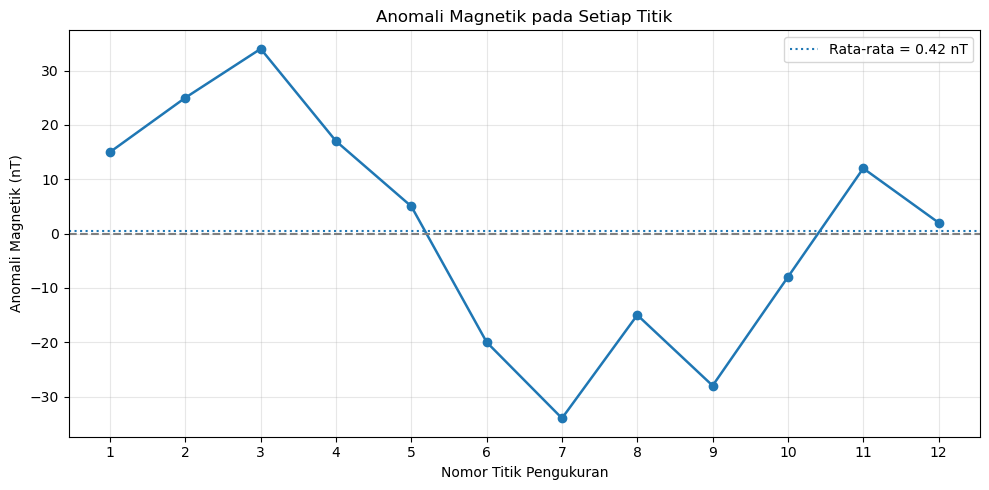

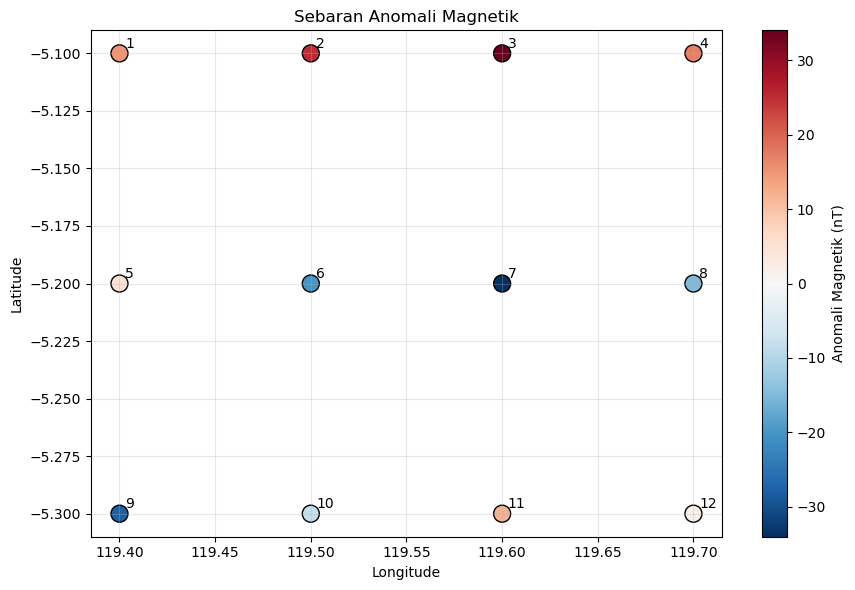


Pengolahan selesai.
File tersimpan:
- hasil_geomagnetik.csv
- hasil_geomagnetik.xlsx
- anomali_per_titik.png
- peta_anomali_magnetik.png


In [23]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# PENGOLAHAN DATA GEOMAGNETIK
# Input: koordinat, elevasi, medan magnet, waktu, dan referensi
# ==========================================================

# 1. INPUT DATA
# Data simulasi untuk contoh pengolahan.
data = {
    "Nomor_Titik": list(range(1, 13)),
    "Latitude": [
        -5.10, -5.10, -5.10, -5.10,
        -5.20, -5.20, -5.20, -5.20,
        -5.30, -5.30, -5.30, -5.30
    ],
    "Longitude": [
        119.40, 119.50, 119.60, 119.70,
        119.40, 119.50, 119.60, 119.70,
        119.40, 119.50, 119.60, 119.70
    ],
    "Elevasi_m": [
        12, 15, 18, 20,
        14, 17, 21, 23,
        16, 19, 22, 25
    ],
    "Waktu_Pengukuran": [
        "08:00", "08:10", "08:20", "08:30",
        "08:40", "08:50", "09:00", "09:10",
        "09:20", "09:30", "09:40", "09:50"
    ],
    "Medan_Magnet_Total_nT": [
        45020, 45035, 45048, 45030,
        45010, 44985, 44970, 44995,
        44980, 45005, 45025, 45015
    ],
    "Variasi_Harian_nT": [
        5, 8, 10, 7, 4, 2, -1, 3, 6, 9, 7, 5
    ],
    "Medan_Referensi_nT": [
        45000, 45002, 45004, 45006,
        45001, 45003, 45005, 45007,
        45002, 45004, 45006, 45008
    ]
}

df = pd.DataFrame(data)

# 2. VALIDASI INPUT
kolom_wajib = [
    "Nomor_Titik",
    "Latitude",
    "Longitude",
    "Elevasi_m",
    "Waktu_Pengukuran",
    "Medan_Magnet_Total_nT",
    "Variasi_Harian_nT",
    "Medan_Referensi_nT"
]

if df[kolom_wajib].isnull().any().any():
    raise ValueError("Terdapat data kosong pada tabel input.")

kolom_numerik = [
    "Latitude",
    "Longitude",
    "Elevasi_m",
    "Medan_Magnet_Total_nT",
    "Variasi_Harian_nT",
    "Medan_Referensi_nT"
]

if not np.isfinite(df[kolom_numerik].to_numpy(dtype=float)).all():
    raise ValueError("Terdapat nilai numerik yang tidak valid.")

if not df["Latitude"].between(-90, 90).all():
    raise ValueError("Latitude harus berada antara -90 dan 90.")

if not df["Longitude"].between(-180, 180).all():
    raise ValueError("Longitude harus berada antara -180 dan 180.")

# 3. KOREKSI VARIASI HARIAN
# Asumsi: variasi harian adalah nilai bertanda
# yang harus dikurangkan dari medan magnet total.
df["Koreksi_Variasi_Harian_nT"] = (
    -df["Variasi_Harian_nT"]
)

df["Medan_Magnet_Terkoreksi_nT"] = (
    df["Medan_Magnet_Total_nT"]
    + df["Koreksi_Variasi_Harian_nT"]
)

# 4. MENGHITUNG ANOMALI MAGNETIK
df["Anomali_Magnetik_nT"] = (
    df["Medan_Magnet_Terkoreksi_nT"]
    - df["Medan_Referensi_nT"]
)

# 5. MENAMBAHKAN KATEGORI ANOMALI
rata_rata = df["Anomali_Magnetik_nT"].mean()
simpangan_baku = df["Anomali_Magnetik_nT"].std()
batas = 0.5 * simpangan_baku

def klasifikasi_anomali(nilai):
    if nilai > rata_rata + batas:
        return "Relatif tinggi"
    elif nilai < rata_rata - batas:
        return "Relatif rendah"
    else:
        return "Menengah"

df["Kategori_Anomali"] = (
    df["Anomali_Magnetik_nT"].apply(klasifikasi_anomali)
)

# 6. MENAMPILKAN TABEL HASIL
kolom_hasil = [
    "Nomor_Titik",
    "Latitude",
    "Longitude",
    "Elevasi_m",
    "Waktu_Pengukuran",
    "Medan_Magnet_Total_nT",
    "Variasi_Harian_nT",
    "Koreksi_Variasi_Harian_nT",
    "Medan_Magnet_Terkoreksi_nT",
    "Medan_Referensi_nT",
    "Anomali_Magnetik_nT",
    "Kategori_Anomali"
]

print("\n=== HASIL PENGOLAHAN DATA GEOMAGNETIK ===")
print(df[kolom_hasil].round(3).to_string(index=False))

# 7. RINGKASAN STATISTIK
print("\n=== RINGKASAN ANOMALI MAGNETIK ===")
print(f"Jumlah titik       : {len(df)}")
print(f"Rata-rata anomali  : {rata_rata:.2f} nT")
print(f"Simpangan baku     : {simpangan_baku:.2f} nT")
print(
    f"Anomali minimum    : "
    f"{df['Anomali_Magnetik_nT'].min():.2f} nT"
)
print(
    f"Anomali maksimum   : "
    f"{df['Anomali_Magnetik_nT'].max():.2f} nT"
)

# 8. GRAFIK ANOMALI PER TITIK
plt.figure(figsize=(10, 5))

plt.plot(
    df["Nomor_Titik"],
    df["Anomali_Magnetik_nT"],
    marker="o",
    linewidth=1.8
)

plt.axhline(0, linestyle="--", color="gray")
plt.axhline(
    rata_rata,
    linestyle=":",
    label=f"Rata-rata = {rata_rata:.2f} nT"
)

plt.xlabel("Nomor Titik Pengukuran")
plt.ylabel("Anomali Magnetik (nT)")
plt.title("Anomali Magnetik pada Setiap Titik")
plt.xticks(df["Nomor_Titik"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("anomali_per_titik.png", dpi=300)
plt.show()

# 9. PETA SEBARAN TITIK
plt.figure(figsize=(9, 6))

peta = plt.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df["Anomali_Magnetik_nT"],
    cmap="RdBu_r",
    s=150,
    edgecolors="black"
)

for _, baris in df.iterrows():
    plt.annotate(
        str(baris["Nomor_Titik"]),
        (baris["Longitude"], baris["Latitude"]),
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.colorbar(peta, label="Anomali Magnetik (nT)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Sebaran Anomali Magnetik")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("peta_anomali_magnetik.png", dpi=300)
plt.show()

# 10. MENYIMPAN HASIL PENGOLAHAN
df[kolom_hasil].to_csv(
    "hasil_geomagnetik.csv",
    index=False
)

df[kolom_hasil].to_excel(
    "hasil_geomagnetik.xlsx",
    index=False
)

print("\nPengolahan selesai.")
print("File tersimpan:")
print("- hasil_geomagnetik.csv")
print("- hasil_geomagnetik.xlsx")
print("- anomali_per_titik.png")
print("- peta_anomali_magnetik.png")

5. **Constraints:** Gunakan konsep dasar metode geomagnetik dan persamaan koreksi yang sesuai. Pastikan satuan data konsisten. Jangan menghilangkan atau mengubah data asli tanpa alasan yang jelas. Interpretasi anomali magnetik harus mempertimbangkan kondisi geologi dan sifat magnetik material.

   **Output:** Menghasilkan analisis geomagnetik yang sistematis, konsisten dengan data asli, serta interpretasi berdasarkan prinsip metode geomagnetik.

Pemeriksaan data asli: berhasil.
Semua kolom input tetap dipertahankan.

=== TABEL HASIL PENGOLAHAN ===
 Nomor_Titik  Latitude  Longitude  Elevasi_m Waktu_Pengukuran  Medan_Magnet_Total_nT  Variasi_Harian_nT  Koreksi_Harian_nT  Medan_Terkoreksi_nT  Medan_Referensi_nT  Anomali_Magnetik_nT Kategori_Anomali
           1      -5.1      119.4         12            08:00                  45020                  5                 -5                45015               45000                   15   Relatif tinggi
           2      -5.1      119.5         15            08:10                  45035                  8                 -8                45027               45002                   25   Relatif tinggi
           3      -5.1      119.6         18            08:20                  45048                 10                -10                45038               45004                   34   Relatif tinggi
           4      -5.1      119.7         20            08:30                  45030    

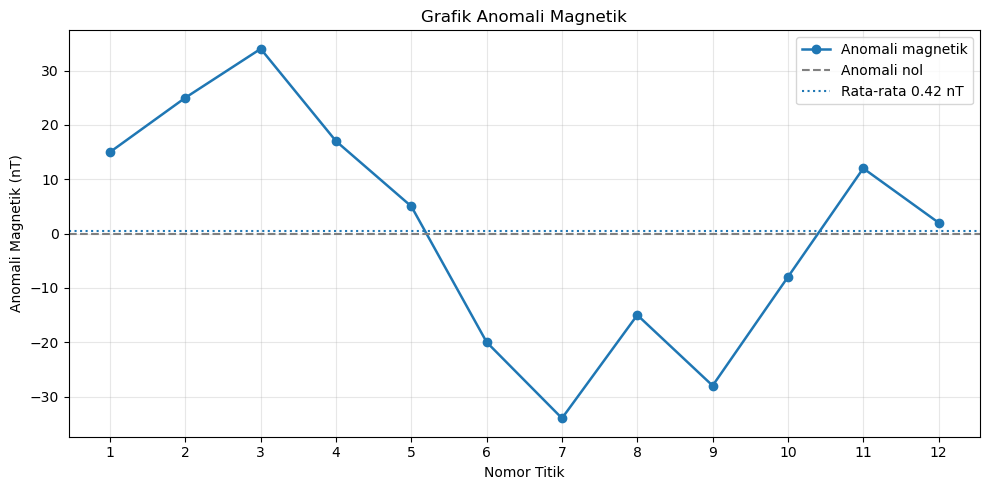

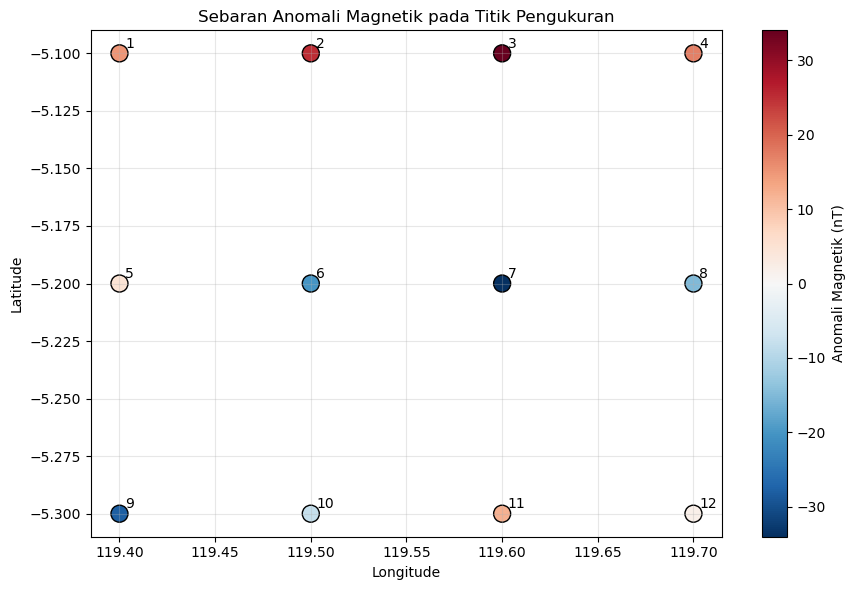


=== INTERPRETASI GEOFISIKA ===
Anomali relatif tinggi menunjukkan respons medan magnet yang lebih besar dibandingkan nilai pembanding. Hal ini dapat berkaitan dengan material yang memiliki kemagnetan lebih kuat atau geometri sumber yang memengaruhi medan.
Anomali relatif rendah menunjukkan respons medan magnet yang lebih kecil dibandingkan nilai pembanding. Hal ini dapat berkaitan dengan material bermagnetisasi lebih lemah, alterasi batuan tertentu, atau pengaruh kedalaman sumber.
Pola perubahan anomali dapat menjadi petunjuk awal perubahan litologi atau struktur geologi. Namun, interpretasi harus mempertimbangkan kondisi geologi, arah magnetisasi, kedalaman, topografi, kualitas koreksi, dan distribusi titik pengukuran.

=== PENGOLAHAN SELESAI ===
Data asli dipertahankan.
Hasil disimpan ke:
- hasil_geomagnetik.csv
- hasil_geomagnetik.xlsx
- grafik_anomali_geomagnetik.png
- peta_anomali_geomagnetik.png


In [24]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# PENGOLAHAN DATA GEOMAGNETIK
# Prinsip: data asli dipertahankan, koreksi transparan,
# satuan konsisten, dan interpretasi bersifat geofisika.
# ==========================================================

# 1. DATA INPUT
# Data simulasi. Ganti dengan data lapangan untuk analisis nyata.
data = {
    "Nomor_Titik": list(range(1, 13)),
    "Latitude": [
        -5.10, -5.10, -5.10, -5.10,
        -5.20, -5.20, -5.20, -5.20,
        -5.30, -5.30, -5.30, -5.30
    ],
    "Longitude": [
        119.40, 119.50, 119.60, 119.70,
        119.40, 119.50, 119.60, 119.70,
        119.40, 119.50, 119.60, 119.70
    ],
    "Elevasi_m": [
        12, 15, 18, 20, 14, 17,
        21, 23, 16, 19, 22, 25
    ],
    "Waktu_Pengukuran": [
        "08:00", "08:10", "08:20", "08:30",
        "08:40", "08:50", "09:00", "09:10",
        "09:20", "09:30", "09:40", "09:50"
    ],
    "Medan_Magnet_Total_nT": [
        45020, 45035, 45048, 45030,
        45010, 44985, 44970, 44995,
        44980, 45005, 45025, 45015
    ],
    "Variasi_Harian_nT": [
        5, 8, 10, 7, 4, 2,
        -1, 3, 6, 9, 7, 5
    ],
    "Medan_Referensi_nT": [
        45000, 45002, 45004, 45006,
        45001, 45003, 45005, 45007,
        45002, 45004, 45006, 45008
    ]
}

data_asli = pd.DataFrame(data)

# Salinan kerja untuk pengolahan.
# Data asli tidak diubah atau ditimpa.
df = data_asli.copy(deep=True)

# 2. VALIDASI DATA
kolom_numerik = [
    "Latitude",
    "Longitude",
    "Elevasi_m",
    "Medan_Magnet_Total_nT",
    "Variasi_Harian_nT",
    "Medan_Referensi_nT"
]

if df.isnull().any().any():
    raise ValueError("Data input mengandung nilai kosong.")

if not np.isfinite(
    df[kolom_numerik].to_numpy(dtype=float)
).all():
    raise ValueError("Data numerik mengandung nilai tidak valid.")

if not df["Latitude"].between(-90, 90).all():
    raise ValueError("Nilai latitude tidak valid.")

if not df["Longitude"].between(-180, 180).all():
    raise ValueError("Nilai longitude tidak valid.")

if df["Nomor_Titik"].duplicated().any():
    raise ValueError("Nomor titik pengukuran harus unik.")

# 3. KOREKSI VARIASI HARIAN
# Asumsi:
# Variasi_Harian_nT adalah perubahan medan bertanda
# terhadap nilai acuan base station.
#
# Rumus:
# T_koreksi = T_ukur - variasi_harian
#
# Pastikan definisi data variasi harian sesuai asumsi ini.

df["Koreksi_Harian_nT"] = -df["Variasi_Harian_nT"]

df["Medan_Terkoreksi_nT"] = (
    df["Medan_Magnet_Total_nT"]
    + df["Koreksi_Harian_nT"]
)

# 4. MENGHITUNG ANOMALI MAGNETIK
# Rumus sederhana:
# Anomali = medan terkoreksi - medan referensi
#
# Medan referensi harus menggunakan model yang sesuai
# dengan lokasi dan tanggal pengukuran pada data nyata.

df["Anomali_Magnetik_nT"] = (
    df["Medan_Terkoreksi_nT"]
    - df["Medan_Referensi_nT"]
)

# 5. KLASIFIKASI RELATIF ANOMALI
# Batas ini hanya alat bantu visualisasi, bukan
# batas geologi universal.

rata_rata = df["Anomali_Magnetik_nT"].mean()
simpangan_baku = df["Anomali_Magnetik_nT"].std()
batas = 0.5 * simpangan_baku

def klasifikasi_anomali(nilai):
    if nilai > rata_rata + batas:
        return "Relatif tinggi"
    elif nilai < rata_rata - batas:
        return "Relatif rendah"
    else:
        return "Menengah"

df["Kategori_Anomali"] = (
    df["Anomali_Magnetik_nT"].apply(klasifikasi_anomali)
)

# 6. MEMERIKSA BAHWA DATA ASLI TIDAK BERUBAH
pd.testing.assert_frame_equal(
    df[data_asli.columns],
    data_asli
)

print("Pemeriksaan data asli: berhasil.")
print("Semua kolom input tetap dipertahankan.")

# 7. MENAMPILKAN TABEL PENGOLAHAN
kolom_hasil = [
    "Nomor_Titik",
    "Latitude",
    "Longitude",
    "Elevasi_m",
    "Waktu_Pengukuran",
    "Medan_Magnet_Total_nT",
    "Variasi_Harian_nT",
    "Koreksi_Harian_nT",
    "Medan_Terkoreksi_nT",
    "Medan_Referensi_nT",
    "Anomali_Magnetik_nT",
    "Kategori_Anomali"
]

print("\n=== TABEL HASIL PENGOLAHAN ===")
print(df[kolom_hasil].round(3).to_string(index=False))

# 8. STATISTIK ANOMALI
indeks_min = df["Anomali_Magnetik_nT"].idxmin()
indeks_maks = df["Anomali_Magnetik_nT"].idxmax()

print("\n=== STATISTIK ANOMALI ===")
print(f"Rata-rata        : {rata_rata:.2f} nT")
print(f"Simpangan baku   : {simpangan_baku:.2f} nT")
print(
    f"Anomali minimum  : "
    f"{df.loc[indeks_min, 'Anomali_Magnetik_nT']:.2f} nT"
)
print(
    f"Lokasi minimum   : "
    f"Titik {df.loc[indeks_min, 'Nomor_Titik']}"
)
print(
    f"Anomali maksimum : "
    f"{df.loc[indeks_maks, 'Anomali_Magnetik_nT']:.2f} nT"
)
print(
    f"Lokasi maksimum  : "
    f"Titik {df.loc[indeks_maks, 'Nomor_Titik']}"
)

# 9. GRAFIK ANOMALI
plt.figure(figsize=(10, 5))

plt.plot(
    df["Nomor_Titik"],
    df["Anomali_Magnetik_nT"],
    marker="o",
    linewidth=1.8,
    label="Anomali magnetik"
)

plt.axhline(
    0,
    color="gray",
    linestyle="--",
    label="Anomali nol"
)

plt.axhline(
    rata_rata,
    linestyle=":",
    label=f"Rata-rata {rata_rata:.2f} nT"
)

plt.xlabel("Nomor Titik")
plt.ylabel("Anomali Magnetik (nT)")
plt.title("Grafik Anomali Magnetik")
plt.xticks(df["Nomor_Titik"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("grafik_anomali_geomagnetik.png", dpi=300)
plt.show()

# 10. PETA SEBARAN TITIK ANOMALI
plt.figure(figsize=(9, 6))

peta = plt.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df["Anomali_Magnetik_nT"],
    cmap="RdBu_r",
    s=150,
    edgecolors="black"
)

for _, baris in df.iterrows():
    plt.annotate(
        str(baris["Nomor_Titik"]),
        (baris["Longitude"], baris["Latitude"]),
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.colorbar(peta, label="Anomali Magnetik (nT)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Sebaran Anomali Magnetik pada Titik Pengukuran")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("peta_anomali_geomagnetik.png", dpi=300)
plt.show()

# 11. INTERPRETASI BERDASARKAN PRINSIP GEOMAGNETIK
print("\n=== INTERPRETASI GEOFISIKA ===")

print(
    "Anomali relatif tinggi menunjukkan respons medan magnet "
    "yang lebih besar dibandingkan nilai pembanding. Hal ini "
    "dapat berkaitan dengan material yang memiliki kemagnetan "
    "lebih kuat atau geometri sumber yang memengaruhi medan."
)

print(
    "Anomali relatif rendah menunjukkan respons medan magnet "
    "yang lebih kecil dibandingkan nilai pembanding. Hal ini "
    "dapat berkaitan dengan material bermagnetisasi lebih lemah, "
    "alterasi batuan tertentu, atau pengaruh kedalaman sumber."
)

print(
    "Pola perubahan anomali dapat menjadi petunjuk awal perubahan "
    "litologi atau struktur geologi. Namun, interpretasi harus "
    "mempertimbangkan kondisi geologi, arah magnetisasi, kedalaman, "
    "topografi, kualitas koreksi, dan distribusi titik pengukuran."
)

# 12. MENYIMPAN HASIL
df[kolom_hasil].to_csv(
    "hasil_geomagnetik.csv",
    index=False
)

df[kolom_hasil].to_excel(
    "hasil_geomagnetik.xlsx",
    index=False
)

print("\n=== PENGOLAHAN SELESAI ===")
print("Data asli dipertahankan.")
print("Hasil disimpan ke:")
print("- hasil_geomagnetik.csv")
print("- hasil_geomagnetik.xlsx")
print("- grafik_anomali_geomagnetik.png")
print("- peta_anomali_geomagnetik.png")

**PROMPT 5**

1. **Role:** Anda berperan sebagai seorang ahli geofisika yang memiliki keahlian dalam metode seismik refraksi, khususnya dalam pengolahan data waktu tempuh gelombang seismik. Anda mampu menganalisis hubungan jarak terhadap waktu tiba, menentukan kecepatan gelombang pada setiap lapisan, memperkirakan kedalaman batas lapisan, serta menginterpretasikan struktur bawah permukaan.

   **Output:** Menghasilkan model bawah permukaan berdasarkan kecepatan gelombang seismik dan kedalaman lapisan.


=== HASIL ANALISIS KECEPATAN ===
  Lapisan  Kecepatan_m_per_s  Waktu_Intersep_s  R2
Lapisan 1           454.5455             0.001 1.0
Lapisan 2           714.2857             0.013 1.0
Lapisan 3          1000.0000             0.023 1.0

=== KEDALAMAN BATAS LAPISAN ===
Kedalaman batas lapisan 1-2: 3.83 m
Kedalaman batas lapisan 2-3: 4.08 m


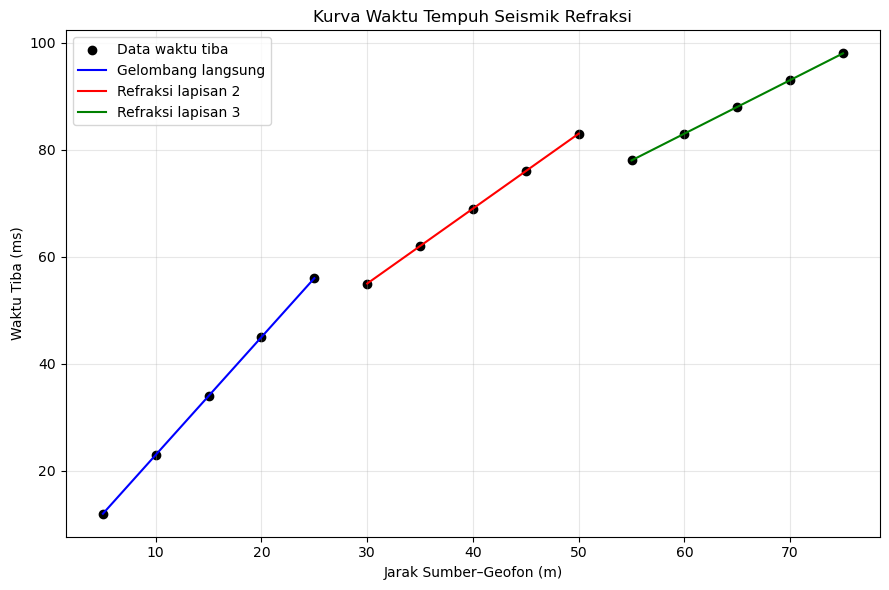

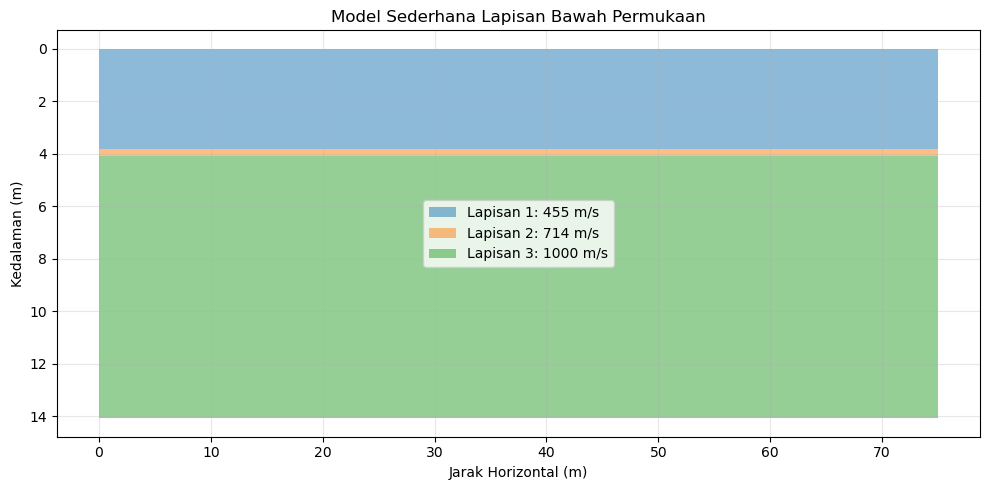


File hasil disimpan:
- data_seismik_refraksi.csv
- hasil_kecepatan_lapisan.csv
- travel_time_curve.png
- model_bawah_permukaan.png


In [25]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# ANALISIS SEISMIK REFRAKSI
# Travel-Time Curve, Kecepatan, dan Kedalaman Lapisan
# ==========================================================

# 1. DATA PENGUKURAN
# Data simulasi untuk contoh. Ganti dengan data waktu tempuh
# hasil pengukuran lapangan jika tersedia.

data = {
    "Jarak_m": [
        5, 10, 15, 20, 25,
        30, 35, 40, 45, 50,
        55, 60, 65, 70, 75
    ],
    "Waktu_tiba_ms": [
        12, 23, 34, 45, 56,
        55, 62, 69, 76, 83,
        78, 83, 88, 93, 98
    ]
}

df = pd.DataFrame(data)

# Konversi waktu dari milidetik menjadi detik
df["Waktu_tiba_s"] = df["Waktu_tiba_ms"] / 1000

# 2. PEMISAHAN DATA GELOMBANG
# Contoh ini mengasumsikan:
# Jarak <= 25 m  : gelombang langsung
# 30-50 m        : gelombang refraksi lapisan 2
# 55-75 m        : gelombang refraksi lapisan 3
#
# Untuk data nyata, tentukan segmen berdasarkan travel-time curve.

gelombang_1 = df[df["Jarak_m"] <= 25]
gelombang_2 = df[
    (df["Jarak_m"] >= 30) & (df["Jarak_m"] <= 50)
]
gelombang_3 = df[df["Jarak_m"] >= 55]

# 3. REGRESI LINEAR WAKTU TERHADAP JARAK
def regresi_waktu(segmen):
    x = segmen["Jarak_m"].to_numpy(dtype=float)
    t = segmen["Waktu_tiba_s"].to_numpy(dtype=float)

    if len(x) < 2:
        raise ValueError("Setiap segmen memerlukan minimal dua titik.")

    slope, intercept = np.polyfit(x, t, 1)

    # Kecepatan = kebalikan gradien waktu terhadap jarak
    kecepatan = 1 / slope

    # Koefisien determinasi
    prediksi = slope * x + intercept
    ss_res = np.sum((t - prediksi) ** 2)
    ss_tot = np.sum((t - np.mean(t)) ** 2)

    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    return kecepatan, intercept, slope, r2

v1, t01, m1, r21 = regresi_waktu(gelombang_1)
v2, ti2, m2, r22 = regresi_waktu(gelombang_2)
v3, ti3, m3, r23 = regresi_waktu(gelombang_3)

# 4. MENGHITUNG KEDALAMAN BATAS LAPISAN
# Untuk model tiga lapisan horizontal:
# z1 = (ti2 * v1) / (2 * cos(i12))
# z2 dihitung dari waktu intersep lapisan 3.
#
# Rumus menggunakan waktu intersep dalam detik dan
# kecepatan dalam m/s.

def sudut_kritis(v_bawah, v_atas):
    if v_bawah <= v_atas:
        raise ValueError(
            "Kecepatan lapisan bawah harus lebih besar "
            "daripada kecepatan lapisan atas."
        )
    return np.arcsin(v_atas / v_bawah)

def kedalaman_dua_lapisan(v1, v2, ti):
    i = sudut_kritis(v2, v1)
    return (ti * v1) / (2 * np.cos(i))

# Kedalaman batas lapisan 1 dan 2
z1 = kedalaman_dua_lapisan(v1, v2, ti2)

# Perhitungan batas lapisan 2 dan 3 dengan asumsi
# model tiga lapisan horizontal dan refraksi berurutan.
i12 = sudut_kritis(v2, v1)
i13 = sudut_kritis(v3, v1)
i23 = sudut_kritis(v3, v2)

# Waktu intersep gelombang refraksi lapisan 3:
# ti3 = 2*z1*cos(i13)/v1 + 2*z2*cos(i23)/v2
z2 = (
    (ti3 - 2 * z1 * np.cos(i13) / v1)
    * v2
    / (2 * np.cos(i23))
)

# 5. MENAMPILKAN HASIL KECEPATAN
hasil_kecepatan = pd.DataFrame({
    "Lapisan": ["Lapisan 1", "Lapisan 2", "Lapisan 3"],
    "Kecepatan_m_per_s": [v1, v2, v3],
    "Waktu_Intersep_s": [t01, ti2, ti3],
    "R2": [r21, r22, r23]
})

print("\n=== HASIL ANALISIS KECEPATAN ===")
print(hasil_kecepatan.round(4).to_string(index=False))

print("\n=== KEDALAMAN BATAS LAPISAN ===")
print(f"Kedalaman batas lapisan 1-2: {z1:.2f} m")
print(f"Kedalaman batas lapisan 2-3: {z2:.2f} m")

# 6. GRAFIK TRAVEL-TIME CURVE
plt.figure(figsize=(9, 6))

plt.scatter(
    df["Jarak_m"],
    df["Waktu_tiba_ms"],
    color="black",
    label="Data waktu tiba"
)

for segmen, nama, warna in [
    (gelombang_1, "Gelombang langsung", "blue"),
    (gelombang_2, "Refraksi lapisan 2", "red"),
    (gelombang_3, "Refraksi lapisan 3", "green")
]:
    x = segmen["Jarak_m"].to_numpy()
    t = segmen["Waktu_tiba_ms"].to_numpy()

    slope, intercept = np.polyfit(x, t, 1)
    plt.plot(
        x,
        slope * x + intercept,
        color=warna,
        label=nama
    )

plt.xlabel("Jarak Sumber–Geofon (m)")
plt.ylabel("Waktu Tiba (ms)")
plt.title("Kurva Waktu Tempuh Seismik Refraksi")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("travel_time_curve.png", dpi=300)
plt.show()

# 7. MODEL BAWAH PERMUKAAN
if z1 <= 0 or z2 <= z1:
    print(
        "\nPERINGATAN: Kedalaman tidak konsisten. "
        "Periksa pemilihan segmen, kualitas data, dan asumsi model."
    )
else:
    plt.figure(figsize=(10, 5))

    plt.fill_between(
        [0, 75], 0, z1,
        alpha=0.5,
        label=f"Lapisan 1: {v1:.0f} m/s"
    )

    plt.fill_between(
        [0, 75], z1, z2,
        alpha=0.5,
        label=f"Lapisan 2: {v2:.0f} m/s"
    )

    plt.fill_between(
        [0, 75], z2, z2 + 10,
        alpha=0.5,
        label=f"Lapisan 3: {v3:.0f} m/s"
    )

    plt.gca().invert_yaxis()
    plt.xlabel("Jarak Horizontal (m)")
    plt.ylabel("Kedalaman (m)")
    plt.title("Model Sederhana Lapisan Bawah Permukaan")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("model_bawah_permukaan.png", dpi=300)
    plt.show()

# 8. MENYIMPAN HASIL
df.to_csv("data_seismik_refraksi.csv", index=False)
hasil_kecepatan.to_csv("hasil_kecepatan_lapisan.csv", index=False)

print("\nFile hasil disimpan:")
print("- data_seismik_refraksi.csv")
print("- hasil_kecepatan_lapisan.csv")
print("- travel_time_curve.png")
print("- model_bawah_permukaan.png")

2. **Task:** Lakukan pengolahan data seismik refraksi dengan menganalisis jarak sumber terhadap geofon dan waktu tiba gelombang. Buat grafik travel time terhadap jarak, tentukan kemiringan masing-masing segmen, hitung kecepatan gelombang, dan estimasikan kedalaman lapisan bawah permukaan.

   **Output:** Menghasilkan tabel jarak dan waktu tiba, grafik travel time–distance, nilai kecepatan tiap lapisan, estimasi kedalaman, serta interpretasi model bawah permukaan.


=== TABEL JARAK DAN WAKTU TIBA ===
 Jarak_m  Waktu_Tiba_ms  Waktu_Tiba_s
       5           10.0        0.0100
      10           20.0        0.0200
      15           30.0        0.0300
      20           40.0        0.0400
      25           45.8        0.0458
      30           50.0        0.0500
      35           54.2        0.0542
      40           58.3        0.0583
      45           62.5        0.0625
      50           66.7        0.0667
      55           70.8        0.0708
      60           75.0        0.0750
      65           79.2        0.0792
      70           83.3        0.0833
      75           87.5        0.0875

=== HASIL REGRESI DAN KECEPATAN ===
  Lapisan    Jenis_Gelombang  Gradien_s_per_m  Waktu_Intersep_s  Kecepatan_m_per_s  R_squared
Lapisan 1 Gelombang langsung          0.00200           0.00000          500.00000        1.0
Lapisan 2 Gelombang refraksi          0.00083           0.02499         1199.82548        1.0

=== HASIL KEDALAMAN LAPISAN ===
Kece

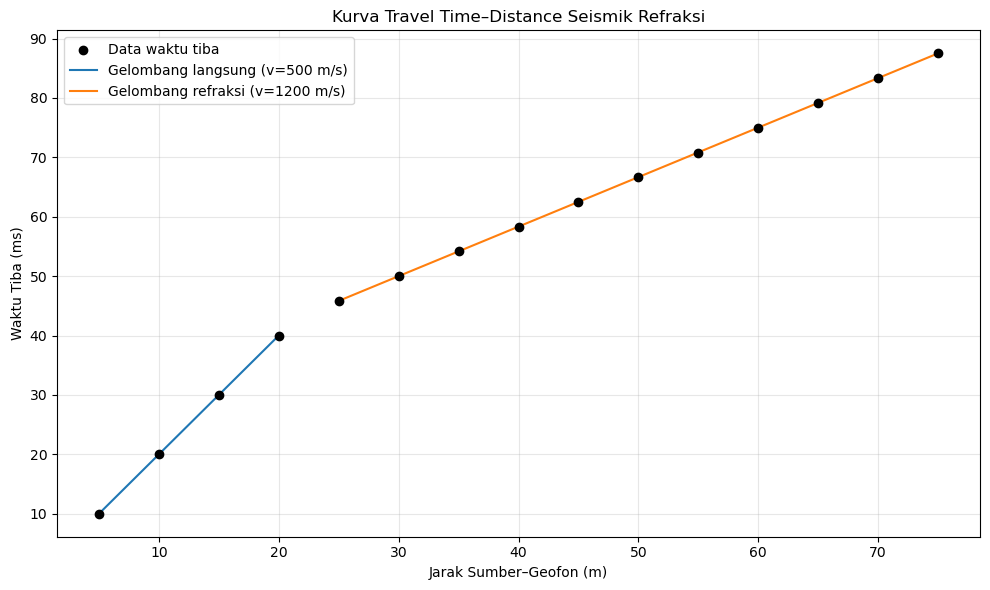

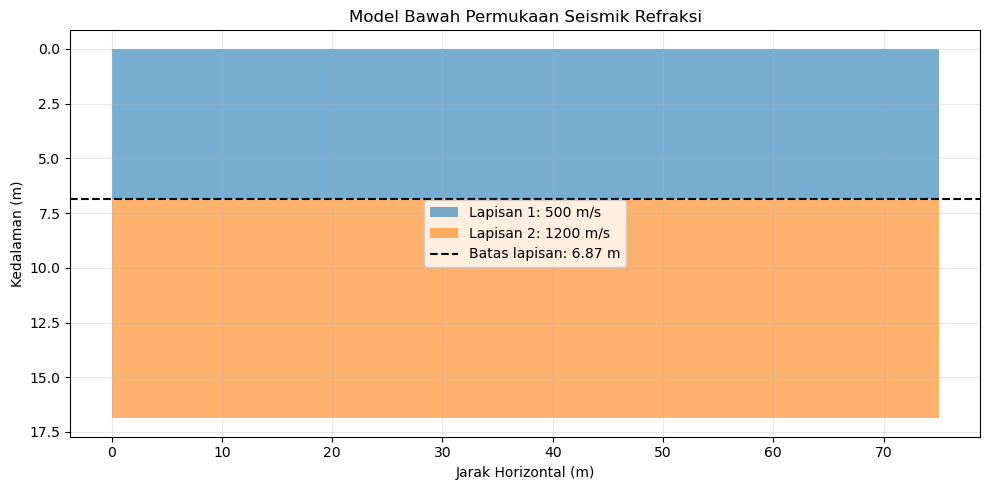


=== INTERPRETASI MODEL ===
Lapisan pertama memiliki kecepatan sekitar 500.00 m/s.
Lapisan kedua memiliki kecepatan sekitar 1199.83 m/s.
Batas antara kedua lapisan diperkirakan berada pada kedalaman 6.87 m.
Kecepatan lapisan kedua yang lebih tinggi konsisten dengan asumsi model refraksi dua lapisan.
Jenis material tidak dapat dipastikan dari kecepatan saja. Interpretasi perlu mempertimbangkan kondisi geologi, kelembapan, tingkat pelapukan, porositas, dan data pendukung.

File berhasil disimpan:
- data_waktu_tiba.csv
- hasil_kecepatan_lapisan.csv
- travel_time_distance.png
- model_bawah_permukaan.png


In [26]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# ANALISIS SEISMIK REFRAKSI
# Travel Time, Gradien, Kecepatan, dan Kedalaman Lapisan
# ==========================================================

# 1. INPUT DATA
# Data simulasi, bukan data pengukuran lapangan.
data = {
    "Jarak_m": [
        5, 10, 15, 20, 25,
        30, 35, 40, 45, 50,
        55, 60, 65, 70, 75
    ],
    "Waktu_Tiba_ms": [
        10.0, 20.0, 30.0, 40.0, 45.8,
        50.0, 54.2, 58.3, 62.5, 66.7,
        70.8, 75.0, 79.2, 83.3, 87.5
    ]
}

df = pd.DataFrame(data)

# Konversi waktu milidetik ke detik
df["Waktu_Tiba_s"] = df["Waktu_Tiba_ms"] / 1000.0

# 2. MENENTUKAN SEGMEN GELOMBANG
# Asumsi contoh:
# Jarak <= 20 m : gelombang langsung, lapisan 1
# Jarak >= 25 m : gelombang refraksi, lapisan 2
#
# Untuk data lapangan, tentukan segmen berdasarkan
# perubahan gradien pada grafik travel time.

segmen_1 = df[df["Jarak_m"] <= 20].copy()
segmen_2 = df[df["Jarak_m"] >= 25].copy()

if len(segmen_1) < 2 or len(segmen_2) < 2:
    raise ValueError(
        "Setiap segmen harus memiliki minimal dua titik data."
    )

# 3. REGRESI LINEAR
# Persamaan: t = m*x + b
# m = gradien dalam s/m
# b = waktu intersep dalam detik

def analisis_segmen(segmen):
    x = segmen["Jarak_m"].to_numpy(dtype=float)
    t = segmen["Waktu_Tiba_s"].to_numpy(dtype=float)

    m, b = np.polyfit(x, t, 1)

    t_prediksi = m * x + b

    ss_res = np.sum((t - t_prediksi) ** 2)
    ss_tot = np.sum((t - np.mean(t)) ** 2)

    r2 = (
        1 - ss_res / ss_tot
        if ss_tot > 0 else np.nan
    )

    return m, b, r2

m1, b1, r2_1 = analisis_segmen(segmen_1)
m2, b2, r2_2 = analisis_segmen(segmen_2)

# 4. MENGHITUNG KECEPATAN GELOMBANG
# Kecepatan = 1 / gradien

if m1 <= 0 or m2 <= 0:
    raise ValueError(
        "Gradien harus positif untuk model waktu tempuh ini."
    )

v1 = 1 / m1
v2 = 1 / m2

# 5. MENGHITUNG KEDALAMAN BATAS LAPISAN
# Model dua lapisan horizontal:
# v2 harus lebih besar daripada v1.
# Sudut kritis ic = arcsin(v1/v2)
# Kedalaman h = (ti * v1) / (2*cos(ic))

if v2 <= v1:
    raise ValueError(
        "Kecepatan lapisan 2 harus lebih besar daripada "
        "kecepatan lapisan 1. Periksa pembagian segmen."
    )

# Waktu intersep refraksi harus positif
if b2 <= 0:
    raise ValueError(
        "Waktu intersep tidak positif. Periksa data dan regresi."
    )

sudut_kritis_rad = np.arcsin(v1 / v2)
sudut_kritis_derajat = np.degrees(sudut_kritis_rad)

h = (
    b2 * v1
    / (2 * np.cos(sudut_kritis_rad))
)

# 6. TABEL HASIL REGRESI
hasil = pd.DataFrame({
    "Lapisan": ["Lapisan 1", "Lapisan 2"],
    "Jenis_Gelombang": [
        "Gelombang langsung",
        "Gelombang refraksi"
    ],
    "Gradien_s_per_m": [m1, m2],
    "Waktu_Intersep_s": [b1, b2],
    "Kecepatan_m_per_s": [v1, v2],
    "R_squared": [r2_1, r2_2]
})

# 7. MENAMPILKAN DATA DAN HASIL
print("\n=== TABEL JARAK DAN WAKTU TIBA ===")
print(
    df[["Jarak_m", "Waktu_Tiba_ms", "Waktu_Tiba_s"]]
    .round(4)
    .to_string(index=False)
)

print("\n=== HASIL REGRESI DAN KECEPATAN ===")
print(hasil.round(5).to_string(index=False))

print("\n=== HASIL KEDALAMAN LAPISAN ===")
print(f"Kecepatan lapisan 1 : {v1:.2f} m/s")
print(f"Kecepatan lapisan 2 : {v2:.2f} m/s")
print(f"Waktu intersep      : {b2:.5f} s")
print(f"Sudut kritis        : {sudut_kritis_derajat:.2f} derajat")
print(f"Kedalaman batas     : {h:.2f} m")

# 8. GRAFIK TRAVEL TIME-DISTANCE
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Jarak_m"],
    df["Waktu_Tiba_ms"],
    color="black",
    label="Data waktu tiba",
    zorder=3
)

# Garis regresi gelombang langsung
x1 = np.linspace(
    segmen_1["Jarak_m"].min(),
    segmen_1["Jarak_m"].max(),
    100
)

plt.plot(
    x1,
    (m1 * x1 + b1) * 1000,
    label=f"Gelombang langsung (v={v1:.0f} m/s)"
)

# Garis regresi gelombang refraksi
x2 = np.linspace(
    segmen_2["Jarak_m"].min(),
    segmen_2["Jarak_m"].max(),
    100
)

plt.plot(
    x2,
    (m2 * x2 + b2) * 1000,
    label=f"Gelombang refraksi (v={v2:.0f} m/s)"
)

plt.xlabel("Jarak Sumber–Geofon (m)")
plt.ylabel("Waktu Tiba (ms)")
plt.title("Kurva Travel Time–Distance Seismik Refraksi")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("travel_time_distance.png", dpi=300)
plt.show()

# 9. MODEL BAWAH PERMUKAAN
x_min = 0
x_max = df["Jarak_m"].max()

plt.figure(figsize=(10, 5))

plt.fill_between(
    [x_min, x_max],
    [0, 0],
    [h, h],
    alpha=0.6,
    label=f"Lapisan 1: {v1:.0f} m/s"
)

plt.fill_between(
    [x_min, x_max],
    [h, h],
    [h + 10, h + 10],
    alpha=0.6,
    label=f"Lapisan 2: {v2:.0f} m/s"
)

plt.axhline(
    h,
    linestyle="--",
    color="black",
    label=f"Batas lapisan: {h:.2f} m"
)

plt.gca().invert_yaxis()
plt.xlabel("Jarak Horizontal (m)")
plt.ylabel("Kedalaman (m)")
plt.title("Model Bawah Permukaan Seismik Refraksi")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("model_bawah_permukaan.png", dpi=300)
plt.show()

# 10. INTERPRETASI
print("\n=== INTERPRETASI MODEL ===")

print(
    f"Lapisan pertama memiliki kecepatan sekitar {v1:.2f} m/s."
)

print(
    f"Lapisan kedua memiliki kecepatan sekitar {v2:.2f} m/s."
)

print(
    f"Batas antara kedua lapisan diperkirakan berada pada "
    f"kedalaman {h:.2f} m."
)

print(
    "Kecepatan lapisan kedua yang lebih tinggi konsisten "
    "dengan asumsi model refraksi dua lapisan."
)

print(
    "Jenis material tidak dapat dipastikan dari kecepatan "
    "saja. Interpretasi perlu mempertimbangkan kondisi geologi, "
    "kelembapan, tingkat pelapukan, porositas, dan data pendukung."
)

# 11. MENYIMPAN HASIL
df.to_csv("data_waktu_tiba.csv", index=False)
hasil.to_csv("hasil_kecepatan_lapisan.csv", index=False)

print("\nFile berhasil disimpan:")
print("- data_waktu_tiba.csv")
print("- hasil_kecepatan_lapisan.csv")
print("- travel_time_distance.png")
print("- model_bawah_permukaan.png")

3. **Context:** Data diperoleh dari survei seismik refraksi menggunakan sumber getaran dan beberapa geofon yang ditempatkan pada sepanjang lintasan. Gelombang seismik merambat melalui material bawah permukaan dengan kecepatan yang berbeda sesuai sifat materialnya.

   **Output:** Menghasilkan gambaran struktur lapisan bawah permukaan berdasarkan variasi kecepatan gelombang seismik.

TABEL DATA SEISMIK REFRAKSI
 Jarak_Geofon_m  Waktu_Tiba_ms  Waktu_Tiba_s
            5.0           10.0        0.0100
           10.0           20.0        0.0200
           15.0           30.0        0.0300
           20.0           40.0        0.0400
           25.0           45.8        0.0458
           30.0           50.0        0.0500
           35.0           54.2        0.0542
           40.0           58.3        0.0583
           45.0           62.5        0.0625
           50.0           66.7        0.0667
           55.0           70.8        0.0708
           60.0           75.0        0.0750
           65.0           79.2        0.0792
           70.0           83.3        0.0833
           75.0           87.5        0.0875

HASIL ANALISIS KECEPATAN
  Lapisan  Kemiringan_s_per_m  Intersep_s  Kecepatan_m_per_s  R_squared
Lapisan 1             0.00200     0.00000          500.00000        1.0
Lapisan 2             0.00083     0.02499         1199.82548        1.0

HASIL EST

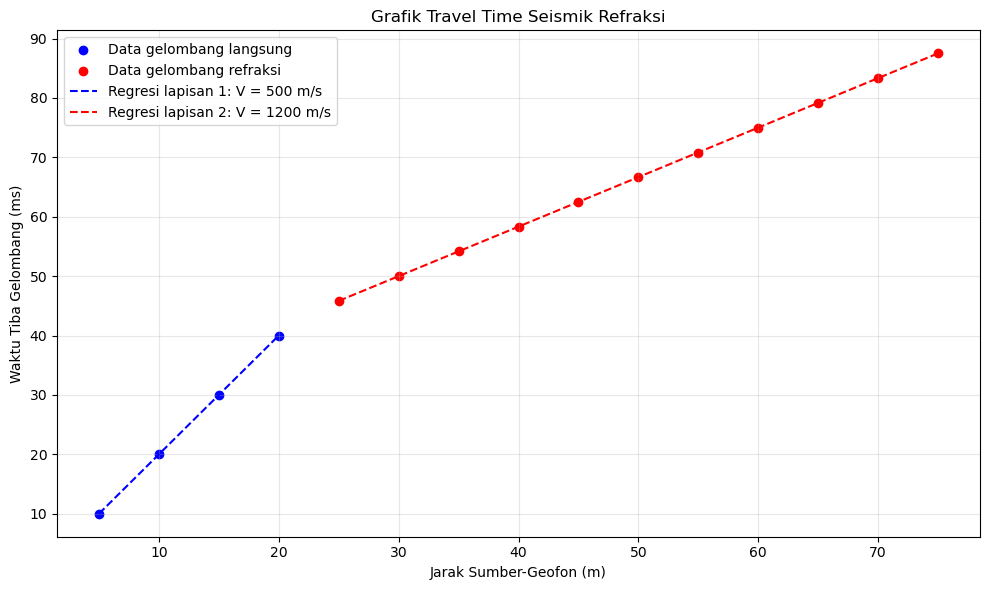

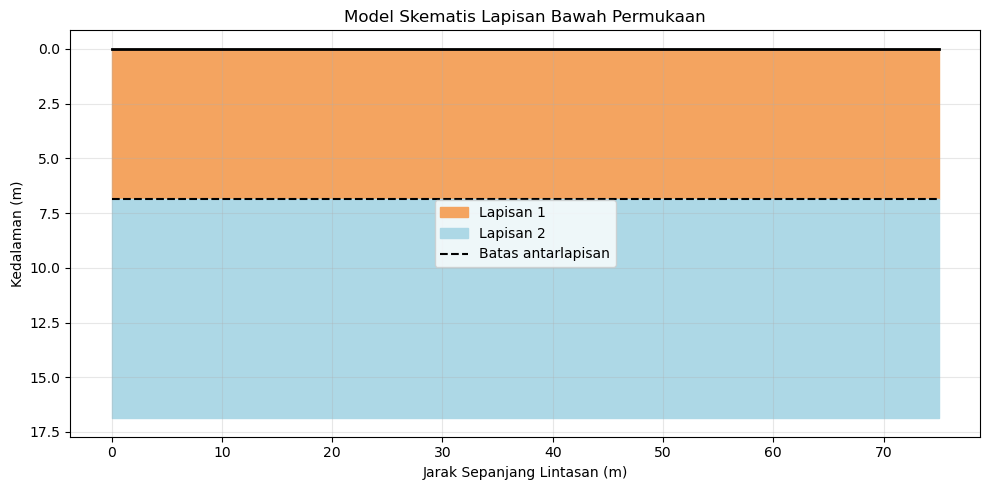


INTERPRETASI
Kecepatan gelombang lapisan 1 sekitar 500.00 m/s.
Kecepatan gelombang lapisan 2 sekitar 1199.83 m/s.
Batas kedua lapisan diperkirakan pada kedalaman 6.87 m.
Model ini mengasumsikan dua lapisan horizontal dengan kecepatan lapisan kedua lebih tinggi.
Hasil grafik dan tabel telah disimpan.


In [27]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# PENGOLAHAN DATA SEISMIK REFRAKSI
# ==========================================

# Data contoh survei seismik refraksi
# Ganti dengan data pengukuran sebenarnya jika tersedia

jarak = np.array([
    5, 10, 15, 20, 25,
    30, 35, 40, 45, 50,
    55, 60, 65, 70, 75
], dtype=float)

waktu_ms = np.array([
    10.0, 20.0, 30.0, 40.0, 45.8,
    50.0, 54.2, 58.3, 62.5, 66.7,
    70.8, 75.0, 79.2, 83.3, 87.5
], dtype=float)

# Konversi waktu dari milidetik ke sekon
waktu = waktu_ms / 1000

# Membuat tabel data
data = pd.DataFrame({
    "Jarak_Geofon_m": jarak,
    "Waktu_Tiba_ms": waktu_ms,
    "Waktu_Tiba_s": waktu
})

print("TABEL DATA SEISMIK REFRAKSI")
print(data.to_string(index=False))

# ==========================================
# ANALISIS SEGMEN WAKTU TEMPUH
# ==========================================

# Pembagian segmen berdasarkan data contoh
# Segmen 1: gelombang langsung
# Segmen 2: gelombang refraksi
segmen1 = jarak <= 20
segmen2 = jarak >= 25

def analisis_segmen(x, t):
    # Regresi linear: t = m*x + b
    m, b = np.polyfit(x, t, 1)

    # Menghitung koefisien determinasi R^2
    prediksi = m * x + b
    ss_res = np.sum((t - prediksi) ** 2)
    ss_tot = np.sum((t - np.mean(t)) ** 2)

    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    # Kecepatan = 1 / kemiringan grafik
    kecepatan = 1 / m if m > 0 else np.nan

    return m, b, kecepatan, r2

m1, b1, v1, r21 = analisis_segmen(
    jarak[segmen1], waktu[segmen1]
)

m2, b2, v2, r22 = analisis_segmen(
    jarak[segmen2], waktu[segmen2]
)

hasil = pd.DataFrame({
    "Lapisan": ["Lapisan 1", "Lapisan 2"],
    "Kemiringan_s_per_m": [m1, m2],
    "Intersep_s": [b1, b2],
    "Kecepatan_m_per_s": [v1, v2],
    "R_squared": [r21, r22]
})

print("\nHASIL ANALISIS KECEPATAN")
print(hasil.round(5).to_string(index=False))

# ==========================================
# ESTIMASI KEDALAMAN BATAS LAPISAN
# ==========================================

kedalaman = np.nan

if (
    np.isfinite(v1)
    and np.isfinite(v2)
    and v2 > v1
    and b2 > 0
):
    # Sudut kritis pada model dua lapisan horizontal
    sudut_kritis = np.arcsin(v1 / v2)

    # Kedalaman batas lapisan
    kedalaman = (
        b2 * v1 /
        (2 * np.cos(sudut_kritis))
    )

    print("\nHASIL ESTIMASI KEDALAMAN")
    print(f"Kecepatan lapisan 1 : {v1:.2f} m/s")
    print(f"Kecepatan lapisan 2 : {v2:.2f} m/s")
    print(f"Sudut kritis        : {np.degrees(sudut_kritis):.2f} derajat")
    print(f"Kedalaman batas     : {kedalaman:.2f} m")
else:
    print(
        "\nKedalaman belum dapat dihitung dengan model ini. "
        "Periksa pembagian segmen dan hasil regresi."
    )

# ==========================================
# GRAFIK TRAVEL TIME TERHADAP JARAK
# ==========================================

plt.figure(figsize=(10, 6))

plt.scatter(
    jarak[segmen1], waktu[segmen1] * 1000,
    color="blue", label="Data gelombang langsung"
)

plt.scatter(
    jarak[segmen2], waktu[segmen2] * 1000,
    color="red", label="Data gelombang refraksi"
)

x1 = np.linspace(jarak[segmen1].min(),
                 jarak[segmen1].max(), 100)
x2 = np.linspace(jarak[segmen2].min(),
                 jarak[segmen2].max(), 100)

plt.plot(
    x1, (m1 * x1 + b1) * 1000,
    color="blue", linestyle="--",
    label=f"Regresi lapisan 1: V = {v1:.0f} m/s"
)

plt.plot(
    x2, (m2 * x2 + b2) * 1000,
    color="red", linestyle="--",
    label=f"Regresi lapisan 2: V = {v2:.0f} m/s"
)

plt.xlabel("Jarak Sumber-Geofon (m)")
plt.ylabel("Waktu Tiba Gelombang (ms)")
plt.title("Grafik Travel Time Seismik Refraksi")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("grafik_travel_time.png", dpi=300)
plt.show()

# ==========================================
# MODEL STRUKTUR BAWAH PERMUKAAN
# ==========================================

if np.isfinite(kedalaman) and kedalaman > 0:
    plt.figure(figsize=(10, 5))

    # Model skematis, bukan hasil inversi lengkap
    plt.fill_between(
        [0, jarak.max()],
        0, kedalaman,
        color="sandybrown",
        label="Lapisan 1"
    )

    plt.fill_between(
        [0, jarak.max()],
        kedalaman, kedalaman + 10,
        color="lightblue",
        label="Lapisan 2"
    )

    # Permukaan tanah dan batas lapisan
    plt.plot(
        [0, jarak.max()], [0, 0],
        color="black", linewidth=2
    )

    plt.plot(
        [0, jarak.max()],
        [kedalaman, kedalaman],
        color="black", linestyle="--",
        label="Batas antarlapisan"
    )

    plt.gca().invert_yaxis()
    plt.xlabel("Jarak Sepanjang Lintasan (m)")
    plt.ylabel("Kedalaman (m)")
    plt.title("Model Skematis Lapisan Bawah Permukaan")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("model_lapisan_bawah_permukaan.png", dpi=300)
    plt.show()

# ==========================================
# MENYIMPAN HASIL
# ==========================================

data.to_csv("data_seismik_refraksi.csv", index=False)
hasil.to_csv("hasil_kecepatan_lapisan.csv", index=False)

print("\nINTERPRETASI")
print(f"Kecepatan gelombang lapisan 1 sekitar {v1:.2f} m/s.")
print(f"Kecepatan gelombang lapisan 2 sekitar {v2:.2f} m/s.")

if np.isfinite(kedalaman) and kedalaman > 0:
    print(
        f"Batas kedua lapisan diperkirakan pada kedalaman "
        f"{kedalaman:.2f} m."
    )

print(
    "Model ini mengasumsikan dua lapisan horizontal "
    "dengan kecepatan lapisan kedua lebih tinggi."
)
print("Hasil grafik dan tabel telah disimpan.")

4. **Input:** Masukkan data berupa posisi sumber, posisi geofon, jarak antar geofon, waktu tiba gelombang, serta informasi lintasan pengukuran.

   **Output:** Menghasilkan tabel pengolahan, grafik travel time terhadap jarak, kecepatan gelombang, kedalaman lapisan, dan model bawah permukaan.

PENGOLAHAN DATA SEISMIK REFRAKSI
Nama lintasan: Lintasan Seismik 1
Jumlah geofon: 15

TABEL DATA PENGUKURAN
 Posisi_Sumber_m  Posisi_Geofon_m  Jarak_Sumber_Geofon_m  Waktu_Tiba_ms  Waktu_Tiba_s
             0.0              5.0                    5.0           10.0        0.0100
             0.0             10.0                   10.0           20.0        0.0200
             0.0             15.0                   15.0           30.0        0.0300
             0.0             20.0                   20.0           40.0        0.0400
             0.0             25.0                   25.0           45.8        0.0458
             0.0             30.0                   30.0           50.0        0.0500
             0.0             35.0                   35.0           54.2        0.0542
             0.0             40.0                   40.0           58.3        0.0583
             0.0             45.0                   45.0           62.5        0.0625
             0.0             50.

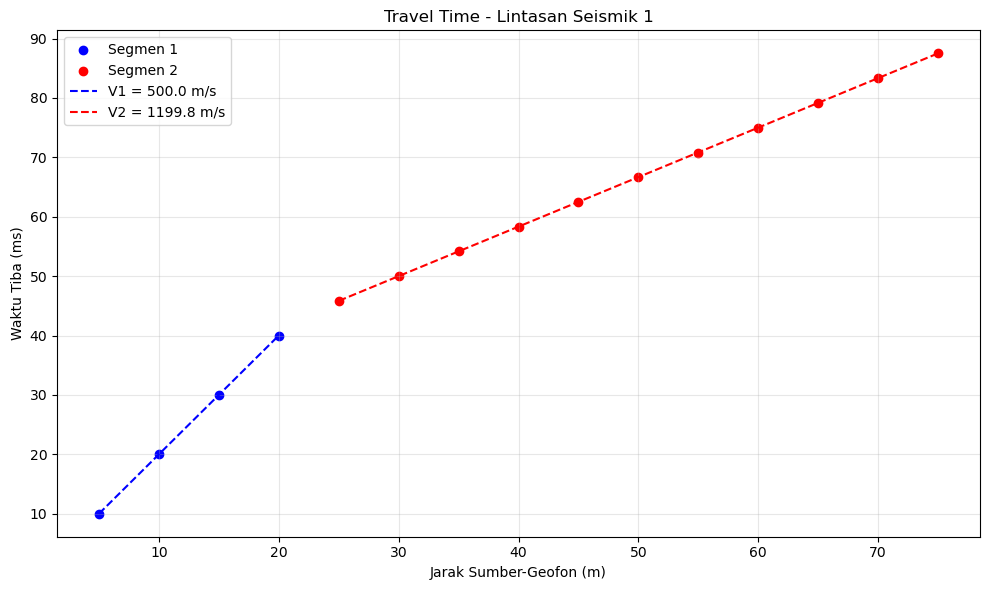

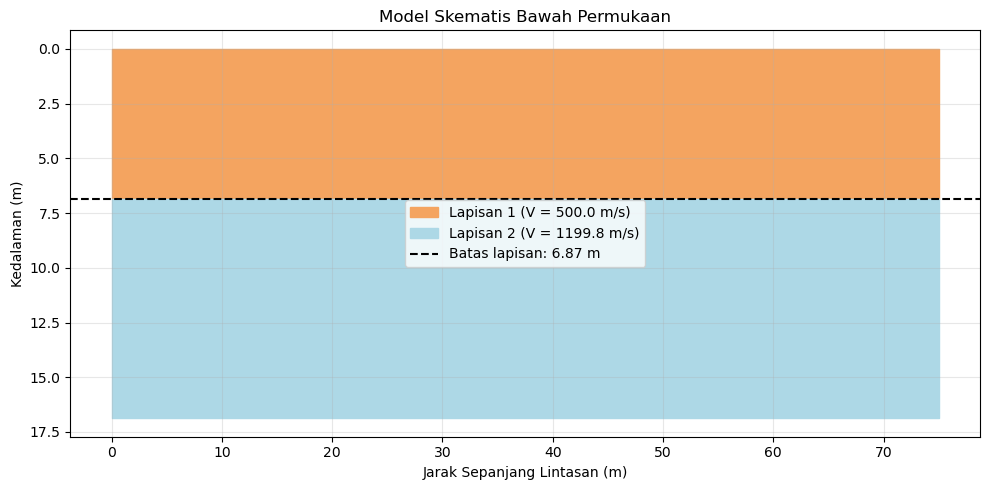


FILE HASIL BERHASIL DISIAPKAN:
1. tabel_pengolahan_seismik.csv
2. hasil_kecepatan_seismik.csv
3. grafik_travel_time.png
4. model_bawah_permukaan.png

INTERPRETASI:
Kecepatan segmen 1: 500.00 m/s
Kecepatan segmen 2: 1199.83 m/s
Estimasi kedalaman batas lapisan: 6.87 m
Interpretasi menggunakan asumsi dua lapisan horizontal dan kecepatan lapisan kedua lebih tinggi.


In [28]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. INPUT DATA SURVEI
# ==========================================

# Informasi lintasan pengukuran
nama_lintasan = "Lintasan Seismik 1"
posisi_sumber = 0.0  # meter
jumlah_geofon = 15

# Posisi geofon sepanjang lintasan (meter)
posisi_geofon = np.array([
    5, 10, 15, 20, 25,
    30, 35, 40, 45, 50,
    55, 60, 65, 70, 75
], dtype=float)

# Waktu tiba gelombang (milidetik)
waktu_tiba_ms = np.array([
    10.0, 20.0, 30.0, 40.0, 45.8,
    50.0, 54.2, 58.3, 62.5, 66.7,
    70.8, 75.0, 79.2, 83.3, 87.5
], dtype=float)

# Validasi jumlah data
if len(posisi_geofon) != len(waktu_tiba_ms):
    raise ValueError(
        "Jumlah posisi geofon harus sama dengan jumlah waktu tiba."
    )

if len(posisi_geofon) < 4:
    raise ValueError("Data terlalu sedikit untuk analisis dua segmen.")

if not np.all(np.isfinite(posisi_geofon)):
    raise ValueError("Posisi geofon mengandung data tidak valid.")

if not np.all(np.isfinite(waktu_tiba_ms)):
    raise ValueError("Waktu tiba mengandung data tidak valid.")

if np.any(waktu_tiba_ms < 0):
    raise ValueError("Waktu tiba tidak boleh negatif.")

# ==========================================
# 2. MENGHITUNG JARAK SUMBER-GEOFON
# ==========================================

jarak = np.abs(posisi_geofon - posisi_sumber)

# Jarak antar geofon yang berurutan
jarak_antar_geofon = np.diff(posisi_geofon)

# Konversi waktu ke sekon
waktu_tiba_s = waktu_tiba_ms / 1000

# Tabel pengolahan data
data = pd.DataFrame({
    "Posisi_Sumber_m": posisi_sumber,
    "Posisi_Geofon_m": posisi_geofon,
    "Jarak_Sumber_Geofon_m": jarak,
    "Waktu_Tiba_ms": waktu_tiba_ms,
    "Waktu_Tiba_s": waktu_tiba_s
})

print("=" * 60)
print("PENGOLAHAN DATA SEISMIK REFRAKSI")
print("Nama lintasan:", nama_lintasan)
print("Jumlah geofon:", jumlah_geofon)
print("=" * 60)

print("\nTABEL DATA PENGUKURAN")
print(data.to_string(index=False))

print("\nJARAK ANTAR GEOFON")
print(jarak_antar_geofon)

# ==========================================
# 3. PEMBAGIAN SEGMEN
# ==========================================

# Pembagian ini hanya untuk data contoh.
# Sesuaikan dengan perubahan kemiringan grafik
# pada data survei sebenarnya.

indeks_batas = 4

x1 = jarak[:indeks_batas]
t1 = waktu_tiba_s[:indeks_batas]

x2 = jarak[indeks_batas:]
t2 = waktu_tiba_s[indeks_batas:]

# ==========================================
# 4. REGRESI LINEAR DAN KECEPATAN
# ==========================================

def analisis_segmen(x, t):
    m, b = np.polyfit(x, t, 1)

    prediksi = m * x + b
    ss_res = np.sum((t - prediksi) ** 2)
    ss_tot = np.sum((t - np.mean(t)) ** 2)

    r2 = (
        1 - ss_res / ss_tot
        if ss_tot > 0 else np.nan
    )

    kecepatan = 1 / m if m > 0 else np.nan

    return m, b, kecepatan, r2


m1, b1, v1, r21 = analisis_segmen(x1, t1)
m2, b2, v2, r22 = analisis_segmen(x2, t2)

hasil = pd.DataFrame({
    "Segmen": ["Segmen 1", "Segmen 2"],
    "Kemiringan_s_per_m": [m1, m2],
    "Intersep_s": [b1, b2],
    "Kecepatan_m_per_s": [v1, v2],
    "R_squared": [r21, r22]
})

print("\nHASIL ANALISIS SEGMEN")
print(hasil.round(5).to_string(index=False))

# ==========================================
# 5. ESTIMASI KEDALAMAN BATAS LAPISAN
# ==========================================

kedalaman = np.nan

if (
    np.isfinite(v1)
    and np.isfinite(v2)
    and v2 > v1
    and b2 > 0
):
    sudut_kritis = np.arcsin(v1 / v2)

    kedalaman = (
        b2 * v1 /
        (2 * np.cos(sudut_kritis))
    )

    print("\nHASIL ESTIMASI KEDALAMAN")
    print(f"Sudut kritis: {np.degrees(sudut_kritis):.2f} derajat")
    print(f"Kedalaman batas lapisan: {kedalaman:.2f} m")
else:
    print(
        "\nKedalaman tidak dapat dihitung dengan model ini. "
        "Periksa hasil regresi dan pembagian segmen."
    )

# ==========================================
# 6. GRAFIK TRAVEL TIME TERHADAP JARAK
# ==========================================

plt.figure(figsize=(10, 6))

plt.scatter(
    x1, t1 * 1000,
    label="Segmen 1", color="blue"
)

plt.scatter(
    x2, t2 * 1000,
    label="Segmen 2", color="red"
)

xx1 = np.linspace(x1.min(), x1.max(), 100)
xx2 = np.linspace(x2.min(), x2.max(), 100)

plt.plot(
    xx1, (m1 * xx1 + b1) * 1000,
    "--", color="blue",
    label=f"V1 = {v1:.1f} m/s"
)

plt.plot(
    xx2, (m2 * xx2 + b2) * 1000,
    "--", color="red",
    label=f"V2 = {v2:.1f} m/s"
)

plt.xlabel("Jarak Sumber-Geofon (m)")
plt.ylabel("Waktu Tiba (ms)")
plt.title(f"Travel Time - {nama_lintasan}")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("grafik_travel_time.png", dpi=300)
plt.show()

# ==========================================
# 7. MODEL BAWAH PERMUKAAN
# ==========================================

if np.isfinite(kedalaman) and kedalaman > 0:
    panjang_lintasan = np.max(jarak)

    plt.figure(figsize=(10, 5))

    plt.fill_between(
        [0, panjang_lintasan],
        0, kedalaman,
        color="sandybrown",
        label=f"Lapisan 1 (V = {v1:.1f} m/s)"
    )

    plt.fill_between(
        [0, panjang_lintasan],
        kedalaman, kedalaman + 10,
        color="lightblue",
        label=f"Lapisan 2 (V = {v2:.1f} m/s)"
    )

    plt.axhline(
        kedalaman, color="black",
        linestyle="--",
        label=f"Batas lapisan: {kedalaman:.2f} m"
    )

    plt.gca().invert_yaxis()
    plt.xlabel("Jarak Sepanjang Lintasan (m)")
    plt.ylabel("Kedalaman (m)")
    plt.title("Model Skematis Bawah Permukaan")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("model_bawah_permukaan.png", dpi=300)
    plt.show()

# ==========================================
# 8. EKSPOR HASIL
# ==========================================

data.to_csv("tabel_pengolahan_seismik.csv", index=False)
hasil.to_csv("hasil_kecepatan_seismik.csv", index=False)

print("\nFILE HASIL BERHASIL DISIAPKAN:")
print("1. tabel_pengolahan_seismik.csv")
print("2. hasil_kecepatan_seismik.csv")
print("3. grafik_travel_time.png")
print("4. model_bawah_permukaan.png")

print("\nINTERPRETASI:")
print(f"Kecepatan segmen 1: {v1:.2f} m/s")
print(f"Kecepatan segmen 2: {v2:.2f} m/s")

if np.isfinite(kedalaman) and kedalaman > 0:
    print(f"Estimasi kedalaman batas lapisan: {kedalaman:.2f} m")

print(
    "Interpretasi menggunakan asumsi dua lapisan horizontal "
    "dan kecepatan lapisan kedua lebih tinggi."
)

5. **Constraints:** Gunakan konsep seismik refraksi dan persamaan travel time yang sesuai. Pastikan satuan jarak dan waktu konsisten. Interpretasi kecepatan tidak boleh langsung dianggap sebagai jenis batuan tertentu tanpa mempertimbangkan kondisi geologi dan informasi tambahan.

   **Output:** Menghasilkan model bawah permukaan yang sesuai dengan data waktu tiba dan prinsip seismik refraksi.


TABEL DATA SEISMIK REFRAKSI
 Posisi_Geofon_m  Jarak_Sumber_Geofon_m  Waktu_Tiba_ms  Waktu_Tiba_s
             5.0                    5.0           10.0        0.0100
            10.0                   10.0           20.0        0.0200
            15.0                   15.0           30.0        0.0300
            20.0                   20.0           40.0        0.0400
            25.0                   25.0           45.8        0.0458
            30.0                   30.0           50.0        0.0500
            35.0                   35.0           54.2        0.0542
            40.0                   40.0           58.3        0.0583
            45.0                   45.0           62.5        0.0625
            50.0                   50.0           66.7        0.0667
            55.0                   55.0           70.8        0.0708
            60.0                   60.0           75.0        0.0750
            65.0                   65.0           79.2        0.0792
     

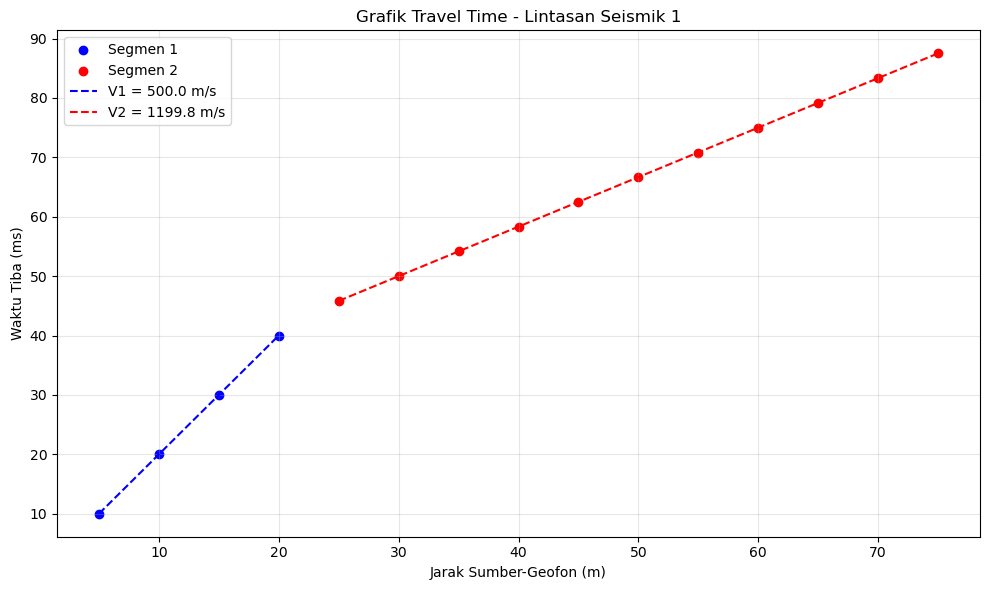

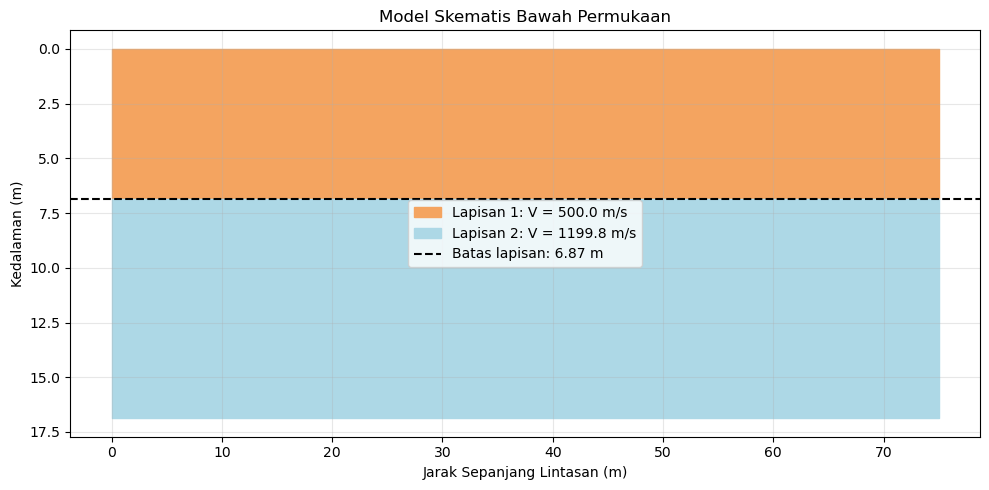


TABEL HASIL REGRESI
  Segmen  Kemiringan_s_per_m  Intersep_s  Kecepatan_m_per_s  R_squared
Segmen 1             0.00200     0.00000          500.00000        1.0
Segmen 2             0.00083     0.02499         1199.82548        1.0

File CSV dan grafik disimpan pada folder kerja.
Interpretasi kecepatan tidak digunakan untuk menetapkan jenis batuan secara langsung. Identifikasi litologi memerlukan informasi geologi atau data pendukung.


In [29]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. DATA SEISMIK REFRAKSI
# ==========================================

nama_lintasan = "Lintasan Seismik 1"
posisi_sumber = 0.0  # meter

posisi_geofon = np.array([
    5, 10, 15, 20, 25,
    30, 35, 40, 45, 50,
    55, 60, 65, 70, 75
], dtype=float)

waktu_tiba_ms = np.array([
    10.0, 20.0, 30.0, 40.0, 45.8,
    50.0, 54.2, 58.3, 62.5, 66.7,
    70.8, 75.0, 79.2, 83.3, 87.5
], dtype=float)

# ==========================================
# 2. VALIDASI DAN KONSISTENSI SATUAN
# ==========================================

if len(posisi_geofon) != len(waktu_tiba_ms):
    raise ValueError("Jumlah geofon dan waktu tiba tidak sama.")

if len(posisi_geofon) < 4:
    raise ValueError("Data tidak cukup untuk regresi dua segmen.")

if not np.all(np.isfinite(posisi_geofon)):
    raise ValueError("Posisi geofon mengandung nilai tidak valid.")

if not np.all(np.isfinite(waktu_tiba_ms)):
    raise ValueError("Waktu tiba mengandung nilai tidak valid.")

if np.any(waktu_tiba_ms < 0):
    raise ValueError("Waktu tiba tidak boleh negatif.")

if np.any(np.diff(posisi_geofon) <= 0):
    raise ValueError("Posisi geofon harus berurutan dan meningkat.")

jarak = np.abs(posisi_geofon - posisi_sumber)
waktu_s = waktu_tiba_ms / 1000.0

# ==========================================
# 3. TABEL DATA PENGUKURAN
# ==========================================

data = pd.DataFrame({
    "Posisi_Geofon_m": posisi_geofon,
    "Jarak_Sumber_Geofon_m": jarak,
    "Waktu_Tiba_ms": waktu_tiba_ms,
    "Waktu_Tiba_s": waktu_s
})

print("\nTABEL DATA SEISMIK REFRAKSI")
print(data.to_string(index=False))

# ==========================================
# 4. PEMBAGIAN SEGMEN
# ==========================================

# Batas berikut khusus untuk data simulasi.
# Untuk data lapangan, tentukan batas berdasarkan
# perubahan kemiringan grafik travel time.

indeks_batas = 4

x1, t1 = jarak[:indeks_batas], waktu_s[:indeks_batas]
x2, t2 = jarak[indeks_batas:], waktu_s[indeks_batas:]

# ==========================================
# 5. REGRESI TRAVEL TIME
# ==========================================

def regresi_linear(x, t):
    m, b = np.polyfit(x, t, 1)

    prediksi = m * x + b
    ss_res = np.sum((t - prediksi) ** 2)
    ss_tot = np.sum((t - np.mean(t)) ** 2)

    r2 = (
        1 - ss_res / ss_tot
        if ss_tot > 0 else np.nan
    )

    return m, b, r2


m1, b1, r21 = regresi_linear(x1, t1)
m2, b2, r22 = regresi_linear(x2, t2)

# Kemiringan travel time memiliki satuan s/m.
# Kecepatan merupakan kebalikan kemiringan.

if m1 <= 0 or m2 <= 0:
    raise ValueError("Kemiringan harus positif untuk model ini.")

v1 = 1.0 / m1
v2 = 1.0 / m2

print("\nHASIL REGRESI")
print(f"Kemiringan segmen 1 : {m1:.6f} s/m")
print(f"Kemiringan segmen 2 : {m2:.6f} s/m")
print(f"Kecepatan lapisan 1 : {v1:.2f} m/s")
print(f"Kecepatan lapisan 2 : {v2:.2f} m/s")
print(f"R² segmen 1         : {r21:.5f}")
print(f"R² segmen 2         : {r22:.5f}")

# ==========================================
# 6. UJI KELAYAKAN MODEL DUA LAPISAN
# ==========================================

kedalaman = np.nan
sudut_kritis = np.nan

if v2 <= v1:
    print(
        "\nModel refraksi dua lapisan sederhana tidak memenuhi "
        "syarat V2 > V1. Periksa pembagian segmen atau gunakan "
        "model yang sesuai dengan kondisi geologi."
    )
elif b2 <= 0:
    print(
        "\nIntersep waktu tidak positif. Estimasi kedalaman "
        "tidak ditampilkan karena model belum memenuhi asumsi."
    )
else:
    rasio = v1 / v2

    # Pengamanan domain fungsi arcsin
    if not 0 < rasio < 1:
        print("Rasio kecepatan tidak memenuhi syarat sudut kritis.")
    else:
        sudut_kritis = np.arcsin(rasio)

        # h = ti * V1 / (2 cos ic)
        kedalaman = (
            b2 * v1 /
            (2 * np.cos(sudut_kritis))
        )

        print("\nHASIL ESTIMASI KEDALAMAN")
        print(f"Waktu intersep : {b2:.6f} s")
        print(
            f"Sudut kritis   : "
            f"{np.degrees(sudut_kritis):.2f} derajat"
        )
        print(f"Kedalaman batas: {kedalaman:.2f} m")

# ==========================================
# 7. GRAFIK TRAVEL TIME
# ==========================================

plt.figure(figsize=(10, 6))

plt.scatter(
    x1, t1 * 1000,
    label="Segmen 1", color="blue"
)

plt.scatter(
    x2, t2 * 1000,
    label="Segmen 2", color="red"
)

xx1 = np.linspace(x1.min(), x1.max(), 100)
xx2 = np.linspace(x2.min(), x2.max(), 100)

plt.plot(
    xx1, (m1 * xx1 + b1) * 1000,
    "--", color="blue",
    label=f"V1 = {v1:.1f} m/s"
)

plt.plot(
    xx2, (m2 * xx2 + b2) * 1000,
    "--", color="red",
    label=f"V2 = {v2:.1f} m/s"
)

plt.xlabel("Jarak Sumber-Geofon (m)")
plt.ylabel("Waktu Tiba (ms)")
plt.title(f"Grafik Travel Time - {nama_lintasan}")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("travel_time_refraksi.png", dpi=300)
plt.show()

# ==========================================
# 8. MODEL BAWAH PERMUKAAN
# ==========================================

if np.isfinite(kedalaman) and kedalaman > 0:
    panjang = np.max(jarak)

    plt.figure(figsize=(10, 5))

    plt.fill_between(
        [0, panjang], 0, kedalaman,
        color="sandybrown",
        label=f"Lapisan 1: V = {v1:.1f} m/s"
    )

    plt.fill_between(
        [0, panjang], kedalaman, kedalaman + 10,
        color="lightblue",
        label=f"Lapisan 2: V = {v2:.1f} m/s"
    )

    plt.axhline(
        kedalaman,
        color="black",
        linestyle="--",
        label=f"Batas lapisan: {kedalaman:.2f} m"
    )

    plt.gca().invert_yaxis()
    plt.xlabel("Jarak Sepanjang Lintasan (m)")
    plt.ylabel("Kedalaman (m)")
    plt.title("Model Skematis Bawah Permukaan")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("model_bawah_permukaan.png", dpi=300)
    plt.show()

# ==========================================
# 9. TABEL HASIL DAN EKSPOR
# ==========================================

hasil = pd.DataFrame({
    "Segmen": ["Segmen 1", "Segmen 2"],
    "Kemiringan_s_per_m": [m1, m2],
    "Intersep_s": [b1, b2],
    "Kecepatan_m_per_s": [v1, v2],
    "R_squared": [r21, r22]
})

hasil.to_csv("hasil_regresi_seismik.csv", index=False)
data.to_csv("data_pengolahan_seismik.csv", index=False)

print("\nTABEL HASIL REGRESI")
print(hasil.round(5).to_string(index=False))

print("\nFile CSV dan grafik disimpan pada folder kerja.")
print(
    "Interpretasi kecepatan tidak digunakan untuk menetapkan "
    "jenis batuan secara langsung. Identifikasi litologi "
    "memerlukan informasi geologi atau data pendukung."
)